# VA-ANP v2: a fair comparison of BDD decoders

`CVP_VA_ANP_Comparison.ipynb` compared VA-ANP with ANP at one untuned threshold (0.35), on dimensions 10-16. This notebook tunes every decoder, including its list size, scores them on held-out data, and goes up to dimension 40. The original notebook is unchanged.

**Scope.** CVP/BDD decoding is the last step of the primal lattice attack on LWE. The hardness of these problems is what protects ML-KEM, so nothing here is a vulnerability in ML-KEM or a statement about its security. Sections 4 and 5 use random q-ary lattices with noise scaled to the LLL-reduced basis, which aren't LWE instances. Section 6 tests the decoders on toy LWE instances (n up to 100, q = 3329) with LLL and BKZ bases, and measures secret recovery.

## Main results

| Question | Result |
|---|---|
| Is the code faster? | **Yes.** The matrix rewrite is 1.45x-11.2x faster and returns the same points. Every decoder gets this gain, so it isn't a VA-ANP result. |
| Does VA-ANP with an adaptive list pass the rule set before the run? | **No.** At dimension 30 it needs 5.5x more nodes than plain Beam, and at dimension 40 it needs 3% more. On both it loses significantly at noise 0.18 and gains at noise 0.24. It can't reach the 1-point target at either dimension. |
| What saves nodes? | **Pruning the list by likelihood.** At noise 0.18 it uses 1.08x-2.74x fewer nodes than fixed-list Beam, with held-out accuracy within 1.7 points. At noise 0.30 on dimensions 30 and 40 it costs more wherever both reach the target. This wasn't part of the rule and wasn't significance-tested. |
| What does the VA-ANP plane rule add? | **Almost nothing.** Given the same pruning, plain Beam visits the same nodes at dimension 16. At noise 0.18 on dimensions 30 and 40, VA-ANP adaptive (`llr` up to 4) can't reach the targets that Beam adaptive reaches. |
| Why did VA-ANP adaptive lead at dimension 40, noise 0.24? | **The third plane plus pruning.** Beam with 3 planes and the same pruning gets 61.5% at 24,872 nodes, against 60.7% at 24,093 (p = 0.27). Two-plane Beam needs 75,775 nodes for 61.3%. |
| How close does a simple decoder get to exact CVP? | **Very close, given a long enough list.** At dimension 30, Beam reaches 61.7%, and exact CVP can score at most 61.8% on those targets. |
| Does the original 2.6x speedup hold? | **Only against ANP at threshold 0.35 on dimensions 10-16.** It falls to 1.08x by dimension 40. At threshold 0.7, ANP does about the same total work as VA-ANP on dimensions 10-16. |
| On toy LWE, does list decoding recover more secrets than Babai? | **Yes, significantly, at all 6 settings.** After LLL at n = 80 it recovers 85.0% against Babai's 1.5%, and after BKZ-20 at n = 100, 94.2% against 4.0%. |
| On toy LWE, does VA-ANP adaptive pass its rule? | **No: it wins at 2 of 6 settings.** Both are default wins where no baseline reached the target. At both, 3-plane Beam with the same pruning matches it to within 0.2% of nodes. Against pruned 2-plane Beam it saves at most 1.26x, and there it loses significantly. |
| On toy LWE, what helps? | **Pruning and a third plane.** Pruning cut nodes 5.2x-7.5x at the hard settings, and only 3-plane decoders reached the target at LLL n = 80 and BKZ-20 n = 100. As an exploratory result, LLL plus a pruned list recovered more secrets than BKZ-10 plus Babai, in less time. |

In [1]:
import json, math, platform, time
from functools import lru_cache

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from numpy.linalg import norm

NOISE_LEVELS = (0.18, 0.24, 0.30)  # noise sigma as a share of the geometric mean of ||b*_i||
print("This run:", platform.platform(), "|", platform.processor(), "| numpy", np.__version__)


def table(headers, rows):
    lines = ["| " + " | ".join(headers) + " |", "|" + "---|" * len(headers)]
    lines += ["| " + " | ".join(str(x) for x in r) + " |" for r in rows]
    display(Markdown("\n".join(lines)))

This run: Windows-11-10.0.26300-SP0 | Intel64 Family 6 Model 186 Stepping 2, GenuineIntel | numpy 2.5.4


## 1. Lattices and LLL

The same q-ary lattices as the original notebook. Rows of `B` are basis vectors.

In [2]:
def qary_lattice(n, q=3329):
    k = n // 2
    B = np.zeros((n, n))
    B[:k, :k] = q * np.eye(k)
    B[k:, :k] = np.random.randint(0, q, size=(n - k, k))
    B[k:, k:] = np.eye(n - k)
    return B


def gram_schmidt(B):
    """b*_i and ||b*_i||^2, from one QR call."""
    Q, R = np.linalg.qr(B.T)
    return (Q * np.diag(R)).T, np.diag(R) ** 2


def lll(B, delta=0.99):
    """LLL, with Gram-Schmidt recomputed once per pass (size reduction updates mu in place)."""
    B = B.astype(float).copy()
    n, k = len(B), 1
    while k < n:
        L = np.linalg.qr(B.T, mode="r").T
        d = np.diag(L)
        mu = L / d[None, :]
        for j in range(k - 1, -1, -1):
            if abs(mu[k, j]) > 0.5:
                m = round(mu[k, j])
                B[k] -= m * B[j]
                mu[k, :j + 1] -= m * mu[j, :j + 1]
        if d[k] ** 2 >= (delta - mu[k, k - 1] ** 2) * d[k - 1] ** 2:
            k += 1
        else:
            B[[k, k - 1]] = B[[k - 1, k]]
            k = max(k - 1, 1)
    return (B, *gram_schmidt(B))

## 2. Decoders

All decoders share one loop, with the candidate list held as one NumPy matrix. Each returns `(point, seconds, children, nodes)`.

| Name here | What it does | In the original notebook |
|---|---|---|
| **Beam** | Always 2 planes per candidate, keeps the closest candidates up to a fixed list size | "LP k=2" |
| **ANP** | Beam, but the second plane only when `2\|frac\| > thr`. With `thr = 0` it is exactly Beam (checked below) | "Code 1 ANP" |
| **VA-ANP fixed list** | Up to 3 planes; keeps a plane if its log-likelihood loss is at most `llr`. Uses sigma | "Code 2 VA-ANP" |
| **VA-ANP adaptive** | VA-ANP, plus: drops any candidate worse than the best by more than `T * 2 sigma^2`. Only a large safety cap on the list | new |
| **LP per-level** | Lindner-Peikert NearestPlanes: `d_i` planes at level `i`, chosen from `\|\|b*_i\|\|` and sigma | not present |

The original's `sphere_mult` is gone: it changed nothing measurable (1.50 ms with it, 1.49 ms without, same accuracy). So is its "fixed" LP at k=3, which gained nothing over the original LP at k=3 (70.3% before, 70.0% after, at about the same time).

In [3]:
@lru_cache(maxsize=None)
def offsets(k):
    """Schnorr-Euchner zig-zag: 0, +1, -1, +2, ... in units of the nearer side."""
    return np.array([0] + [s * o for o in range(1, k) for s in (1, -1)])[:k]


def decode(B, Bs, nrm, t, planes, rule=None, sigma=None, T=None, cap=None):
    """planes(i): planes to consider at level i. rule(f, d, nsq): which to keep (None = all).
    T: drop candidates worse than the best by more than T * 2 sigma^2. cap: hard list limit."""
    start = time.perf_counter()
    R, acc = t.astype(float)[None].copy(), np.zeros(1)
    nodes = children = 0
    slack = None if T is None else T * 2.0 * sigma ** 2
    for i in range(len(B) - 1, -1, -1):
        nodes += len(acc)
        c = R @ Bs[i] / nrm[i]
        m0 = np.rint(c)
        f = c - m0
        k = planes(i)
        m = m0[:, None] + np.where(f >= 0, 1.0, -1.0)[:, None] * offsets(k)[None]
        d = (c[:, None] - m) ** 2 * nrm[i]
        if rule is None:
            pi, pj = np.repeat(np.arange(len(acc)), k), np.tile(np.arange(k), len(acc))
        else:
            pi, pj = np.nonzero(rule(f, d, nrm[i]))
        new_acc = acc[pi] + d[pi, pj]
        children += len(new_acc)
        sel = None if slack is None else np.flatnonzero(new_acc <= new_acc.min() + slack)
        if cap is not None and (len(new_acc) if sel is None else len(sel)) > cap:
            pool = new_acc if sel is None else new_acc[sel]
            top = np.argpartition(pool, cap - 1)[:cap]
            sel = top if sel is None else sel[top]
        if sel is not None:
            pi, pj, new_acc = pi[sel], pj[sel], new_acc[sel]
        R, acc = R[pi] - m[pi, pj, None] * B[i], new_acc
    return t - R[np.argmin(acc)], time.perf_counter() - start, children, nodes


def babai(B, Bs, nrm, t):
    return decode(B, Bs, nrm, t, lambda i: 1)


def beam(B, Bs, nrm, t, cap, sigma=None, T=None):
    return decode(B, Bs, nrm, t, lambda i: 2, sigma=sigma, T=T, cap=cap)


def anp(B, Bs, nrm, t, thr, cap):
    rule = lambda f, d, nsq: np.stack([np.ones(len(f), bool), 2.0 * np.abs(f) > thr], 1)
    return decode(B, Bs, nrm, t, lambda i: 2, rule, cap=cap)


def va(B, Bs, nrm, t, sigma, llr, cap, T=None):
    pen = llr * 2.0 * sigma ** 2

    def rule(f, d, nsq):
        excess = d - d[:, :1]
        keep = np.empty(d.shape, bool)
        keep[:, 0] = True
        keep[:, 1] = excess[:, 1] <= pen
        keep[:, 2] = keep[:, 1] & (excess[:, 2] <= pen)
        return keep

    return decode(B, Bs, nrm, t, lambda i: 3, rule, sigma=sigma, T=T, cap=cap)


def lp_planes(nrm, sigma, budget):
    """Raise the level with the lowest erf(d_i ||b*_i|| / (2 sqrt(2) sigma)) until the product hits budget."""
    d, leaves = np.ones(len(nrm), int), 1
    g = np.sqrt(nrm) / (2.0 * math.sqrt(2.0) * sigma)
    while True:
        i = int(np.argmin([math.erf(x) for x in d * g]))
        if leaves // d[i] * (d[i] + 1) > budget:
            return d
        leaves = leaves // d[i] * (d[i] + 1)
        d[i] += 1


def lp(B, Bs, nrm, t, d):
    return decode(B, Bs, nrm, t, lambda i: int(d[i]))


class TooManyNodes(Exception):
    pass


def exact_cvp(B, Bs, nrm, t, start, limit=300_000):
    """Schnorr-Euchner enumeration: the true closest point, or None past the node limit."""
    best, visited = [float((t - start) @ (t - start)) + 1e-9, start], [0]

    def rec(i, b, acc):
        visited[0] += 1
        if visited[0] > limit:
            raise TooManyNodes
        if i < 0:
            if acc < best[0]:
                best[:] = [acc, t - b]
            return
        c = float(b @ Bs[i] / nrm[i])
        m0 = round(c)
        step = 1 if c >= m0 else -1
        off = misses = 0
        while misses < 2:
            for m in ([m0] if off == 0 else [m0 + step * off, m0 - step * off]):
                d = acc + (c - m) ** 2 * nrm[i]
                if d < best[0]:
                    rec(i - 1, b - m * B[i], d)
                else:
                    misses += 1
            if off == 0 or misses < 2:
                misses = 0
            off += 1

    try:
        rec(len(B) - 1, t.astype(float).copy(), 0.0)
    except TooManyNodes:
        return None
    return best[1]


def mcnemar(a, b):
    """Exact paired test. Returns (a-only wins, b-only wins, p)."""
    x, y = int((a & ~b).sum()), int((b & ~a).sum())
    p = 1.0 if x + y == 0 else min(1.0, 2 * sum(math.comb(x + y, k) for k in range(min(x, y) + 1)) / 2 ** (x + y))
    return x, y, p

## 3. Checks

These stop the notebook if the code is wrong.

In [4]:
np.random.seed(7)
raw = qary_lattice(16)
B, Bs, nrm = lll(raw)
L = np.linalg.qr(B.T, mode="r").T
mu = L / np.diag(L)[None, :]
assert np.abs(np.tril(mu, -1)).max() <= 0.5 + 1e-6, "not size-reduced"
assert all(nrm[k] >= (0.99 - mu[k, k - 1] ** 2) * nrm[k - 1] - 1e-6 for k in range(1, 16)), "Lovasz condition fails"
assert abs(np.log(nrm).sum() / 2 - np.linalg.slogdet(raw)[1]) < 1e-6, "LLL changed the lattice"

sigma = 0.24 * np.exp(0.5 * np.log(nrm).mean())
checked = 0
for _ in range(60):
    true = np.random.randint(-3, 4, size=16) @ B
    t = true + np.random.normal(0, sigma, 16)
    a, b = anp(B, Bs, nrm, t, 0.0, 32), beam(B, Bs, nrm, t, 32)
    assert np.array_equal(a[0], b[0]) and a[2:] == b[2:], "ANP thr=0 is not Beam"
    a, b = va(B, Bs, nrm, t, sigma, 2.2, 32), va(B, Bs, nrm, t, sigma, 2.2, 32, T=1e18)
    assert np.array_equal(a[0], b[0]) and a[2:] == b[2:], "T=infinity changed VA-ANP"
    closest = exact_cvp(B, Bs, nrm, t, true)
    for r in (babai(B, Bs, nrm, t), beam(B, Bs, nrm, t, 32), va(B, Bs, nrm, t, sigma, 2.2, 32),
              lp(B, Bs, nrm, t, lp_planes(nrm, sigma, 16))):
        assert norm(t - r[0]) >= norm(t - closest) - 1e-6, "a decoder beat exact CVP"
    checked += 1
print(f"LLL is valid; on {checked} targets ANP thr=0 equals Beam, T=infinity changes nothing, nothing beats exact CVP")

LLL is valid; on 60 targets ANP thr=0 equals Beam, T=infinity changes nothing, nothing beats exact CVP


## 4. Small live experiment

This reruns the method at a size that finishes in a few minutes, so you can check it yourself. It's too small for fine conclusions; section 5 has the full run.

- Lattices with odd numbers are for tuning and even numbers are held out, so scores never share a lattice with tuning.
- Each decoder gets the cheapest setting that reaches the target on tuning data, and is scored on held-out data.
- **Nodes** (candidates visited) is the main cost, because it doesn't change with machine load.
- **Recovered true point** is what an attacker needs. **Found closest point** is what a decoder can control: when noise pushes the target closer to a different lattice point, even exact CVP misses the true one.

In [5]:
LIVE_DIM, LIVE_LATTICES, LIVE_TARGETS = 20, 16, 10
FAMILIES = {
    "Beam": [("beam", x) for x in (0.25, 0.5, 1, 2, 4, 8)],
    "ANP": [("anp", t, x) for t in (0.35, 0.5, 0.7, 0.85) for x in (0.5, 1, 2, 4)],
    "VA-ANP fixed list": [("va", l, x) for l in (1.5, 2.2, 3.0, 4.0) for x in (0.5, 1, 2, 4)],
    "VA-ANP adaptive": [("va_T", l, T) for l in (2.2, 4.0) for T in (1, 2, 3, 4, 6, 8)],
    "LP per-level": [("lp", x) for x in (1, 2, 4, 8)],
}


def run(cfg, i):
    B, Bs, nrm, t, s, n = i["B"], i["Bs"], i["nrm"], i["t"], i["sigma"], len(i["B"])
    kind = cfg[0]
    if kind == "beam":
        return beam(B, Bs, nrm, t, int(cfg[1] * n))
    if kind == "anp":
        return anp(B, Bs, nrm, t, cfg[1], int(cfg[2] * n))
    if kind == "va":
        return va(B, Bs, nrm, t, s, cfg[1], int(cfg[2] * n))
    if kind == "va_T":
        return va(B, Bs, nrm, t, s, cfg[1], 32 * n, T=cfg[2])
    return lp(B, Bs, nrm, t, lp_planes(nrm, s, int(cfg[1] * n)))


np.random.seed(2026)
tune, test = [], []
start = time.time()
for k in range(LIVE_LATTICES):
    B, Bs, nrm = lll(qary_lattice(LIVE_DIM))
    for r in NOISE_LEVELS:
        sigma = r * np.exp(0.5 * np.log(nrm).mean())
        for _ in range(LIVE_TARGETS):
            true = np.random.randint(-3, 4, size=LIVE_DIM) @ B
            (test if k % 2 else tune).append(dict(B=B, Bs=Bs, nrm=nrm, sigma=sigma, noise=r, true=true,
                                                  t=true + np.random.normal(0, sigma, LIVE_DIM)))
print(f"{LIVE_LATTICES} lattices reduced in {time.time() - start:.0f}s; {len(tune)} tuning and {len(test)} held-out targets")


def sweep(insts):
    out = {}
    for cfgs in FAMILIES.values():
        for c in cfgs:
            rs = [run(c, i) for i in insts]
            out[c] = dict(ok=np.array([norm(r[0] - i["true"]) < 1e-3 for r, i in zip(rs, insts)]),
                          dist=np.array([norm(i["t"] - r[0]) for r, i in zip(rs, insts)]),
                          nodes=np.array([r[3] for r in rs]))
    return out


start = time.time()
res_tune, res_test = sweep(tune), sweep(test)
idx = list(range(0, len(test), 3))
solved = {k: exact_cvp(test[k]["B"], test[k]["Bs"], test[k]["nrm"], test[k]["t"], test[k]["true"]) for k in idx}
known = {k: v for k, v in solved.items() if v is not None}
print(f"Sweeps and exact CVP took {time.time() - start:.0f}s; exact CVP solved {len(known)} of {len(idx)}")
assert len(known) == len(idx), "raise exact_cvp's limit, a partial ceiling is biased high"
ceiling = np.mean([norm(v - test[k]["true"]) < 1e-3 for k, v in known.items()]) * 100
print(f"Exact CVP ceiling on those: {ceiling:.1f}% (the true point is the closest point)")
for r, c in res_test.items():
    assert all(norm(test[k]["t"] - v) <= c["dist"][k] + 1e-6 for k, v in known.items()), "a decoder beat exact CVP"

16 lattices reduced in 1s; 240 tuning and 240 held-out targets


Sweeps and exact CVP took 16s; exact CVP solved 80 of 80
Exact CVP ceiling on those: 68.8% (the true point is the closest point)


In [6]:
def cheapest(res, cfgs, target, mask):
    ok = [c for c in cfgs if res[c]["ok"][mask].mean() * 100 >= target]
    return min(ok, key=lambda c: res[c]["nodes"][mask].sum()) if ok else None


def closest_share(c):
    return np.mean([norm(test[k]["t"] - v) >= res_test[c]["dist"][k] - 1e-6 for k, v in known.items()]) * 100


every = np.ones(len(tune), bool)
target = max(v["ok"].mean() for v in res_tune.values()) * 100 - 1
rows = []
for name, cfgs in FAMILIES.items():
    c = cheapest(res_tune, cfgs, target, every)
    rows.append([name, "cannot reach target"] + [""] * 3 if c is None else
                [name, c, f"{res_test[c]['ok'].mean() * 100:.1f}%", f"{closest_share(c):.1f}%",
                 f"{res_test[c]['nodes'].mean():.0f}"])
display(Markdown(f"**All noise levels together, target {target:.1f}% on tuning data**"))
table(["Decoder", "Setting", "Recovered true point", "Found closest point", "Nodes"], rows)

rows = []
tn, hn = np.array([i["noise"] for i in tune]), np.array([i["noise"] for i in test])
for r in NOISE_LEVELS:
    m = tn == r
    goal = max(v["ok"][m].mean() for v in res_tune.values()) * 100 - 1
    row = [r, f"{goal:.1f}%"]
    for name, cfgs in FAMILIES.items():
        c = cheapest(res_tune, cfgs, goal, m)
        row.append("cannot reach" if c is None else
                   f"{res_test[c]['nodes'][hn == r].mean():.0f} nodes, {res_test[c]['ok'][hn == r].mean() * 100:.1f}%")
    rows.append(row)
display(Markdown("**Each noise level tuned on its own**"))
table(["Noise", "Target", *FAMILIES], rows)

**All noise levels together, target 59.4% on tuning data**

| Decoder | Setting | Recovered true point | Found closest point | Nodes |
|---|---|---|---|---|
| Beam | ('beam', 0.5) | 66.2% | 92.5% | 175 |
| ANP | cannot reach target |  |  |  |
| VA-ANP fixed list | ('va', 4.0, 0.5) | 66.2% | 91.2% | 150 |
| VA-ANP adaptive | ('va_T', 4.0, 4) | 65.4% | 92.5% | 175 |
| LP per-level | cannot reach target |  |  |  |

**Each noise level tuned on its own**

| Noise | Target | Beam | ANP | VA-ANP fixed list | VA-ANP adaptive | LP per-level |
|---|---|---|---|---|---|---|
| 0.18 | 97.8% | 92 nodes, 100.0% | 143 nodes, 100.0% | 106 nodes, 100.0% | 27 nodes, 96.2% | cannot reach |
| 0.24 | 62.7% | 92 nodes, 62.5% | cannot reach | cannot reach | 86 nodes, 66.2% | cannot reach |
| 0.3 | 17.8% | 175 nodes, 31.2% | cannot reach | 177 nodes, 31.2% | 412 nodes, 33.8% | 930 nodes, 21.2% |

## 5. Full run

The benchmark in `stress_test_va_anp.py`, on these lattices at each of dimensions 16, 24, 30 and 40:

- 60 lattices: 30 for tuning and 30 held out, with 1,800 targets each.
- 121 settings, and baselines tune their list size too, not only their threshold.
- Exact CVP on every third held-out target.

The results below are embedded here, so this section doesn't need the benchmark to rerun. Nothing in them was tuned on held-out data.

In [7]:
FULL = json.loads(r"""[{"dim":16,"n_test":1800,"ceiling":69.83333,"exact_solved":600,"exact_tried":600,"ceiling_upper":68.72222,"speed":{"ANP":{"original_ms":11.08046,"vectorized_ms":3.29824,"speedup":3.35951},"VA-ANP":{"original_ms":4.31754,"vectorized_ms":2.98376,"speedup":1.44701},"Beam k=2":{"original_ms":15.70148,"vectorized_ms":3.22569,"speedup":4.86764}},"rows":[{"cfg":"('babai',)","kind":"babai","tune_acc":53.88889,"test_acc":52.88889,"nodes":16.0,"planes":1.0,"closest":60.66667},
{"cfg":"('anp', 0.35, 1)","kind":"anp","tune_acc":68.38889,"test_acc":68.5,"nodes":175.79889,"planes":1.63543,"closest":99.66667},
{"cfg":"('anp', 0.35, 2)","kind":"anp","tune_acc":68.38889,"test_acc":68.55556,"nodes":307.36944,"planes":1.64149,"closest":99.66667},
{"cfg":"('anp', 0.35, 4)","kind":"anp","tune_acc":68.38889,"test_acc":68.55556,"nodes":526.37778,"planes":1.64592,"closest":99.66667},
{"cfg":"('anp', 0.35, 8)","kind":"anp","tune_acc":68.38889,"test_acc":68.55556,"nodes":876.86611,"planes":1.64778,"closest":99.66667},
{"cfg":"('anp', 0.5, 1)","kind":"anp","tune_acc":68.0,"test_acc":68.11111,"nodes":147.23611,"planes":1.47983,"closest":98.0},
{"cfg":"('anp', 0.5, 2)","kind":"anp","tune_acc":68.0,"test_acc":68.16667,"nodes":240.63,"planes":1.48871,"closest":98.0},
{"cfg":"('anp', 0.5, 4)","kind":"anp","tune_acc":68.0,"test_acc":68.16667,"nodes":376.56778,"planes":1.49284,"closest":98.0},
{"cfg":"('anp', 0.5, 8)","kind":"anp","tune_acc":68.0,"test_acc":68.16667,"nodes":553.34944,"planes":1.49508,"closest":98.0},
{"cfg":"('anp', 0.6, 1)","kind":"anp","tune_acc":67.55556,"test_acc":67.55556,"nodes":120.08722,"planes":1.37841,"closest":95.83333},
{"cfg":"('anp', 0.6, 2)","kind":"anp","tune_acc":67.55556,"test_acc":67.55556,"nodes":180.57833,"planes":1.3855,"closest":95.83333},
{"cfg":"('anp', 0.6, 4)","kind":"anp","tune_acc":67.55556,"test_acc":67.55556,"nodes":251.48111,"planes":1.38984,"closest":95.83333},
{"cfg":"('anp', 0.6, 8)","kind":"anp","tune_acc":67.55556,"test_acc":67.55556,"nodes":313.78778,"planes":1.39207,"closest":95.83333},
{"cfg":"('anp', 0.7, 1)","kind":"anp","tune_acc":66.0,"test_acc":66.72222,"nodes":86.23944,"planes":1.27467,"closest":92.5},
{"cfg":"('anp', 0.7, 2)","kind":"anp","tune_acc":66.0,"test_acc":66.72222,"nodes":111.48444,"planes":1.28083,"closest":92.5},
{"cfg":"('anp', 0.7, 4)","kind":"anp","tune_acc":66.0,"test_acc":66.72222,"nodes":128.05722,"planes":1.28369,"closest":92.5},
{"cfg":"('anp', 0.7, 8)","kind":"anp","tune_acc":66.0,"test_acc":66.72222,"nodes":133.26111,"planes":1.28446,"closest":92.5},
{"cfg":"('anp', 0.8, 1)","kind":"anp","tune_acc":64.33333,"test_acc":64.0,"nodes":51.41389,"planes":1.17175,"closest":85.66667},
{"cfg":"('anp', 0.8, 2)","kind":"anp","tune_acc":64.33333,"test_acc":64.0,"nodes":55.095,"planes":1.17387,"closest":85.66667},
{"cfg":"('anp', 0.8, 4)","kind":"anp","tune_acc":64.33333,"test_acc":64.0,"nodes":55.67111,"planes":1.17435,"closest":85.66667},
{"cfg":"('anp', 0.8, 8)","kind":"anp","tune_acc":64.33333,"test_acc":64.0,"nodes":55.67611,"planes":1.17434,"closest":85.66667},
{"cfg":"('anp', 0.85, 1)","kind":"anp","tune_acc":63.11111,"test_acc":62.83333,"nodes":36.80556,"planes":1.11955,"closest":80.83333},
{"cfg":"('anp', 0.85, 2)","kind":"anp","tune_acc":63.11111,"test_acc":62.83333,"nodes":37.28167,"planes":1.11972,"closest":80.83333},
{"cfg":"('anp', 0.85, 4)","kind":"anp","tune_acc":63.11111,"test_acc":62.83333,"nodes":37.28222,"planes":1.11973,"closest":80.83333},
{"cfg":"('anp', 0.85, 8)","kind":"anp","tune_acc":63.11111,"test_acc":62.83333,"nodes":37.28222,"planes":1.11973,"closest":80.83333},
{"cfg":"('anp', 0.9, 1)","kind":"anp","tune_acc":61.05556,"test_acc":60.05556,"nodes":26.78278,"planes":1.07414,"closest":75.16667},
{"cfg":"('anp', 0.9, 2)","kind":"anp","tune_acc":61.05556,"test_acc":60.05556,"nodes":26.79667,"planes":1.07418,"closest":75.16667},
{"cfg":"('anp', 0.9, 4)","kind":"anp","tune_acc":61.05556,"test_acc":60.05556,"nodes":26.79667,"planes":1.07418,"closest":75.16667},
{"cfg":"('anp', 0.9, 8)","kind":"anp","tune_acc":61.05556,"test_acc":60.05556,"nodes":26.79667,"planes":1.07418,"closest":75.16667},
{"cfg":"('anp', 0.95, 1)","kind":"anp","tune_acc":58.0,"test_acc":57.27778,"nodes":20.37778,"planes":1.03378,"closest":68.33333},
{"cfg":"('anp', 0.95, 2)","kind":"anp","tune_acc":58.0,"test_acc":57.27778,"nodes":20.37778,"planes":1.03378,"closest":68.33333},
{"cfg":"('anp', 0.95, 4)","kind":"anp","tune_acc":58.0,"test_acc":57.27778,"nodes":20.37778,"planes":1.03378,"closest":68.33333},
{"cfg":"('anp', 0.95, 8)","kind":"anp","tune_acc":58.0,"test_acc":57.27778,"nodes":20.37778,"planes":1.03378,"closest":68.33333},
{"cfg":"('beam', 2, 0.5)","kind":"beam","tune_acc":68.55556,"test_acc":68.5,"nodes":111.0,"planes":2.0,"closest":98.5},
{"cfg":"('beam', 2, 1)","kind":"beam","tune_acc":68.66667,"test_acc":68.66667,"nodes":207.0,"planes":2.0,"closest":100.0},
{"cfg":"('beam', 2, 2)","kind":"beam","tune_acc":68.66667,"test_acc":68.72222,"nodes":383.0,"planes":2.0,"closest":100.0},
{"cfg":"('beam', 2, 4)","kind":"beam","tune_acc":68.66667,"test_acc":68.72222,"nodes":703.0,"planes":2.0,"closest":100.0},
{"cfg":"('beam', 2, 8)","kind":"beam","tune_acc":68.66667,"test_acc":68.72222,"nodes":1279.0,"planes":2.0,"closest":100.0},
{"cfg":"('beam', 2, 16)","kind":"beam","tune_acc":68.66667,"test_acc":68.72222,"nodes":2303.0,"planes":2.0,"closest":100.0},
{"cfg":"('lp', 1)","kind":"lp","tune_acc":61.5,"test_acc":60.55556,"nodes":182.56667,"planes":1.08216,"closest":78.33333},
{"cfg":"('lp', 2)","kind":"lp","tune_acc":63.11111,"test_acc":62.44444,"nodes":339.43333,"planes":1.09133,"closest":82.16667},
{"cfg":"('lp', 4)","kind":"lp","tune_acc":64.61111,"test_acc":63.94444,"nodes":604.46667,"planes":1.10422,"closest":84.66667},
{"cfg":"('lp', 8)","kind":"lp","tune_acc":65.5,"test_acc":65.05556,"nodes":1089.03333,"planes":1.11662,"closest":86.83333},
{"cfg":"('lp', 16)","kind":"lp","tune_acc":66.5,"test_acc":66.61111,"nodes":1900.13333,"planes":1.1342,"closest":89.66667},
{"cfg":"('lp', 32)","kind":"lp","tune_acc":66.88889,"test_acc":66.61111,"nodes":3183.5,"planes":1.16052,"closest":93.0},
{"cfg":"('va', 1.0, 1)","kind":"va","tune_acc":62.55556,"test_acc":62.16667,"nodes":40.45667,"planes":1.11884,"closest":82.83333},
{"cfg":"('va', 1.0, 2)","kind":"va","tune_acc":62.55556,"test_acc":62.16667,"nodes":42.28,"planes":1.11973,"closest":82.83333},
{"cfg":"('va', 1.0, 4)","kind":"va","tune_acc":62.55556,"test_acc":62.16667,"nodes":42.40167,"planes":1.11974,"closest":82.83333},
{"cfg":"('va', 1.0, 8)","kind":"va","tune_acc":62.55556,"test_acc":62.16667,"nodes":42.40167,"planes":1.11974,"closest":82.83333},
{"cfg":"('va', 1.5, 1)","kind":"va","tune_acc":64.5,"test_acc":64.33333,"nodes":62.28,"planes":1.18771,"closest":88.83333},
{"cfg":"('va', 1.5, 2)","kind":"va","tune_acc":64.5,"test_acc":64.33333,"nodes":75.18222,"planes":1.19347,"closest":88.83333},
{"cfg":"('va', 1.5, 4)","kind":"va","tune_acc":64.5,"test_acc":64.33333,"nodes":82.50833,"planes":1.19508,"closest":88.83333},
{"cfg":"('va', 1.5, 8)","kind":"va","tune_acc":64.5,"test_acc":64.33333,"nodes":84.10222,"planes":1.19538,"closest":88.83333},
{"cfg":"('va', 2.2, 1)","kind":"va","tune_acc":66.05556,"test_acc":66.66667,"nodes":90.53111,"planes":1.28176,"closest":94.66667},
{"cfg":"('va', 2.2, 2)","kind":"va","tune_acc":66.05556,"test_acc":66.72222,"nodes":129.20278,"planes":1.29181,"closest":94.66667},
{"cfg":"('va', 2.2, 4)","kind":"va","tune_acc":66.05556,"test_acc":66.72222,"nodes":174.34778,"planes":1.29797,"closest":94.66667},
{"cfg":"('va', 2.2, 8)","kind":"va","tune_acc":66.05556,"test_acc":66.72222,"nodes":217.03667,"planes":1.30167,"closest":94.66667},
{"cfg":"('va', 3.0, 1)","kind":"va","tune_acc":67.66667,"test_acc":67.77778,"nodes":116.435,"planes":1.38767,"closest":97.33333},
{"cfg":"('va', 3.0, 2)","kind":"va","tune_acc":67.66667,"test_acc":67.83333,"nodes":183.78722,"planes":1.39833,"closest":97.33333},
{"cfg":"('va', 3.0, 4)","kind":"va","tune_acc":67.66667,"test_acc":67.83333,"nodes":281.45167,"planes":1.40637,"closest":97.33333},
{"cfg":"('va', 3.0, 8)","kind":"va","tune_acc":67.66667,"test_acc":67.83333,"nodes":413.61722,"planes":1.41383,"closest":97.33333},
{"cfg":"('va', 4.0, 1)","kind":"va","tune_acc":68.22222,"test_acc":68.38889,"nodes":141.075,"planes":1.51251,"closest":99.33333},
{"cfg":"('va', 4.0, 2)","kind":"va","tune_acc":68.22222,"test_acc":68.44444,"nodes":236.42333,"planes":1.52297,"closest":99.33333},
{"cfg":"('va', 4.0, 4)","kind":"va","tune_acc":68.22222,"test_acc":68.44444,"nodes":390.12056,"planes":1.53113,"closest":99.33333},
{"cfg":"('va', 4.0, 8)","kind":"va","tune_acc":68.22222,"test_acc":68.44444,"nodes":630.67722,"planes":1.53779,"closest":99.33333},
{"cfg":"('va_T', 1.5, 1)","kind":"va_T","tune_acc":60.44444,"test_acc":59.38889,"nodes":19.21556,"planes":1.14418,"closest":73.83333},
{"cfg":"('va_T', 1.5, 2)","kind":"va_T","tune_acc":63.5,"test_acc":63.33333,"nodes":26.89889,"planes":1.16977,"closest":84.33333},
{"cfg":"('va_T', 1.5, 3)","kind":"va_T","tune_acc":64.33333,"test_acc":64.27778,"nodes":36.28833,"planes":1.18249,"closest":88.0},
{"cfg":"('va_T', 1.5, 4)","kind":"va_T","tune_acc":64.5,"test_acc":64.27778,"nodes":46.47167,"planes":1.18926,"closest":88.66667},
{"cfg":"('va_T', 1.5, 6)","kind":"va_T","tune_acc":64.5,"test_acc":64.33333,"nodes":64.31056,"planes":1.19553,"closest":88.83333},
{"cfg":"('va_T', 1.5, 8)","kind":"va_T","tune_acc":64.5,"test_acc":64.33333,"nodes":75.685,"planes":1.19683,"closest":88.83333},
{"cfg":"('va_T', 1.5, 12)","kind":"va_T","tune_acc":64.5,"test_acc":64.33333,"nodes":82.82222,"planes":1.19646,"closest":88.83333},
{"cfg":"('va_T', 2.2, 1)","kind":"va_T","tune_acc":60.44444,"test_acc":59.38889,"nodes":19.21556,"planes":1.21484,"closest":73.83333},
{"cfg":"('va_T', 2.2, 2)","kind":"va_T","tune_acc":64.44444,"test_acc":64.55556,"nodes":28.96056,"planes":1.25746,"closest":87.66667},
{"cfg":"('va_T', 2.2, 3)","kind":"va_T","tune_acc":65.66667,"test_acc":66.22222,"nodes":44.37222,"planes":1.28258,"closest":93.0},
{"cfg":"('va_T', 2.2, 4)","kind":"va_T","tune_acc":66.05556,"test_acc":66.61111,"nodes":64.50667,"planes":1.29481,"closest":94.0},
{"cfg":"('va_T', 2.2, 6)","kind":"va_T","tune_acc":66.05556,"test_acc":66.72222,"nodes":114.40278,"planes":1.3047,"closest":94.66667},
{"cfg":"('va_T', 2.2, 8)","kind":"va_T","tune_acc":66.05556,"test_acc":66.72222,"nodes":165.88778,"planes":1.30592,"closest":94.66667},
{"cfg":"('va_T', 2.2, 12)","kind":"va_T","tune_acc":66.05556,"test_acc":66.72222,"nodes":226.25056,"planes":1.30426,"closest":94.66667},
{"cfg":"('va_T', 3.0, 1)","kind":"va_T","tune_acc":60.44444,"test_acc":59.38889,"nodes":19.21556,"planes":1.29924,"closest":73.83333},
{"cfg":"('va_T', 3.0, 2)","kind":"va_T","tune_acc":64.44444,"test_acc":64.55556,"nodes":28.96056,"planes":1.35512,"closest":87.66667},
{"cfg":"('va_T', 3.0, 3)","kind":"va_T","tune_acc":67.0,"test_acc":67.16667,"nodes":49.10944,"planes":1.3992,"closest":95.0},
{"cfg":"('va_T', 3.0, 4)","kind":"va_T","tune_acc":67.55556,"test_acc":67.77778,"nodes":78.22389,"planes":1.41852,"closest":96.5},
{"cfg":"('va_T', 3.0, 6)","kind":"va_T","tune_acc":67.66667,"test_acc":67.83333,"nodes":174.37111,"planes":1.43133,"closest":97.33333},
{"cfg":"('va_T', 3.0, 8)","kind":"va_T","tune_acc":67.66667,"test_acc":67.83333,"nodes":317.31111,"planes":1.431,"closest":97.33333},
{"cfg":"('va_T', 3.0, 12)","kind":"va_T","tune_acc":67.66667,"test_acc":67.83333,"nodes":616.87889,"planes":1.42683,"closest":97.33333},
{"cfg":"('va_T', 4.0, 1)","kind":"va_T","tune_acc":60.44444,"test_acc":59.38889,"nodes":19.21556,"planes":1.41899,"closest":73.83333},
{"cfg":"('va_T', 4.0, 2)","kind":"va_T","tune_acc":64.44444,"test_acc":64.55556,"nodes":28.96056,"planes":1.4881,"closest":87.66667},
{"cfg":"('va_T', 4.0, 3)","kind":"va_T","tune_acc":67.0,"test_acc":67.16667,"nodes":49.10944,"planes":1.54058,"closest":95.0},
{"cfg":"('va_T', 4.0, 4)","kind":"va_T","tune_acc":68.0,"test_acc":68.33333,"nodes":86.44889,"planes":1.57136,"closest":98.5},
{"cfg":"('va_T', 4.0, 6)","kind":"va_T","tune_acc":68.22222,"test_acc":68.44444,"nodes":226.97611,"planes":1.58505,"closest":99.33333},
{"cfg":"('va_T', 4.0, 8)","kind":"va_T","tune_acc":68.22222,"test_acc":68.44444,"nodes":497.77889,"planes":1.5832,"closest":99.33333},
{"cfg":"('va_T', 4.0, 12)","kind":"va_T","tune_acc":68.22222,"test_acc":68.44444,"nodes":1150.17944,"planes":1.57779,"closest":99.33333},
{"cfg":"('anp_T', 0.5, 1)","kind":"anp_T","tune_acc":60.44444,"test_acc":59.38889,"nodes":19.21556,"planes":1.36021,"closest":73.83333},
{"cfg":"('anp_T', 0.5, 2)","kind":"anp_T","tune_acc":64.44444,"test_acc":64.55556,"nodes":28.90167,"planes":1.40153,"closest":87.66667},
{"cfg":"('anp_T', 0.5, 3)","kind":"anp_T","tune_acc":66.77778,"test_acc":67.0,"nodes":46.33667,"planes":1.43648,"closest":94.33333},
{"cfg":"('anp_T', 0.5, 4)","kind":"anp_T","tune_acc":67.5,"test_acc":68.0,"nodes":71.46222,"planes":1.45867,"closest":97.16667},
{"cfg":"('anp_T', 0.5, 6)","kind":"anp_T","tune_acc":68.0,"test_acc":68.22222,"nodes":144.73167,"planes":1.4799,"closest":98.0},
{"cfg":"('anp_T', 0.5, 8)","kind":"anp_T","tune_acc":68.0,"test_acc":68.16667,"nodes":242.56389,"planes":1.48759,"closest":98.0},
{"cfg":"('anp_T', 0.5, 12)","kind":"anp_T","tune_acc":68.0,"test_acc":68.16667,"nodes":442.23111,"planes":1.49362,"closest":98.0},
{"cfg":"('anp_T', 0.7, 1)","kind":"anp_T","tune_acc":60.44444,"test_acc":59.38889,"nodes":19.21556,"planes":1.1944,"closest":73.83333},
{"cfg":"('anp_T', 0.7, 2)","kind":"anp_T","tune_acc":64.27778,"test_acc":64.27778,"nodes":27.11667,"planes":1.22237,"closest":85.83333},
{"cfg":"('anp_T', 0.7, 3)","kind":"anp_T","tune_acc":65.72222,"test_acc":66.05556,"nodes":37.205,"planes":1.2418,"closest":90.16667},
{"cfg":"('anp_T', 0.7, 4)","kind":"anp_T","tune_acc":66.0,"test_acc":66.5,"nodes":48.68722,"planes":1.25418,"closest":91.83333},
{"cfg":"('anp_T', 0.7, 6)","kind":"anp_T","tune_acc":66.0,"test_acc":66.72222,"nodes":71.24167,"planes":1.26927,"closest":92.5},
{"cfg":"('anp_T', 0.7, 8)","kind":"anp_T","tune_acc":66.0,"test_acc":66.72222,"nodes":89.78167,"planes":1.27681,"closest":92.5},
{"cfg":"('anp_T', 0.7, 12)","kind":"anp_T","tune_acc":66.0,"test_acc":66.72222,"nodes":110.44722,"planes":1.28098,"closest":92.5},
{"cfg":"('anp_T', 0.85, 1)","kind":"anp_T","tune_acc":60.16667,"test_acc":59.0,"nodes":18.79389,"planes":1.09241,"closest":73.0},
{"cfg":"('anp_T', 0.85, 2)","kind":"anp_T","tune_acc":62.11111,"test_acc":61.88889,"nodes":22.67778,"planes":1.10086,"closest":78.83333},
{"cfg":"('anp_T', 0.85, 3)","kind":"anp_T","tune_acc":62.94444,"test_acc":62.61111,"nodes":26.24444,"planes":1.10686,"closest":80.33333},
{"cfg":"('anp_T', 0.85, 4)","kind":"anp_T","tune_acc":63.11111,"test_acc":62.72222,"nodes":29.13611,"planes":1.11153,"closest":80.66667},
{"cfg":"('anp_T', 0.85, 6)","kind":"anp_T","tune_acc":63.11111,"test_acc":62.83333,"nodes":32.78444,"planes":1.11582,"closest":80.83333},
{"cfg":"('anp_T', 0.85, 8)","kind":"anp_T","tune_acc":63.11111,"test_acc":62.83333,"nodes":34.645,"planes":1.1173,"closest":80.83333},
{"cfg":"('anp_T', 0.85, 12)","kind":"anp_T","tune_acc":63.11111,"test_acc":62.83333,"nodes":36.17333,"planes":1.11907,"closest":80.83333},
{"cfg":"('beam_T', 1)","kind":"beam_T","tune_acc":60.44444,"test_acc":59.38889,"nodes":19.21556,"planes":2.0,"closest":73.83333},
{"cfg":"('beam_T', 2)","kind":"beam_T","tune_acc":64.44444,"test_acc":64.55556,"nodes":28.96056,"planes":2.0,"closest":87.66667},
{"cfg":"('beam_T', 3)","kind":"beam_T","tune_acc":67.0,"test_acc":67.16667,"nodes":49.10944,"planes":2.0,"closest":95.0},
{"cfg":"('beam_T', 4)","kind":"beam_T","tune_acc":68.0,"test_acc":68.33333,"nodes":86.28944,"planes":2.0,"closest":98.5},
{"cfg":"('beam_T', 6)","kind":"beam_T","tune_acc":68.55556,"test_acc":68.72222,"nodes":250.37556,"planes":2.0,"closest":100.0},
{"cfg":"('beam_T', 8)","kind":"beam_T","tune_acc":68.66667,"test_acc":68.72222,"nodes":612.74111,"planes":2.0,"closest":100.0},
{"cfg":"('beam_T', 12)","kind":"beam_T","tune_acc":68.66667,"test_acc":68.72222,"nodes":1548.83,"planes":2.0,"closest":100.0}],"margins":{"0.01":{"target":67.66667,"picks":{"ANP fixed list":{"cfg":"('anp', 0.5, 1)","kind":"anp","tune_acc":68.0,"test_acc":68.11111,"nodes":147.23611,"planes":1.47983,"closest":98.0},"Beam fixed list":{"cfg":"('beam', 2, 0.5)","kind":"beam","tune_acc":68.55556,"test_acc":68.5,"nodes":111.0,"planes":2.0,"closest":98.5},"LP per-level":null,"VA-ANP fixed list":{"cfg":"('va', 3.0, 1)","kind":"va","tune_acc":67.66667,"test_acc":67.77778,"nodes":116.435,"planes":1.38767,"closest":97.33333},"VA-ANP adaptive":{"cfg":"('va_T', 4.0, 4)","kind":"va_T","tune_acc":68.0,"test_acc":68.33333,"nodes":86.44889,"planes":1.57136,"closest":98.5},"ANP adaptive":{"cfg":"('anp_T', 0.5, 6)","kind":"anp_T","tune_acc":68.0,"test_acc":68.22222,"nodes":144.73167,"planes":1.4799,"closest":98.0},"Beam adaptive":{"cfg":"('beam_T', 4)","kind":"beam_T","tune_acc":68.0,"test_acc":68.33333,"nodes":86.28944,"planes":2.0,"closest":98.5}},"ms":{"ANP fixed list":3.0117,"Beam fixed list":2.90039,"VA-ANP fixed list":2.59779,"VA-ANP adaptive":2.82825,"ANP adaptive":3.2463,"Beam adaptive":3.01258},"vs":{"ANP fixed list":{"base_acc":68.11111,"va_acc":68.33333,"ratio":1.70316,"base_only":8,"va_only":12,"p":0.50344,"acc_ci":[-0.66667,0.27778],"ratio_ci":[1.6235,1.78095],"noise":{"0.18":{"base_acc":98.33333,"va_acc":97.83333,"ratio":6.60457,"base_only":4,"va_only":1,"p":0.375},"0.24":{"base_acc":76.5,"va_acc":76.83333,"ratio":2.98674,"base_only":4,"va_only":6,"p":0.75391},"0.3":{"base_acc":29.5,"va_acc":30.33333,"ratio":0.86219,"base_only":0,"va_only":5,"p":0.0625}},"significant_loss":false,"passes_rule":true},"Beam fixed list":{"base_acc":68.5,"va_acc":68.33333,"ratio":1.284,"base_only":13,"va_only":10,"p":0.67764,"acc_ci":[-0.33333,0.72222],"ratio_ci":[1.21931,1.34928],"noise":{"0.18":{"base_acc":98.5,"va_acc":97.83333,"ratio":5.78426,"base_only":5,"va_only":1,"p":0.21875},"0.24":{"base_acc":77.33333,"va_acc":76.83333,"ratio":2.18547,"base_only":8,"va_only":5,"p":0.58105},"0.3":{"base_acc":29.66667,"va_acc":30.33333,"ratio":0.58616,"base_only":0,"va_only":4,"p":0.125}},"significant_loss":false,"passes_rule":false}},"vs_anp_adaptive":{"base_acc":68.22222,"va_acc":68.33333,"ratio":1.67419,"base_only":8,"va_only":10,"p":0.81453,"acc_ci":[-0.5,0.33333],"ratio_ci":[1.63311,1.71522],"noise":{"0.18":{"base_acc":98.5,"va_acc":97.83333,"ratio":1.25265,"base_only":4,"va_only":0,"p":0.125},"0.24":{"base_acc":76.5,"va_acc":76.83333,"ratio":1.825,"base_only":4,"va_only":6,"p":0.75391},"0.3":{"base_acc":29.66667,"va_acc":30.33333,"ratio":1.67646,"base_only":0,"va_only":4,"p":0.125}},"significant_loss":false,"passes_rule":true}},"0.03":{"target":65.66667,"picks":{"ANP fixed list":{"cfg":"('anp', 0.7, 1)","kind":"anp","tune_acc":66.0,"test_acc":66.72222,"nodes":86.23944,"planes":1.27467,"closest":92.5},"Beam fixed list":{"cfg":"('beam', 2, 0.5)","kind":"beam","tune_acc":68.55556,"test_acc":68.5,"nodes":111.0,"planes":2.0,"closest":98.5},"LP per-level":{"cfg":"('lp', 16)","kind":"lp","tune_acc":66.5,"test_acc":66.61111,"nodes":1900.13333,"planes":1.1342,"closest":89.66667},"VA-ANP fixed list":{"cfg":"('va', 2.2, 1)","kind":"va","tune_acc":66.05556,"test_acc":66.66667,"nodes":90.53111,"planes":1.28176,"closest":94.66667},"VA-ANP adaptive":{"cfg":"('va_T', 2.2, 3)","kind":"va_T","tune_acc":65.66667,"test_acc":66.22222,"nodes":44.37222,"planes":1.28258,"closest":93.0},"ANP adaptive":{"cfg":"('anp_T', 0.7, 3)","kind":"anp_T","tune_acc":65.72222,"test_acc":66.05556,"nodes":37.205,"planes":1.2418,"closest":90.16667},"Beam adaptive":{"cfg":"('beam_T', 3)","kind":"beam_T","tune_acc":67.0,"test_acc":67.16667,"nodes":49.10944,"planes":2.0,"closest":95.0}},"ms":{"ANP fixed list":2.5828,"Beam fixed list":2.78013,"LP per-level":3.09341,"VA-ANP fixed list":2.45572,"VA-ANP adaptive":2.65795,"ANP adaptive":3.08752,"Beam adaptive":2.73693},"vs":{"ANP fixed list":{"base_acc":66.72222,"va_acc":66.22222,"ratio":1.94355,"base_only":37,"va_only":28,"p":0.32108,"acc_ci":[-0.27778,1.27778],"ratio_ci":[1.87377,2.01396],"noise":{"0.18":{"base_acc":97.83333,"va_acc":95.16667,"ratio":3.33984,"base_only":16,"va_only":0,"p":3e-05},"0.24":{"base_acc":73.83333,"va_acc":73.83333,"ratio":2.9095,"base_only":13,"va_only":13,"p":1.0},"0.3":{"base_acc":28.5,"va_acc":29.66667,"ratio":1.30638,"base_only":8,"va_only":15,"p":0.21004}},"significant_loss":true,"passes_rule":false},"Beam fixed list":{"base_acc":68.5,"va_acc":66.22222,"ratio":2.50157,"base_only":57,"va_only":16,"p":0.0,"acc_ci":[1.44444,3.00139],"ratio_ci":[2.39,2.61153],"noise":{"0.18":{"base_acc":98.5,"va_acc":95.16667,"ratio":6.37199,"base_only":21,"va_only":1,"p":1e-05},"0.24":{"base_acc":77.33333,"va_acc":73.83333,"ratio":3.60253,"base_only":31,"va_only":10,"p":0.00145},"0.3":{"base_acc":29.66667,"va_acc":29.66667,"ratio":1.30765,"base_only":5,"va_only":5,"p":1.0}},"significant_loss":true,"passes_rule":false},"LP per-level":{"base_acc":66.61111,"va_acc":66.22222,"ratio":42.82259,"base_only":77,"va_only":70,"p":0.62084,"acc_ci":[-0.94444,1.72222],"ratio_ci":[39.72422,45.75728],"noise":{"0.18":{"base_acc":96.5,"va_acc":95.16667,"ratio":109.07769,"base_only":20,"va_only":12,"p":0.21533},"0.24":{"base_acc":74.66667,"va_acc":73.83333,"ratio":61.66928,"base_only":39,"va_only":34,"p":0.63997},"0.3":{"base_acc":28.66667,"va_acc":29.66667,"ratio":22.3848,"base_only":18,"va_only":24,"p":0.4408}},"significant_loss":false,"passes_rule":true}},"vs_anp_adaptive":{"base_acc":66.05556,"va_acc":66.22222,"ratio":0.83848,"base_only":19,"va_only":22,"p":0.75523,"acc_ci":[-0.83333,0.44444],"ratio_ci":[0.82119,0.85613],"noise":{"0.18":{"base_acc":96.5,"va_acc":95.16667,"ratio":1.01693,"base_only":8,"va_only":0,"p":0.00781},"0.24":{"base_acc":73.16667,"va_acc":73.83333,"ratio":0.99113,"base_only":3,"va_only":7,"p":0.34375},"0.3":{"base_acc":28.5,"va_acc":29.66667,"ratio":0.74644,"base_only":8,"va_only":15,"p":0.21004}},"significant_loss":true,"passes_rule":false}}}},
{"dim":24,"n_test":1800,"ceiling":65.16667,"exact_solved":600,"exact_tried":600,"ceiling_upper":65.16667,"speed":{"ANP":{"original_ms":27.44454,"vectorized_ms":4.65376,"speedup":5.89729},"VA-ANP":{"original_ms":15.63481,"vectorized_ms":4.22809,"speedup":3.69784},"Beam k=2":{"original_ms":33.80889,"vectorized_ms":4.65868,"speedup":7.25717}},"rows":[{"cfg":"('babai',)","kind":"babai","tune_acc":34.38889,"test_acc":36.27778,"nodes":24.0,"planes":1.0,"closest":43.33333},
{"cfg":"('anp', 0.35, 1)","kind":"anp","tune_acc":61.83333,"test_acc":63.5,"nodes":444.50778,"planes":1.64308,"closest":91.0},
{"cfg":"('anp', 0.35, 2)","kind":"anp","tune_acc":62.33333,"test_acc":64.16667,"nodes":823.18944,"planes":1.64695,"closest":94.16667},
{"cfg":"('anp', 0.35, 4)","kind":"anp","tune_acc":62.22222,"test_acc":64.11111,"nodes":1513.73278,"planes":1.64857,"closest":94.66667},
{"cfg":"('anp', 0.35, 8)","kind":"anp","tune_acc":62.22222,"test_acc":64.11111,"nodes":2762.34389,"planes":1.64957,"closest":95.0},
{"cfg":"('anp', 0.5, 1)","kind":"anp","tune_acc":60.55556,"test_acc":62.33333,"nodes":404.26667,"planes":1.49201,"closest":87.83333},
{"cfg":"('anp', 0.5, 2)","kind":"anp","tune_acc":60.66667,"test_acc":62.61111,"nodes":726.75778,"planes":1.49594,"closest":90.16667},
{"cfg":"('anp', 0.5, 4)","kind":"anp","tune_acc":60.66667,"test_acc":62.55556,"nodes":1289.96389,"planes":1.49813,"closest":90.83333},
{"cfg":"('anp', 0.5, 8)","kind":"anp","tune_acc":60.66667,"test_acc":62.55556,"nodes":2253.66389,"planes":1.49896,"closest":90.83333},
{"cfg":"('anp', 0.6, 1)","kind":"anp","tune_acc":59.11111,"test_acc":60.94444,"nodes":358.46167,"planes":1.39138,"closest":86.0},
{"cfg":"('anp', 0.6, 2)","kind":"anp","tune_acc":59.05556,"test_acc":61.05556,"nodes":619.52944,"planes":1.39537,"closest":86.66667},
{"cfg":"('anp', 0.6, 4)","kind":"anp","tune_acc":59.11111,"test_acc":61.05556,"nodes":1046.45333,"planes":1.39749,"closest":86.66667},
{"cfg":"('anp', 0.6, 8)","kind":"anp","tune_acc":59.11111,"test_acc":61.05556,"nodes":1712.86778,"planes":1.39853,"closest":86.66667},
{"cfg":"('anp', 0.7, 1)","kind":"anp","tune_acc":55.38889,"test_acc":57.16667,"nodes":288.88778,"planes":1.29161,"closest":77.0},
{"cfg":"('anp', 0.7, 2)","kind":"anp","tune_acc":55.44444,"test_acc":57.16667,"nodes":460.27833,"planes":1.2946,"closest":77.0},
{"cfg":"('anp', 0.7, 4)","kind":"anp","tune_acc":55.44444,"test_acc":57.16667,"nodes":695.44,"planes":1.29663,"closest":77.0},
{"cfg":"('anp', 0.7, 8)","kind":"anp","tune_acc":55.44444,"test_acc":57.16667,"nodes":973.21556,"planes":1.29762,"closest":77.0},
{"cfg":"('anp', 0.8, 1)","kind":"anp","tune_acc":50.11111,"test_acc":52.66667,"nodes":185.38056,"planes":1.19092,"closest":67.0},
{"cfg":"('anp', 0.8, 2)","kind":"anp","tune_acc":50.11111,"test_acc":52.72222,"nodes":242.01944,"planes":1.19322,"closest":67.0},
{"cfg":"('anp', 0.8, 4)","kind":"anp","tune_acc":50.11111,"test_acc":52.72222,"nodes":280.31667,"planes":1.19436,"closest":67.0},
{"cfg":"('anp', 0.8, 8)","kind":"anp","tune_acc":50.11111,"test_acc":52.72222,"nodes":291.32278,"planes":1.19452,"closest":67.0},
{"cfg":"('anp', 0.85, 1)","kind":"anp","tune_acc":46.66667,"test_acc":49.16667,"nodes":120.45944,"planes":1.13852,"closest":61.66667},
{"cfg":"('anp', 0.85, 2)","kind":"anp","tune_acc":46.66667,"test_acc":49.16667,"nodes":132.27444,"planes":1.13966,"closest":61.66667},
{"cfg":"('anp', 0.85, 4)","kind":"anp","tune_acc":46.66667,"test_acc":49.16667,"nodes":134.71833,"planes":1.13989,"closest":61.66667},
{"cfg":"('anp', 0.85, 8)","kind":"anp","tune_acc":46.66667,"test_acc":49.16667,"nodes":134.76111,"planes":1.13991,"closest":61.66667},
{"cfg":"('anp', 0.9, 1)","kind":"anp","tune_acc":42.22222,"test_acc":45.33333,"nodes":67.31056,"planes":1.08666,"closest":54.83333},
{"cfg":"('anp', 0.9, 2)","kind":"anp","tune_acc":42.22222,"test_acc":45.33333,"nodes":67.66833,"planes":1.08677,"closest":54.83333},
{"cfg":"('anp', 0.9, 4)","kind":"anp","tune_acc":42.22222,"test_acc":45.33333,"nodes":67.66889,"planes":1.08677,"closest":54.83333},
{"cfg":"('anp', 0.9, 8)","kind":"anp","tune_acc":42.22222,"test_acc":45.33333,"nodes":67.66889,"planes":1.08677,"closest":54.83333},
{"cfg":"('anp', 0.95, 1)","kind":"anp","tune_acc":38.22222,"test_acc":41.38889,"nodes":38.32778,"planes":1.03938,"closest":49.5},
{"cfg":"('anp', 0.95, 2)","kind":"anp","tune_acc":38.22222,"test_acc":41.38889,"nodes":38.32778,"planes":1.03938,"closest":49.5},
{"cfg":"('anp', 0.95, 4)","kind":"anp","tune_acc":38.22222,"test_acc":41.38889,"nodes":38.32778,"planes":1.03938,"closest":49.5},
{"cfg":"('anp', 0.95, 8)","kind":"anp","tune_acc":38.22222,"test_acc":41.38889,"nodes":38.32778,"planes":1.03938,"closest":49.5},
{"cfg":"('beam', 2, 0.5)","kind":"beam","tune_acc":60.55556,"test_acc":62.16667,"nodes":255.0,"planes":2.0,"closest":84.5},
{"cfg":"('beam', 2, 1)","kind":"beam","tune_acc":62.16667,"test_acc":64.33333,"nodes":487.0,"planes":2.0,"closest":93.5},
{"cfg":"('beam', 2, 2)","kind":"beam","tune_acc":63.0,"test_acc":64.94444,"nodes":927.0,"planes":2.0,"closest":98.0},
{"cfg":"('beam', 2, 4)","kind":"beam","tune_acc":63.0,"test_acc":65.0,"nodes":1759.0,"planes":2.0,"closest":98.33333},
{"cfg":"('beam', 2, 8)","kind":"beam","tune_acc":62.94444,"test_acc":64.94444,"nodes":3327.0,"planes":2.0,"closest":99.0},
{"cfg":"('beam', 2, 16)","kind":"beam","tune_acc":62.94444,"test_acc":64.94444,"nodes":6271.0,"planes":2.0,"closest":99.0},
{"cfg":"('lp', 1)","kind":"lp","tune_acc":45.94444,"test_acc":48.11111,"nodes":325.83333,"planes":1.04604,"closest":59.83333},
{"cfg":"('lp', 2)","kind":"lp","tune_acc":48.44444,"test_acc":50.61111,"nodes":618.23333,"planes":1.05014,"closest":63.83333},
{"cfg":"('lp', 4)","kind":"lp","tune_acc":51.27778,"test_acc":52.05556,"nodes":1177.46667,"planes":1.0535,"closest":67.33333},
{"cfg":"('lp', 8)","kind":"lp","tune_acc":53.61111,"test_acc":54.05556,"nodes":2249.43333,"planes":1.05646,"closest":70.66667},
{"cfg":"('lp', 16)","kind":"lp","tune_acc":55.77778,"test_acc":57.11111,"nodes":4238.5,"planes":1.06016,"closest":74.66667},
{"cfg":"('lp', 32)","kind":"lp","tune_acc":57.5,"test_acc":59.11111,"nodes":8007.56667,"planes":1.06381,"closest":78.33333},
{"cfg":"('va', 1.0, 1)","kind":"va","tune_acc":47.5,"test_acc":49.94444,"nodes":159.64778,"planes":1.12067,"closest":66.16667},
{"cfg":"('va', 1.0, 2)","kind":"va","tune_acc":47.55556,"test_acc":50.0,"nodes":202.28611,"planes":1.11876,"closest":66.16667},
{"cfg":"('va', 1.0, 4)","kind":"va","tune_acc":47.55556,"test_acc":50.0,"nodes":230.30556,"planes":1.11697,"closest":66.16667},
{"cfg":"('va', 1.0, 8)","kind":"va","tune_acc":47.55556,"test_acc":50.0,"nodes":237.505,"planes":1.11634,"closest":66.16667},
{"cfg":"('va', 1.5, 1)","kind":"va","tune_acc":53.05556,"test_acc":55.55556,"nodes":240.91056,"planes":1.18642,"closest":77.66667},
{"cfg":"('va', 1.5, 2)","kind":"va","tune_acc":53.11111,"test_acc":55.77778,"nodes":368.62889,"planes":1.18352,"closest":78.5},
{"cfg":"('va', 1.5, 4)","kind":"va","tune_acc":53.11111,"test_acc":55.77778,"nodes":536.44889,"planes":1.18069,"closest":78.5},
{"cfg":"('va', 1.5, 8)","kind":"va","tune_acc":53.11111,"test_acc":55.77778,"nodes":738.32722,"planes":1.17656,"closest":78.5},
{"cfg":"('va', 2.2, 1)","kind":"va","tune_acc":57.55556,"test_acc":59.61111,"nodes":319.30889,"planes":1.27401,"closest":85.83333},
{"cfg":"('va', 2.2, 2)","kind":"va","tune_acc":57.72222,"test_acc":59.94444,"nodes":538.00444,"planes":1.27121,"closest":88.0},
{"cfg":"('va', 2.2, 4)","kind":"va","tune_acc":57.55556,"test_acc":59.94444,"nodes":891.23889,"planes":1.26702,"closest":88.5},
{"cfg":"('va', 2.2, 8)","kind":"va","tune_acc":57.55556,"test_acc":59.94444,"nodes":1433.61722,"planes":1.26287,"closest":88.5},
{"cfg":"('va', 3.0, 1)","kind":"va","tune_acc":60.38889,"test_acc":62.55556,"nodes":380.84389,"planes":1.3689,"closest":90.5},
{"cfg":"('va', 3.0, 2)","kind":"va","tune_acc":60.88889,"test_acc":62.83333,"nodes":672.34333,"planes":1.36695,"closest":93.83333},
{"cfg":"('va', 3.0, 4)","kind":"va","tune_acc":60.77778,"test_acc":62.88889,"nodes":1170.02278,"planes":1.36459,"closest":94.16667},
{"cfg":"('va', 3.0, 8)","kind":"va","tune_acc":60.72222,"test_acc":62.88889,"nodes":2019.65944,"planes":1.3608,"closest":94.5},
{"cfg":"('va', 4.0, 1)","kind":"va","tune_acc":61.27778,"test_acc":63.77778,"nodes":433.25944,"planes":1.48491,"closest":93.0},
{"cfg":"('va', 4.0, 2)","kind":"va","tune_acc":61.94444,"test_acc":64.38889,"nodes":794.15889,"planes":1.47899,"closest":97.66667},
{"cfg":"('va', 4.0, 4)","kind":"va","tune_acc":61.94444,"test_acc":64.44444,"nodes":1435.745,"planes":1.47424,"closest":98.16667},
{"cfg":"('va', 4.0, 8)","kind":"va","tune_acc":61.88889,"test_acc":64.44444,"nodes":2555.17,"planes":1.47245,"closest":98.66667},
{"cfg":"('va_T', 1.5, 1)","kind":"va_T","tune_acc":39.61111,"test_acc":42.27778,"nodes":31.83222,"planes":1.19088,"closest":51.5},
{"cfg":"('va_T', 1.5, 2)","kind":"va_T","tune_acc":46.44444,"test_acc":50.38889,"nodes":57.45111,"planes":1.22155,"closest":63.83333},
{"cfg":"('va_T', 1.5, 3)","kind":"va_T","tune_acc":50.55556,"test_acc":53.55556,"nodes":102.19944,"planes":1.22559,"closest":73.5},
{"cfg":"('va_T', 1.5, 4)","kind":"va_T","tune_acc":52.61111,"test_acc":55.33333,"nodes":167.23944,"planes":1.22015,"closest":76.66667},
{"cfg":"('va_T', 1.5, 6)","kind":"va_T","tune_acc":53.11111,"test_acc":55.72222,"nodes":348.16889,"planes":1.20267,"closest":78.5},
{"cfg":"('va_T', 1.5, 8)","kind":"va_T","tune_acc":53.11111,"test_acc":55.77778,"nodes":555.59222,"planes":1.18926,"closest":78.5},
{"cfg":"('va_T', 1.5, 12)","kind":"va_T","tune_acc":53.11111,"test_acc":55.77778,"nodes":865.31389,"planes":1.17527,"closest":78.5},
{"cfg":"('va_T', 2.2, 1)","kind":"va_T","tune_acc":39.61111,"test_acc":42.27778,"nodes":31.83222,"planes":1.2838,"closest":51.5},
{"cfg":"('va_T', 2.2, 2)","kind":"va_T","tune_acc":48.0,"test_acc":52.0,"nodes":62.235,"planes":1.33361,"closest":65.5},
{"cfg":"('va_T', 2.2, 3)","kind":"va_T","tune_acc":53.83333,"test_acc":56.44444,"nodes":129.04111,"planes":1.3445,"closest":78.83333},
{"cfg":"('va_T', 2.2, 4)","kind":"va_T","tune_acc":56.44444,"test_acc":58.83333,"nodes":249.31444,"planes":1.33605,"closest":85.16667},
{"cfg":"('va_T', 2.2, 6)","kind":"va_T","tune_acc":57.22222,"test_acc":59.94444,"nodes":724.30167,"planes":1.30927,"closest":88.5},
{"cfg":"('va_T', 2.2, 8)","kind":"va_T","tune_acc":57.55556,"test_acc":59.94444,"nodes":1572.37667,"planes":1.28514,"closest":88.5},
{"cfg":"('va_T', 2.2, 12)","kind":"va_T","tune_acc":57.55556,"test_acc":59.94444,"nodes":2921.80389,"planes":1.26715,"closest":88.5},
{"cfg":"('va_T', 3.0, 1)","kind":"va_T","tune_acc":39.61111,"test_acc":42.27778,"nodes":31.83222,"planes":1.39418,"closest":51.5},
{"cfg":"('va_T', 3.0, 2)","kind":"va_T","tune_acc":48.0,"test_acc":52.0,"nodes":62.235,"planes":1.45877,"closest":65.5},
{"cfg":"('va_T', 3.0, 3)","kind":"va_T","tune_acc":55.27778,"test_acc":58.11111,"nodes":142.54833,"planes":1.47847,"closest":81.83333},
{"cfg":"('va_T', 3.0, 4)","kind":"va_T","tune_acc":58.66667,"test_acc":61.33333,"nodes":302.76333,"planes":1.46895,"closest":89.83333},
{"cfg":"('va_T', 3.0, 6)","kind":"va_T","tune_acc":60.33333,"test_acc":62.88889,"nodes":1111.48778,"planes":1.4335,"closest":94.33333},
{"cfg":"('va_T', 3.0, 8)","kind":"va_T","tune_acc":60.66667,"test_acc":62.88889,"nodes":2844.81833,"planes":1.40447,"closest":94.5},
{"cfg":"('va_T', 3.0, 12)","kind":"va_T","tune_acc":60.72222,"test_acc":62.88889,"nodes":4366.31722,"planes":1.39198,"closest":94.5},
{"cfg":"('va_T', 4.0, 1)","kind":"va_T","tune_acc":39.61111,"test_acc":42.27778,"nodes":31.83222,"planes":1.53435,"closest":51.5},
{"cfg":"('va_T', 4.0, 2)","kind":"va_T","tune_acc":48.0,"test_acc":52.0,"nodes":62.235,"planes":1.61584,"closest":65.5},
{"cfg":"('va_T', 4.0, 3)","kind":"va_T","tune_acc":55.27778,"test_acc":58.11111,"nodes":142.54833,"planes":1.63974,"closest":81.83333},
{"cfg":"('va_T', 4.0, 4)","kind":"va_T","tune_acc":59.05556,"test_acc":62.22222,"nodes":325.74611,"planes":1.63157,"closest":92.33333},
{"cfg":"('va_T', 4.0, 6)","kind":"va_T","tune_acc":61.16667,"test_acc":64.27778,"nodes":1364.76722,"planes":1.58756,"closest":97.66667},
{"cfg":"('va_T', 4.0, 8)","kind":"va_T","tune_acc":61.72222,"test_acc":64.38889,"nodes":3615.75944,"planes":1.55941,"closest":98.66667},
{"cfg":"('va_T', 4.0, 12)","kind":"va_T","tune_acc":61.88889,"test_acc":64.44444,"nodes":5565.09833,"planes":1.53578,"closest":98.66667},
{"cfg":"('anp_T', 0.5, 1)","kind":"anp_T","tune_acc":39.61111,"test_acc":42.27778,"nodes":31.83222,"planes":1.40525,"closest":51.5},
{"cfg":"('anp_T', 0.5, 2)","kind":"anp_T","tune_acc":48.05556,"test_acc":51.77778,"nodes":60.21778,"planes":1.44325,"closest":64.83333},
{"cfg":"('anp_T', 0.5, 3)","kind":"anp_T","tune_acc":54.61111,"test_acc":57.61111,"nodes":119.41722,"planes":1.46872,"closest":79.5},
{"cfg":"('anp_T', 0.5, 4)","kind":"anp_T","tune_acc":57.83333,"test_acc":60.88889,"nodes":221.23278,"planes":1.48233,"closest":86.16667},
{"cfg":"('anp_T', 0.5, 6)","kind":"anp_T","tune_acc":60.0,"test_acc":62.38889,"nodes":614.61778,"planes":1.49446,"closest":90.0},
{"cfg":"('anp_T', 0.5, 8)","kind":"anp_T","tune_acc":60.61111,"test_acc":62.44444,"nodes":1359.55,"planes":1.4975,"closest":90.83333},
{"cfg":"('anp_T', 0.5, 12)","kind":"anp_T","tune_acc":60.66667,"test_acc":62.55556,"nodes":2960.12222,"planes":1.49911,"closest":90.83333},
{"cfg":"('anp_T', 0.7, 1)","kind":"anp_T","tune_acc":39.55556,"test_acc":42.33333,"nodes":31.68833,"planes":1.23025,"closest":51.5},
{"cfg":"('anp_T', 0.7, 2)","kind":"anp_T","tune_acc":47.5,"test_acc":50.94444,"nodes":52.37333,"planes":1.25186,"closest":62.33333},
{"cfg":"('anp_T', 0.7, 3)","kind":"anp_T","tune_acc":52.27778,"test_acc":54.16667,"nodes":84.94111,"planes":1.2686,"closest":71.16667},
{"cfg":"('anp_T', 0.7, 4)","kind":"anp_T","tune_acc":54.27778,"test_acc":56.16667,"nodes":128.56722,"planes":1.27917,"closest":75.0},
{"cfg":"('anp_T', 0.7, 6)","kind":"anp_T","tune_acc":55.0,"test_acc":57.05556,"nodes":247.18056,"planes":1.28979,"closest":77.0},
{"cfg":"('anp_T', 0.7, 8)","kind":"anp_T","tune_acc":55.44444,"test_acc":57.11111,"nodes":394.19278,"planes":1.29412,"closest":77.0},
{"cfg":"('anp_T', 0.7, 12)","kind":"anp_T","tune_acc":55.44444,"test_acc":57.16667,"nodes":689.47167,"planes":1.29611,"closest":77.0},
{"cfg":"('anp_T', 0.85, 1)","kind":"anp_T","tune_acc":38.94444,"test_acc":41.88889,"nodes":29.84111,"planes":1.11029,"closest":50.66667},
{"cfg":"('anp_T', 0.85, 2)","kind":"anp_T","tune_acc":42.77778,"test_acc":47.16667,"nodes":39.89556,"planes":1.11632,"closest":57.33333},
{"cfg":"('anp_T', 0.85, 3)","kind":"anp_T","tune_acc":45.55556,"test_acc":48.38889,"nodes":51.00167,"planes":1.12353,"closest":59.83333},
{"cfg":"('anp_T', 0.85, 4)","kind":"anp_T","tune_acc":46.33333,"test_acc":49.05556,"nodes":62.13278,"planes":1.12797,"closest":61.0},
{"cfg":"('anp_T', 0.85, 6)","kind":"anp_T","tune_acc":46.61111,"test_acc":49.16667,"nodes":82.28111,"planes":1.13355,"closest":61.66667},
{"cfg":"('anp_T', 0.85, 8)","kind":"anp_T","tune_acc":46.66667,"test_acc":49.16667,"nodes":97.66278,"planes":1.13659,"closest":61.66667},
{"cfg":"('anp_T', 0.85, 12)","kind":"anp_T","tune_acc":46.66667,"test_acc":49.16667,"nodes":114.78333,"planes":1.13837,"closest":61.66667},
{"cfg":"('beam_T', 1)","kind":"beam_T","tune_acc":39.61111,"test_acc":42.27778,"nodes":31.83222,"planes":2.0,"closest":51.5},
{"cfg":"('beam_T', 2)","kind":"beam_T","tune_acc":48.0,"test_acc":52.0,"nodes":62.235,"planes":2.0,"closest":65.5},
{"cfg":"('beam_T', 3)","kind":"beam_T","tune_acc":55.27778,"test_acc":58.11111,"nodes":142.08833,"planes":2.0,"closest":81.83333},
{"cfg":"('beam_T', 4)","kind":"beam_T","tune_acc":59.0,"test_acc":62.16667,"nodes":316.69278,"planes":2.0,"closest":91.66667},
{"cfg":"('beam_T', 6)","kind":"beam_T","tune_acc":62.05556,"test_acc":64.61111,"nodes":1308.04389,"planes":2.0,"closest":97.83333},
{"cfg":"('beam_T', 8)","kind":"beam_T","tune_acc":62.77778,"test_acc":64.77778,"nodes":3524.14111,"planes":2.0,"closest":99.0},
{"cfg":"('beam_T', 12)","kind":"beam_T","tune_acc":62.94444,"test_acc":64.94444,"nodes":6227.57611,"planes":2.0,"closest":99.0}],"margins":{"0.01":{"target":62.0,"picks":{"ANP fixed list":{"cfg":"('anp', 0.35, 2)","kind":"anp","tune_acc":62.33333,"test_acc":64.16667,"nodes":823.18944,"planes":1.64695,"closest":94.16667},"Beam fixed list":{"cfg":"('beam', 2, 1)","kind":"beam","tune_acc":62.16667,"test_acc":64.33333,"nodes":487.0,"planes":2.0,"closest":93.5},"LP per-level":null,"VA-ANP fixed list":null,"VA-ANP adaptive":null,"ANP adaptive":null,"Beam adaptive":{"cfg":"('beam_T', 6)","kind":"beam_T","tune_acc":62.05556,"test_acc":64.61111,"nodes":1308.04389,"planes":2.0,"closest":97.83333}},"ms":{"ANP fixed list":4.7878,"Beam fixed list":4.29103,"Beam adaptive":4.98526}},"0.03":{"target":60.0,"picks":{"ANP fixed list":{"cfg":"('anp', 0.5, 1)","kind":"anp","tune_acc":60.55556,"test_acc":62.33333,"nodes":404.26667,"planes":1.49201,"closest":87.83333},"Beam fixed list":{"cfg":"('beam', 2, 0.5)","kind":"beam","tune_acc":60.55556,"test_acc":62.16667,"nodes":255.0,"planes":2.0,"closest":84.5},"LP per-level":null,"VA-ANP fixed list":{"cfg":"('va', 3.0, 1)","kind":"va","tune_acc":60.38889,"test_acc":62.55556,"nodes":380.84389,"planes":1.3689,"closest":90.5},"VA-ANP adaptive":{"cfg":"('va_T', 3.0, 6)","kind":"va_T","tune_acc":60.33333,"test_acc":62.88889,"nodes":1111.48778,"planes":1.4335,"closest":94.33333},"ANP adaptive":{"cfg":"('anp_T', 0.5, 6)","kind":"anp_T","tune_acc":60.0,"test_acc":62.38889,"nodes":614.61778,"planes":1.49446,"closest":90.0},"Beam adaptive":{"cfg":"('beam_T', 6)","kind":"beam_T","tune_acc":62.05556,"test_acc":64.61111,"nodes":1308.04389,"planes":2.0,"closest":97.83333}},"ms":{"ANP fixed list":5.47562,"Beam fixed list":5.30953,"VA-ANP fixed list":5.015,"VA-ANP adaptive":6.05641,"ANP adaptive":6.00802,"Beam adaptive":6.29032},"vs":{"ANP fixed list":{"base_acc":62.33333,"va_acc":62.88889,"ratio":0.36372,"base_only":24,"va_only":34,"p":0.23705,"acc_ci":[-1.44444,0.33333],"ratio_ci":[0.3411,0.38669],"noise":{"0.18":{"base_acc":97.83333,"va_acc":95.0,"ratio":8.21338,"base_only":17,"va_only":0,"p":2e-05},"0.24":{"base_acc":70.33333,"va_acc":72.0,"ratio":1.13664,"base_only":5,"va_only":15,"p":0.04139},"0.3":{"base_acc":18.83333,"va_acc":21.66667,"ratio":0.14418,"base_only":2,"va_only":19,"p":0.00022}},"significant_loss":true,"passes_rule":false},"Beam fixed list":{"base_acc":62.16667,"va_acc":62.88889,"ratio":0.22942,"base_only":48,"va_only":61,"p":0.25028,"acc_ci":[-1.83333,0.27778],"ratio_ci":[0.21474,0.24378],"noise":{"0.18":{"base_acc":98.5,"va_acc":95.0,"ratio":5.53165,"base_only":22,"va_only":1,"p":1e-05},"0.24":{"base_acc":69.16667,"va_acc":72.0,"ratio":0.70286,"base_only":20,"va_only":37,"p":0.03314},"0.3":{"base_acc":18.83333,"va_acc":21.66667,"ratio":0.08716,"base_only":6,"va_only":23,"p":0.00232}},"significant_loss":true,"passes_rule":false}},"vs_anp_adaptive":{"base_acc":62.38889,"va_acc":62.88889,"ratio":0.55297,"base_only":20,"va_only":29,"p":0.25287,"acc_ci":[-1.22222,0.22361],"ratio_ci":[0.53056,0.5745],"noise":{"0.18":{"base_acc":97.0,"va_acc":95.0,"ratio":1.20612,"base_only":12,"va_only":0,"p":0.00049},"0.24":{"base_acc":70.66667,"va_acc":72.0,"ratio":0.92192,"base_only":4,"va_only":12,"p":0.07681},"0.3":{"base_acc":19.5,"va_acc":21.66667,"ratio":0.49692,"base_only":4,"va_only":17,"p":0.0072}},"significant_loss":true,"passes_rule":false}}}},
{"dim":30,"n_test":1800,"ceiling":62.5,"exact_solved":600,"exact_tried":600,"ceiling_upper":61.83333,"speed":{"ANP":{"original_ms":48.04567,"vectorized_ms":6.3738,"speedup":7.53799},"VA-ANP":{"original_ms":34.04499,"vectorized_ms":6.33718,"speedup":5.37226},"Beam k=2":{"original_ms":56.90784,"vectorized_ms":6.09077,"speedup":9.3433}},"rows":[{"cfg":"('babai',)","kind":"babai","tune_acc":22.77778,"test_acc":21.61111,"nodes":30.0,"planes":1.0,"closest":23.33333},
{"cfg":"('anp', 0.35, 1)","kind":"anp","tune_acc":56.5,"test_acc":56.94444,"nodes":727.025,"planes":1.64456,"closest":73.0},
{"cfg":"('anp', 0.35, 2)","kind":"anp","tune_acc":57.61111,"test_acc":58.61111,"nodes":1371.885,"planes":1.64719,"closest":81.5},
{"cfg":"('anp', 0.35, 4)","kind":"anp","tune_acc":58.55556,"test_acc":59.22222,"nodes":2578.40778,"planes":1.64863,"closest":86.0},
{"cfg":"('anp', 0.35, 8)","kind":"anp","tune_acc":59.0,"test_acc":59.16667,"nodes":4824.92056,"planes":1.64926,"closest":88.0},
{"cfg":"('anp', 0.5, 1)","kind":"anp","tune_acc":54.11111,"test_acc":54.38889,"nodes":681.10667,"planes":1.49419,"closest":70.66667},
{"cfg":"('anp', 0.5, 2)","kind":"anp","tune_acc":54.44444,"test_acc":55.0,"nodes":1260.19111,"planes":1.49699,"closest":75.33333},
{"cfg":"('anp', 0.5, 4)","kind":"anp","tune_acc":54.83333,"test_acc":55.5,"nodes":2315.61944,"planes":1.49828,"closest":77.33333},
{"cfg":"('anp', 0.5, 8)","kind":"anp","tune_acc":54.94444,"test_acc":55.5,"nodes":4221.00556,"planes":1.49892,"closest":77.66667},
{"cfg":"('anp', 0.6, 1)","kind":"anp","tune_acc":50.94444,"test_acc":50.83333,"nodes":628.625,"planes":1.3953,"closest":63.5},
{"cfg":"('anp', 0.6, 2)","kind":"anp","tune_acc":51.11111,"test_acc":51.16667,"nodes":1134.44167,"planes":1.39779,"closest":66.5},
{"cfg":"('anp', 0.6, 4)","kind":"anp","tune_acc":51.22222,"test_acc":51.22222,"nodes":2022.91778,"planes":1.3985,"closest":67.5},
{"cfg":"('anp', 0.6, 8)","kind":"anp","tune_acc":51.27778,"test_acc":51.22222,"nodes":3554.19611,"planes":1.39925,"closest":67.5},
{"cfg":"('anp', 0.7, 1)","kind":"anp","tune_acc":46.16667,"test_acc":45.61111,"nodes":536.82111,"planes":1.29591,"closest":56.16667},
{"cfg":"('anp', 0.7, 2)","kind":"anp","tune_acc":46.16667,"test_acc":45.61111,"nodes":919.01278,"planes":1.29728,"closest":57.0},
{"cfg":"('anp', 0.7, 4)","kind":"anp","tune_acc":46.16667,"test_acc":45.61111,"nodes":1531.39167,"planes":1.29851,"closest":57.16667},
{"cfg":"('anp', 0.7, 8)","kind":"anp","tune_acc":46.16667,"test_acc":45.55556,"nodes":2457.97611,"planes":1.29919,"closest":57.16667},
{"cfg":"('anp', 0.8, 1)","kind":"anp","tune_acc":39.83333,"test_acc":38.27778,"nodes":378.02,"planes":1.19606,"closest":46.33333},
{"cfg":"('anp', 0.8, 2)","kind":"anp","tune_acc":39.83333,"test_acc":38.27778,"nodes":557.09111,"planes":1.19744,"closest":46.33333},
{"cfg":"('anp', 0.8, 4)","kind":"anp","tune_acc":39.83333,"test_acc":38.27778,"nodes":751.09722,"planes":1.19794,"closest":46.33333},
{"cfg":"('anp', 0.8, 8)","kind":"anp","tune_acc":39.83333,"test_acc":38.27778,"nodes":899.63,"planes":1.1984,"closest":46.33333},
{"cfg":"('anp', 0.85, 1)","kind":"anp","tune_acc":36.11111,"test_acc":34.88889,"nodes":261.88444,"planes":1.14546,"closest":40.16667},
{"cfg":"('anp', 0.85, 2)","kind":"anp","tune_acc":36.11111,"test_acc":34.88889,"nodes":322.79667,"planes":1.14636,"closest":40.16667},
{"cfg":"('anp', 0.85, 4)","kind":"anp","tune_acc":36.11111,"test_acc":34.88889,"nodes":354.09056,"planes":1.14671,"closest":40.16667},
{"cfg":"('anp', 0.85, 8)","kind":"anp","tune_acc":36.11111,"test_acc":34.88889,"nodes":361.43556,"planes":1.14691,"closest":40.16667},
{"cfg":"('anp', 0.9, 1)","kind":"anp","tune_acc":32.11111,"test_acc":30.61111,"nodes":137.59389,"planes":1.09556,"closest":34.33333},
{"cfg":"('anp', 0.9, 2)","kind":"anp","tune_acc":32.11111,"test_acc":30.61111,"nodes":141.45278,"planes":1.09561,"closest":34.33333},
{"cfg":"('anp', 0.9, 4)","kind":"anp","tune_acc":32.11111,"test_acc":30.61111,"nodes":141.70778,"planes":1.09563,"closest":34.33333},
{"cfg":"('anp', 0.9, 8)","kind":"anp","tune_acc":32.11111,"test_acc":30.61111,"nodes":141.70778,"planes":1.09563,"closest":34.33333},
{"cfg":"('anp', 0.95, 1)","kind":"anp","tune_acc":28.11111,"test_acc":25.16667,"nodes":60.76556,"planes":1.0458,"closest":27.0},
{"cfg":"('anp', 0.95, 2)","kind":"anp","tune_acc":28.11111,"test_acc":25.16667,"nodes":60.76556,"planes":1.0458,"closest":27.0},
{"cfg":"('anp', 0.95, 4)","kind":"anp","tune_acc":28.11111,"test_acc":25.16667,"nodes":60.76556,"planes":1.0458,"closest":27.0},
{"cfg":"('anp', 0.95, 8)","kind":"anp","tune_acc":28.11111,"test_acc":25.16667,"nodes":60.76556,"planes":1.0458,"closest":27.0},
{"cfg":"('beam', 2, 0.5)","kind":"beam","tune_acc":53.5,"test_acc":53.5,"nodes":405.0,"planes":2.0,"closest":64.66667},
{"cfg":"('beam', 2, 1)","kind":"beam","tune_acc":57.66667,"test_acc":57.55556,"nodes":781.0,"planes":2.0,"closest":74.33333},
{"cfg":"('beam', 2, 2)","kind":"beam","tune_acc":59.94444,"test_acc":60.22222,"nodes":1503.0,"planes":2.0,"closest":84.0},
{"cfg":"('beam', 2, 4)","kind":"beam","tune_acc":61.44444,"test_acc":61.11111,"nodes":2887.0,"planes":2.0,"closest":91.16667},
{"cfg":"('beam', 2, 8)","kind":"beam","tune_acc":62.5,"test_acc":61.72222,"nodes":5535.0,"planes":2.0,"closest":95.5},
{"cfg":"('beam', 2, 16)","kind":"beam","tune_acc":62.83333,"test_acc":61.72222,"nodes":10591.0,"planes":2.0,"closest":96.83333},
{"cfg":"('lp', 1)","kind":"lp","tune_acc":34.83333,"test_acc":35.16667,"nodes":418.23333,"planes":1.03587,"closest":38.5},
{"cfg":"('lp', 2)","kind":"lp","tune_acc":37.83333,"test_acc":37.55556,"nodes":813.4,"planes":1.03811,"closest":42.83333},
{"cfg":"('lp', 4)","kind":"lp","tune_acc":40.44444,"test_acc":40.66667,"nodes":1567.0,"planes":1.0402,"closest":49.0},
{"cfg":"('lp', 8)","kind":"lp","tune_acc":43.5,"test_acc":43.22222,"nodes":3006.33333,"planes":1.04224,"closest":53.66667},
{"cfg":"('lp', 16)","kind":"lp","tune_acc":46.66667,"test_acc":45.72222,"nodes":5779.86667,"planes":1.04412,"closest":58.66667},
{"cfg":"('lp', 32)","kind":"lp","tune_acc":49.83333,"test_acc":48.27778,"nodes":11123.26667,"planes":1.04594,"closest":64.33333},
{"cfg":"('va', 1.0, 1)","kind":"va","tune_acc":39.05556,"test_acc":37.44444,"nodes":368.15556,"planes":1.12362,"closest":48.16667},
{"cfg":"('va', 1.0, 2)","kind":"va","tune_acc":39.11111,"test_acc":37.72222,"nodes":550.04833,"planes":1.11873,"closest":49.0},
{"cfg":"('va', 1.0, 4)","kind":"va","tune_acc":39.16667,"test_acc":37.77778,"nodes":772.98833,"planes":1.11381,"closest":49.0},
{"cfg":"('va', 1.0, 8)","kind":"va","tune_acc":39.16667,"test_acc":37.77778,"nodes":1009.69667,"planes":1.10798,"closest":49.0},
{"cfg":"('va', 1.5, 1)","kind":"va","tune_acc":44.88889,"test_acc":44.27778,"nodes":507.23222,"planes":1.18972,"closest":59.66667},
{"cfg":"('va', 1.5, 2)","kind":"va","tune_acc":45.27778,"test_acc":44.72222,"nodes":854.49222,"planes":1.18401,"closest":63.5},
{"cfg":"('va', 1.5, 4)","kind":"va","tune_acc":45.38889,"test_acc":44.83333,"nodes":1407.88944,"planes":1.17726,"closest":64.83333},
{"cfg":"('va', 1.5, 8)","kind":"va","tune_acc":45.38889,"test_acc":44.88889,"nodes":2241.185,"planes":1.17126,"closest":65.33333},
{"cfg":"('va', 2.2, 1)","kind":"va","tune_acc":50.88889,"test_acc":50.83333,"nodes":632.80056,"planes":1.27692,"closest":67.66667},
{"cfg":"('va', 2.2, 2)","kind":"va","tune_acc":51.61111,"test_acc":52.11111,"nodes":1126.69333,"planes":1.27132,"closest":74.0},
{"cfg":"('va', 2.2, 4)","kind":"va","tune_acc":52.22222,"test_acc":52.05556,"nodes":1972.13333,"planes":1.26729,"closest":77.5},
{"cfg":"('va', 2.2, 8)","kind":"va","tune_acc":52.61111,"test_acc":52.16667,"nodes":3432.37722,"planes":1.26155,"closest":80.0},
{"cfg":"('va', 3.0, 1)","kind":"va","tune_acc":55.05556,"test_acc":55.05556,"nodes":715.02222,"planes":1.37721,"closest":71.0},
{"cfg":"('va', 3.0, 2)","kind":"va","tune_acc":56.38889,"test_acc":57.11111,"nodes":1329.64778,"planes":1.36703,"closest":80.5},
{"cfg":"('va', 3.0, 4)","kind":"va","tune_acc":57.27778,"test_acc":57.66667,"nodes":2436.03889,"planes":1.3591,"closest":86.66667},
{"cfg":"('va', 3.0, 8)","kind":"va","tune_acc":58.16667,"test_acc":57.88889,"nodes":4386.08556,"planes":1.35386,"closest":90.16667},
{"cfg":"('va', 4.0, 1)","kind":"va","tune_acc":56.77778,"test_acc":56.77778,"nodes":764.89889,"planes":1.51021,"closest":73.33333},
{"cfg":"('va', 4.0, 2)","kind":"va","tune_acc":58.77778,"test_acc":59.61111,"nodes":1460.70611,"planes":1.49579,"closest":83.33333},
{"cfg":"('va', 4.0, 4)","kind":"va","tune_acc":60.0,"test_acc":60.33333,"nodes":2770.68444,"planes":1.48135,"closest":90.0},
{"cfg":"('va', 4.0, 8)","kind":"va","tune_acc":61.11111,"test_acc":60.72222,"nodes":5211.46778,"planes":1.46826,"closest":94.66667},
{"cfg":"('va_T', 1.5, 1)","kind":"va_T","tune_acc":28.83333,"test_acc":26.33333,"nodes":45.40389,"planes":1.25356,"closest":30.0},
{"cfg":"('va_T', 1.5, 2)","kind":"va_T","tune_acc":35.72222,"test_acc":33.72222,"nodes":108.23944,"planes":1.28763,"closest":40.83333},
{"cfg":"('va_T', 1.5, 3)","kind":"va_T","tune_acc":40.88889,"test_acc":39.22222,"nodes":244.87667,"planes":1.27781,"closest":51.66667},
{"cfg":"('va_T', 1.5, 4)","kind":"va_T","tune_acc":44.05556,"test_acc":42.38889,"nodes":485.08778,"planes":1.25652,"closest":59.16667},
{"cfg":"('va_T', 1.5, 6)","kind":"va_T","tune_acc":45.22222,"test_acc":44.66667,"nodes":1346.50389,"planes":1.218,"closest":64.83333},
{"cfg":"('va_T', 1.5, 8)","kind":"va_T","tune_acc":45.38889,"test_acc":44.83333,"nodes":2652.60056,"planes":1.19029,"closest":65.16667},
{"cfg":"('va_T', 1.5, 12)","kind":"va_T","tune_acc":45.38889,"test_acc":44.88889,"nodes":4524.36889,"planes":1.16679,"closest":65.33333},
{"cfg":"('va_T', 2.2, 1)","kind":"va_T","tune_acc":28.83333,"test_acc":26.33333,"nodes":45.40389,"planes":1.37474,"closest":30.0},
{"cfg":"('va_T', 2.2, 2)","kind":"va_T","tune_acc":37.05556,"test_acc":34.94444,"nodes":117.53333,"planes":1.43029,"closest":41.16667},
{"cfg":"('va_T', 2.2, 3)","kind":"va_T","tune_acc":43.94444,"test_acc":43.0,"nodes":315.69444,"planes":1.4212,"closest":55.66667},
{"cfg":"('va_T', 2.2, 4)","kind":"va_T","tune_acc":48.94444,"test_acc":47.38889,"nodes":753.95667,"planes":1.39463,"closest":68.33333},
{"cfg":"('va_T', 2.2, 6)","kind":"va_T","tune_acc":52.11111,"test_acc":51.66667,"nodes":3038.67611,"planes":1.34067,"closest":79.5},
{"cfg":"('va_T', 2.2, 8)","kind":"va_T","tune_acc":52.66667,"test_acc":51.94444,"nodes":5913.37778,"planes":1.30792,"closest":80.33333},
{"cfg":"('va_T', 2.2, 12)","kind":"va_T","tune_acc":52.66667,"test_acc":52.05556,"nodes":7860.98556,"planes":1.28071,"closest":80.5},
{"cfg":"('va_T', 3.0, 1)","kind":"va_T","tune_acc":28.83333,"test_acc":26.33333,"nodes":45.40389,"planes":1.51165,"closest":30.0},
{"cfg":"('va_T', 3.0, 2)","kind":"va_T","tune_acc":37.05556,"test_acc":34.94444,"nodes":117.53333,"planes":1.58676,"closest":41.16667},
{"cfg":"('va_T', 3.0, 3)","kind":"va_T","tune_acc":46.05556,"test_acc":44.83333,"nodes":342.38778,"planes":1.58141,"closest":57.66667},
{"cfg":"('va_T', 3.0, 4)","kind":"va_T","tune_acc":52.5,"test_acc":50.66667,"nodes":895.02444,"planes":1.54929,"closest":73.83333},
{"cfg":"('va_T', 3.0, 6)","kind":"va_T","tune_acc":57.0,"test_acc":56.77778,"nodes":4239.65333,"planes":1.4847,"closest":89.16667},
{"cfg":"('va_T', 3.0, 8)","kind":"va_T","tune_acc":58.27778,"test_acc":57.61111,"nodes":7382.77222,"planes":1.44808,"closest":91.16667},
{"cfg":"('va_T', 3.0, 12)","kind":"va_T","tune_acc":58.33333,"test_acc":57.77778,"nodes":10766.75667,"planes":1.39661,"closest":91.5},
{"cfg":"('va_T', 4.0, 1)","kind":"va_T","tune_acc":28.83333,"test_acc":26.33333,"nodes":45.40389,"planes":1.68435,"closest":30.0},
{"cfg":"('va_T', 4.0, 2)","kind":"va_T","tune_acc":37.05556,"test_acc":34.94444,"nodes":117.53333,"planes":1.78275,"closest":41.16667},
{"cfg":"('va_T', 4.0, 3)","kind":"va_T","tune_acc":46.05556,"test_acc":44.83333,"nodes":342.38778,"planes":1.77596,"closest":57.66667},
{"cfg":"('va_T', 4.0, 4)","kind":"va_T","tune_acc":53.77778,"test_acc":52.11111,"nodes":937.96389,"planes":1.73705,"closest":75.5},
{"cfg":"('va_T', 4.0, 6)","kind":"va_T","tune_acc":59.72222,"test_acc":59.33333,"nodes":4749.53778,"planes":1.65937,"closest":93.0},
{"cfg":"('va_T', 4.0, 8)","kind":"va_T","tune_acc":61.5,"test_acc":60.55556,"nodes":8299.48889,"planes":1.61418,"closest":96.16667},
{"cfg":"('va_T', 4.0, 12)","kind":"va_T","tune_acc":61.66667,"test_acc":60.72222,"nodes":12825.73222,"planes":1.54762,"closest":96.66667},
{"cfg":"('anp_T', 0.5, 1)","kind":"anp_T","tune_acc":28.83333,"test_acc":26.33333,"nodes":45.38833,"planes":1.44992,"closest":30.0},
{"cfg":"('anp_T', 0.5, 2)","kind":"anp_T","tune_acc":36.77778,"test_acc":34.77778,"nodes":106.07944,"planes":1.47257,"closest":41.16667},
{"cfg":"('anp_T', 0.5, 3)","kind":"anp_T","tune_acc":44.83333,"test_acc":43.61111,"nodes":241.32,"planes":1.48556,"closest":54.83333},
{"cfg":"('anp_T', 0.5, 4)","kind":"anp_T","tune_acc":50.77778,"test_acc":49.0,"nodes":491.72,"planes":1.49244,"closest":66.5},
{"cfg":"('anp_T', 0.5, 6)","kind":"anp_T","tune_acc":54.05556,"test_acc":54.61111,"nodes":1572.58333,"planes":1.49747,"closest":76.33333},
{"cfg":"('anp_T', 0.5, 8)","kind":"anp_T","tune_acc":54.83333,"test_acc":55.27778,"nodes":3678.27833,"planes":1.49891,"closest":77.33333},
{"cfg":"('anp_T', 0.5, 12)","kind":"anp_T","tune_acc":54.94444,"test_acc":55.44444,"nodes":7009.86278,"planes":1.49932,"closest":77.66667},
{"cfg":"('anp_T', 0.7, 1)","kind":"anp_T","tune_acc":28.83333,"test_acc":26.38889,"nodes":44.14444,"planes":1.26294,"closest":30.16667},
{"cfg":"('anp_T', 0.7, 2)","kind":"anp_T","tune_acc":36.11111,"test_acc":34.11111,"nodes":83.66056,"planes":1.27584,"closest":39.33333},
{"cfg":"('anp_T', 0.7, 3)","kind":"anp_T","tune_acc":41.55556,"test_acc":39.5,"nodes":149.04667,"planes":1.28492,"closest":47.16667},
{"cfg":"('anp_T', 0.7, 4)","kind":"anp_T","tune_acc":44.44444,"test_acc":42.72222,"nodes":242.87056,"planes":1.2903,"closest":53.16667},
{"cfg":"('anp_T', 0.7, 6)","kind":"anp_T","tune_acc":45.94444,"test_acc":45.22222,"nodes":524.53944,"planes":1.29597,"closest":56.66667},
{"cfg":"('anp_T', 0.7, 8)","kind":"anp_T","tune_acc":46.16667,"test_acc":45.44444,"nodes":935.75167,"planes":1.29774,"closest":57.0},
{"cfg":"('anp_T', 0.7, 12)","kind":"anp_T","tune_acc":46.16667,"test_acc":45.55556,"nodes":2022.25778,"planes":1.29856,"closest":57.16667},
{"cfg":"('anp_T', 0.85, 1)","kind":"anp_T","tune_acc":28.33333,"test_acc":25.83333,"nodes":39.69889,"planes":1.12717,"closest":29.16667},
{"cfg":"('anp_T', 0.85, 2)","kind":"anp_T","tune_acc":32.22222,"test_acc":30.5,"nodes":56.66222,"planes":1.13223,"closest":34.16667},
{"cfg":"('anp_T', 0.85, 3)","kind":"anp_T","tune_acc":34.27778,"test_acc":32.94444,"nodes":77.25833,"planes":1.13617,"closest":37.16667},
{"cfg":"('anp_T', 0.85, 4)","kind":"anp_T","tune_acc":35.55556,"test_acc":34.27778,"nodes":99.22611,"planes":1.13933,"closest":38.83333},
{"cfg":"('anp_T', 0.85, 6)","kind":"anp_T","tune_acc":36.11111,"test_acc":34.83333,"nodes":144.75167,"planes":1.1425,"closest":40.0},
{"cfg":"('anp_T', 0.85, 8)","kind":"anp_T","tune_acc":36.11111,"test_acc":34.88889,"nodes":186.91556,"planes":1.14411,"closest":40.16667},
{"cfg":"('anp_T', 0.85, 12)","kind":"anp_T","tune_acc":36.11111,"test_acc":34.88889,"nodes":252.435,"planes":1.14546,"closest":40.16667},
{"cfg":"('beam_T', 1)","kind":"beam_T","tune_acc":28.83333,"test_acc":26.33333,"nodes":45.40389,"planes":2.0,"closest":30.0},
{"cfg":"('beam_T', 2)","kind":"beam_T","tune_acc":37.05556,"test_acc":34.94444,"nodes":117.44667,"planes":2.0,"closest":41.16667},
{"cfg":"('beam_T', 3)","kind":"beam_T","tune_acc":46.05556,"test_acc":44.83333,"nodes":333.76444,"planes":2.0,"closest":57.33333},
{"cfg":"('beam_T', 4)","kind":"beam_T","tune_acc":53.72222,"test_acc":52.05556,"nodes":865.05222,"planes":2.0,"closest":74.5},
{"cfg":"('beam_T', 6)","kind":"beam_T","tune_acc":60.27778,"test_acc":59.77778,"nodes":4148.58222,"planes":2.0,"closest":92.33333},
{"cfg":"('beam_T', 8)","kind":"beam_T","tune_acc":62.38889,"test_acc":61.38889,"nodes":7780.32222,"planes":2.0,"closest":96.5},
{"cfg":"('beam_T', 12)","kind":"beam_T","tune_acc":62.94444,"test_acc":61.44444,"nodes":12517.13833,"planes":2.0,"closest":97.33333}],"margins":{"0.01":{"target":61.94444,"picks":{"ANP fixed list":null,"Beam fixed list":{"cfg":"('beam', 2, 8)","kind":"beam","tune_acc":62.5,"test_acc":61.72222,"nodes":5535.0,"planes":2.0,"closest":95.5},"LP per-level":null,"VA-ANP fixed list":null,"VA-ANP adaptive":null,"ANP adaptive":null,"Beam adaptive":{"cfg":"('beam_T', 8)","kind":"beam_T","tune_acc":62.38889,"test_acc":61.38889,"nodes":7780.32222,"planes":2.0,"closest":96.5}},"ms":{"Beam fixed list":8.13383,"Beam adaptive":9.35948}},"0.03":{"target":59.94444,"picks":{"ANP fixed list":null,"Beam fixed list":{"cfg":"('beam', 2, 2)","kind":"beam","tune_acc":59.94444,"test_acc":60.22222,"nodes":1503.0,"planes":2.0,"closest":84.0},"LP per-level":null,"VA-ANP fixed list":{"cfg":"('va', 4.0, 4)","kind":"va","tune_acc":60.0,"test_acc":60.33333,"nodes":2770.68444,"planes":1.48135,"closest":90.0},"VA-ANP adaptive":{"cfg":"('va_T', 4.0, 8)","kind":"va_T","tune_acc":61.5,"test_acc":60.55556,"nodes":8299.48889,"planes":1.61418,"closest":96.16667},"ANP adaptive":null,"Beam adaptive":{"cfg":"('beam_T', 6)","kind":"beam_T","tune_acc":60.27778,"test_acc":59.77778,"nodes":4148.58222,"planes":2.0,"closest":92.33333}},"ms":{"Beam fixed list":6.01206,"VA-ANP fixed list":6.99413,"VA-ANP adaptive":10.21672,"Beam adaptive":7.4653},"vs":{"Beam fixed list":{"base_acc":60.22222,"va_acc":60.55556,"ratio":0.1811,"base_only":38,"va_only":44,"p":0.58111,"acc_ci":[-1.27778,0.66667],"ratio_ci":[0.17732,0.18516],"noise":{"0.18":{"base_acc":99.5,"va_acc":97.33333,"ratio":6.07555,"base_only":14,"va_only":1,"p":0.00098},"0.24":{"base_acc":67.16667,"va_acc":70.33333,"ratio":0.31618,"base_only":10,"va_only":29,"p":0.00338},"0.3":{"base_acc":14.0,"va_acc":14.0,"ratio":0.07554,"base_only":14,"va_only":14,"p":1.0}},"significant_loss":true,"passes_rule":false}}}}},
{"dim":40,"n_test":1800,"ceiling":null,"exact_solved":318,"exact_tried":600,"ceiling_upper":61.38889,"speed":{"ANP":{"original_ms":87.22264,"vectorized_ms":9.15412,"speedup":9.52824},"VA-ANP":{"original_ms":78.94778,"vectorized_ms":8.68325,"speedup":9.09196},"Beam k=2":{"original_ms":102.32093,"vectorized_ms":9.12587,"speedup":11.21219}},"rows":[{"cfg":"('babai',)","kind":"babai","tune_acc":6.94444,"test_acc":8.33333,"nodes":40.0,"planes":1.0,"closest":null},
{"cfg":"('anp', 0.35, 1)","kind":"anp","tune_acc":35.61111,"test_acc":36.94444,"nodes":1349.51833,"planes":1.64762,"closest":null},
{"cfg":"('anp', 0.35, 2)","kind":"anp","tune_acc":39.27778,"test_acc":40.11111,"nodes":2589.47333,"planes":1.64855,"closest":null},
{"cfg":"('anp', 0.35, 4)","kind":"anp","tune_acc":42.33333,"test_acc":42.94444,"nodes":4958.44667,"planes":1.64916,"closest":null},
{"cfg":"('anp', 0.35, 8)","kind":"anp","tune_acc":44.55556,"test_acc":45.27778,"nodes":9475.20167,"planes":1.64962,"closest":null},
{"cfg":"('anp', 0.5, 1)","kind":"anp","tune_acc":33.16667,"test_acc":34.55556,"nodes":1287.3,"planes":1.49719,"closest":null},
{"cfg":"('anp', 0.5, 2)","kind":"anp","tune_acc":35.44444,"test_acc":36.61111,"nodes":2439.08667,"planes":1.49833,"closest":null},
{"cfg":"('anp', 0.5, 4)","kind":"anp","tune_acc":36.77778,"test_acc":38.38889,"nodes":4605.75,"planes":1.49891,"closest":null},
{"cfg":"('anp', 0.5, 8)","kind":"anp","tune_acc":38.33333,"test_acc":39.16667,"nodes":8664.78944,"planes":1.4994,"closest":null},
{"cfg":"('anp', 0.6, 1)","kind":"anp","tune_acc":30.72222,"test_acc":31.5,"nodes":1220.08389,"planes":1.39758,"closest":null},
{"cfg":"('anp', 0.6, 2)","kind":"anp","tune_acc":32.11111,"test_acc":32.88889,"nodes":2276.37667,"planes":1.39861,"closest":null},
{"cfg":"('anp', 0.6, 4)","kind":"anp","tune_acc":33.44444,"test_acc":33.55556,"nodes":4223.81222,"planes":1.39922,"closest":null},
{"cfg":"('anp', 0.6, 8)","kind":"anp","tune_acc":34.05556,"test_acc":34.27778,"nodes":7788.95389,"planes":1.39956,"closest":null},
{"cfg":"('anp', 0.7, 1)","kind":"anp","tune_acc":25.77778,"test_acc":27.5,"nodes":1103.87222,"planes":1.29806,"closest":null},
{"cfg":"('anp', 0.7, 2)","kind":"anp","tune_acc":26.44444,"test_acc":28.05556,"nodes":1997.33389,"planes":1.2989,"closest":null},
{"cfg":"('anp', 0.7, 4)","kind":"anp","tune_acc":26.77778,"test_acc":28.38889,"nodes":3572.785,"planes":1.29935,"closest":null},
{"cfg":"('anp', 0.7, 8)","kind":"anp","tune_acc":26.88889,"test_acc":28.33333,"nodes":6302.99222,"planes":1.29973,"closest":null},
{"cfg":"('anp', 0.8, 1)","kind":"anp","tune_acc":19.83333,"test_acc":20.77778,"nodes":872.98833,"planes":1.19892,"closest":null},
{"cfg":"('anp', 0.8, 2)","kind":"anp","tune_acc":19.83333,"test_acc":20.83333,"nodes":1449.34278,"planes":1.1995,"closest":null},
{"cfg":"('anp', 0.8, 4)","kind":"anp","tune_acc":19.83333,"test_acc":20.83333,"nodes":2315.07222,"planes":1.19989,"closest":null},
{"cfg":"('anp', 0.8, 8)","kind":"anp","tune_acc":19.83333,"test_acc":20.83333,"nodes":3499.82667,"planes":1.19998,"closest":null},
{"cfg":"('anp', 0.85, 1)","kind":"anp","tune_acc":16.22222,"test_acc":17.22222,"nodes":666.53167,"planes":1.1493,"closest":null},
{"cfg":"('anp', 0.85, 2)","kind":"anp","tune_acc":16.22222,"test_acc":17.22222,"nodes":981.47278,"planes":1.14969,"closest":null},
{"cfg":"('anp', 0.85, 4)","kind":"anp","tune_acc":16.22222,"test_acc":17.22222,"nodes":1322.76833,"planes":1.14955,"closest":null},
{"cfg":"('anp', 0.85, 8)","kind":"anp","tune_acc":16.22222,"test_acc":17.22222,"nodes":1588.08,"planes":1.14949,"closest":null},
{"cfg":"('anp', 0.9, 1)","kind":"anp","tune_acc":12.77778,"test_acc":14.11111,"nodes":365.58722,"planes":1.09937,"closest":null},
{"cfg":"('anp', 0.9, 2)","kind":"anp","tune_acc":12.77778,"test_acc":14.11111,"nodes":414.68667,"planes":1.09942,"closest":null},
{"cfg":"('anp', 0.9, 4)","kind":"anp","tune_acc":12.77778,"test_acc":14.11111,"nodes":427.50833,"planes":1.09942,"closest":null},
{"cfg":"('anp', 0.9, 8)","kind":"anp","tune_acc":12.77778,"test_acc":14.11111,"nodes":428.23778,"planes":1.09942,"closest":null},
{"cfg":"('anp', 0.95, 1)","kind":"anp","tune_acc":9.94444,"test_acc":11.11111,"nodes":116.47833,"planes":1.04882,"closest":null},
{"cfg":"('anp', 0.95, 2)","kind":"anp","tune_acc":9.94444,"test_acc":11.11111,"nodes":116.48444,"planes":1.04882,"closest":null},
{"cfg":"('anp', 0.95, 4)","kind":"anp","tune_acc":9.94444,"test_acc":11.11111,"nodes":116.48444,"planes":1.04882,"closest":null},
{"cfg":"('anp', 0.95, 8)","kind":"anp","tune_acc":9.94444,"test_acc":11.11111,"nodes":116.48444,"planes":1.04882,"closest":null},
{"cfg":"('beam', 2, 0.5)","kind":"beam","tune_acc":32.61111,"test_acc":33.83333,"nodes":731.0,"planes":2.0,"closest":null},
{"cfg":"('beam', 2, 1)","kind":"beam","tune_acc":37.61111,"test_acc":39.16667,"nodes":1423.0,"planes":2.0,"closest":null},
{"cfg":"('beam', 2, 2)","kind":"beam","tune_acc":41.55556,"test_acc":43.66667,"nodes":2767.0,"planes":2.0,"closest":null},
{"cfg":"('beam', 2, 4)","kind":"beam","tune_acc":46.38889,"test_acc":47.38889,"nodes":5375.0,"planes":2.0,"closest":null},
{"cfg":"('beam', 2, 8)","kind":"beam","tune_acc":49.22222,"test_acc":50.5,"nodes":10431.0,"planes":2.0,"closest":null},
{"cfg":"('beam', 2, 16)","kind":"beam","tune_acc":51.94444,"test_acc":52.5,"nodes":20223.0,"planes":2.0,"closest":null},
{"cfg":"('lp', 1)","kind":"lp","tune_acc":16.72222,"test_acc":19.27778,"nodes":1132.03333,"planes":1.02738,"closest":null},
{"cfg":"('lp', 2)","kind":"lp","tune_acc":20.38889,"test_acc":22.27778,"nodes":2214.03333,"planes":1.02845,"closest":null},
{"cfg":"('lp', 4)","kind":"lp","tune_acc":23.33333,"test_acc":25.27778,"nodes":4288.96667,"planes":1.02961,"closest":null},
{"cfg":"('lp', 8)","kind":"lp","tune_acc":26.88889,"test_acc":28.66667,"nodes":8321.66667,"planes":1.03064,"closest":null},
{"cfg":"('lp', 16)","kind":"lp","tune_acc":30.16667,"test_acc":31.66667,"nodes":16172.06667,"planes":1.0316,"closest":null},
{"cfg":"('lp', 32)","kind":"lp","tune_acc":33.33333,"test_acc":34.61111,"nodes":31436.86667,"planes":1.03254,"closest":null},
{"cfg":"('va', 1.0, 1)","kind":"va","tune_acc":21.0,"test_acc":22.44444,"nodes":976.675,"planes":1.13348,"closest":null},
{"cfg":"('va', 1.0, 2)","kind":"va","tune_acc":21.44444,"test_acc":22.94444,"nodes":1663.18056,"planes":1.12782,"closest":null},
{"cfg":"('va', 1.0, 4)","kind":"va","tune_acc":21.61111,"test_acc":23.11111,"nodes":2790.38556,"planes":1.12122,"closest":null},
{"cfg":"('va', 1.0, 8)","kind":"va","tune_acc":21.77778,"test_acc":23.16667,"nodes":4520.89333,"planes":1.11528,"closest":null},
{"cfg":"('va', 1.5, 1)","kind":"va","tune_acc":27.16667,"test_acc":28.72222,"nodes":1212.50444,"planes":1.20453,"closest":null},
{"cfg":"('va', 1.5, 2)","kind":"va","tune_acc":28.72222,"test_acc":30.33333,"nodes":2197.84833,"planes":1.19771,"closest":null},
{"cfg":"('va', 1.5, 4)","kind":"va","tune_acc":30.27778,"test_acc":31.55556,"nodes":3903.96722,"planes":1.19274,"closest":null},
{"cfg":"('va', 1.5, 8)","kind":"va","tune_acc":31.38889,"test_acc":32.16667,"nodes":6881.35833,"planes":1.18768,"closest":null},
{"cfg":"('va', 2.2, 1)","kind":"va","tune_acc":32.38889,"test_acc":34.5,"nodes":1359.35,"planes":1.30859,"closest":null},
{"cfg":"('va', 2.2, 2)","kind":"va","tune_acc":35.0,"test_acc":37.0,"nodes":2590.74278,"planes":1.29593,"closest":null},
{"cfg":"('va', 2.2, 4)","kind":"va","tune_acc":37.33333,"test_acc":39.44444,"nodes":4891.405,"planes":1.28439,"closest":null},
{"cfg":"('va', 2.2, 8)","kind":"va","tune_acc":39.55556,"test_acc":41.77778,"nodes":9101.90889,"planes":1.27519,"closest":null},
{"cfg":"('va', 3.0, 1)","kind":"va","tune_acc":35.88889,"test_acc":37.38889,"nodes":1419.91167,"planes":1.4319,"closest":null},
{"cfg":"('va', 3.0, 2)","kind":"va","tune_acc":39.33333,"test_acc":40.66667,"nodes":2755.075,"planes":1.41701,"closest":null},
{"cfg":"('va', 3.0, 4)","kind":"va","tune_acc":42.88889,"test_acc":43.94444,"nodes":5325.85278,"planes":1.40121,"closest":null},
{"cfg":"('va', 3.0, 8)","kind":"va","tune_acc":45.66667,"test_acc":46.72222,"nodes":10248.27833,"planes":1.3863,"closest":null},
{"cfg":"('va', 4.0, 1)","kind":"va","tune_acc":37.16667,"test_acc":39.05556,"nodes":1450.78444,"planes":1.57415,"closest":null},
{"cfg":"('va', 4.0, 2)","kind":"va","tune_acc":40.83333,"test_acc":42.88889,"nodes":2837.43944,"planes":1.55921,"closest":null},
{"cfg":"('va', 4.0, 4)","kind":"va","tune_acc":45.38889,"test_acc":46.72222,"nodes":5529.01389,"planes":1.54073,"closest":null},
{"cfg":"('va', 4.0, 8)","kind":"va","tune_acc":48.22222,"test_acc":49.94444,"nodes":10767.01278,"planes":1.52379,"closest":null},
{"cfg":"('va_T', 1.5, 1)","kind":"va_T","tune_acc":10.16667,"test_acc":12.66667,"nodes":80.85556,"planes":1.37087,"closest":null},
{"cfg":"('va_T', 1.5, 2)","kind":"va_T","tune_acc":16.66667,"test_acc":17.77778,"nodes":316.79444,"planes":1.40738,"closest":null},
{"cfg":"('va_T', 1.5, 3)","kind":"va_T","tune_acc":21.72222,"test_acc":22.44444,"nodes":1080.45389,"planes":1.37357,"closest":null},
{"cfg":"('va_T', 1.5, 4)","kind":"va_T","tune_acc":26.11111,"test_acc":26.88889,"nodes":2970.42,"planes":1.33494,"closest":null},
{"cfg":"('va_T', 1.5, 6)","kind":"va_T","tune_acc":30.33333,"test_acc":31.5,"nodes":8689.86667,"planes":1.27827,"closest":null},
{"cfg":"('va_T', 1.5, 8)","kind":"va_T","tune_acc":31.72222,"test_acc":32.5,"nodes":11812.90944,"planes":1.24434,"closest":null},
{"cfg":"('va_T', 1.5, 12)","kind":"va_T","tune_acc":32.11111,"test_acc":32.77778,"nodes":16217.41389,"planes":1.20554,"closest":null},
{"cfg":"('va_T', 2.2, 1)","kind":"va_T","tune_acc":10.16667,"test_acc":12.66667,"nodes":80.85556,"planes":1.54404,"closest":null},
{"cfg":"('va_T', 2.2, 2)","kind":"va_T","tune_acc":17.27778,"test_acc":18.5,"nodes":339.39944,"planes":1.6044,"closest":null},
{"cfg":"('va_T', 2.2, 3)","kind":"va_T","tune_acc":24.11111,"test_acc":24.55556,"nodes":1365.52833,"planes":1.56395,"closest":null},
{"cfg":"('va_T', 2.2, 4)","kind":"va_T","tune_acc":30.5,"test_acc":31.66667,"nodes":4441.30111,"planes":1.51514,"closest":null},
{"cfg":"('va_T', 2.2, 6)","kind":"va_T","tune_acc":38.44444,"test_acc":40.0,"nodes":11538.91667,"planes":1.44205,"closest":null},
{"cfg":"('va_T', 2.2, 8)","kind":"va_T","tune_acc":41.83333,"test_acc":42.94444,"nodes":16804.73056,"planes":1.38255,"closest":null},
{"cfg":"('va_T', 2.2, 12)","kind":"va_T","tune_acc":42.44444,"test_acc":43.83333,"nodes":22717.04278,"planes":1.32665,"closest":null},
{"cfg":"('va_T', 3.0, 1)","kind":"va_T","tune_acc":10.16667,"test_acc":12.66667,"nodes":80.85556,"planes":1.73894,"closest":null},
{"cfg":"('va_T', 3.0, 2)","kind":"va_T","tune_acc":17.27778,"test_acc":18.5,"nodes":339.39944,"planes":1.82251,"closest":null},
{"cfg":"('va_T', 3.0, 3)","kind":"va_T","tune_acc":25.05556,"test_acc":25.61111,"nodes":1429.98889,"planes":1.77306,"closest":null},
{"cfg":"('va_T', 3.0, 4)","kind":"va_T","tune_acc":33.38889,"test_acc":33.61111,"nodes":4907.33278,"planes":1.71252,"closest":null},
{"cfg":"('va_T', 3.0, 6)","kind":"va_T","tune_acc":44.61111,"test_acc":44.66667,"nodes":13076.45889,"planes":1.61709,"closest":null},
{"cfg":"('va_T', 3.0, 8)","kind":"va_T","tune_acc":49.44444,"test_acc":49.72222,"nodes":19672.585,"planes":1.54055,"closest":null},
{"cfg":"('va_T', 3.0, 12)","kind":"va_T","tune_acc":50.33333,"test_acc":50.83333,"nodes":25535.70333,"planes":1.47363,"closest":null},
{"cfg":"('va_T', 4.0, 1)","kind":"va_T","tune_acc":10.16667,"test_acc":12.66667,"nodes":80.85556,"planes":1.95623,"closest":null},
{"cfg":"('va_T', 4.0, 2)","kind":"va_T","tune_acc":17.27778,"test_acc":18.5,"nodes":339.39944,"planes":2.07718,"closest":null},
{"cfg":"('va_T', 4.0, 3)","kind":"va_T","tune_acc":25.05556,"test_acc":25.61111,"nodes":1429.98889,"planes":2.02108,"closest":null},
{"cfg":"('va_T', 4.0, 4)","kind":"va_T","tune_acc":34.0,"test_acc":34.5,"nodes":4984.73778,"planes":1.94605,"closest":null},
{"cfg":"('va_T', 4.0, 6)","kind":"va_T","tune_acc":46.5,"test_acc":47.22222,"nodes":13705.77389,"planes":1.82017,"closest":null},
{"cfg":"('va_T', 4.0, 8)","kind":"va_T","tune_acc":52.05556,"test_acc":53.33333,"nodes":20757.77111,"planes":1.7264,"closest":null},
{"cfg":"('va_T', 4.0, 12)","kind":"va_T","tune_acc":53.11111,"test_acc":54.88889,"nodes":27623.09556,"planes":1.63585,"closest":null},
{"cfg":"('anp_T', 0.5, 1)","kind":"anp_T","tune_acc":10.16667,"test_acc":12.66667,"nodes":78.96278,"planes":1.47962,"closest":null},
{"cfg":"('anp_T', 0.5, 2)","kind":"anp_T","tune_acc":17.22222,"test_acc":17.83333,"nodes":248.75667,"planes":1.49057,"closest":null},
{"cfg":"('anp_T', 0.5, 3)","kind":"anp_T","tune_acc":23.22222,"test_acc":23.38889,"nodes":680.60444,"planes":1.49545,"closest":null},
{"cfg":"('anp_T', 0.5, 4)","kind":"anp_T","tune_acc":29.05556,"test_acc":29.5,"nodes":1579.88944,"planes":1.49794,"closest":null},
{"cfg":"('anp_T', 0.5, 6)","kind":"anp_T","tune_acc":36.0,"test_acc":36.44444,"nodes":5693.78944,"planes":1.49912,"closest":null},
{"cfg":"('anp_T', 0.5, 8)","kind":"anp_T","tune_acc":38.83333,"test_acc":39.27778,"nodes":10494.35889,"planes":1.49961,"closest":null},
{"cfg":"('anp_T', 0.5, 12)","kind":"anp_T","tune_acc":39.5,"test_acc":40.11111,"nodes":17716.91278,"planes":1.49973,"closest":null},
{"cfg":"('anp_T', 0.7, 1)","kind":"anp_T","tune_acc":10.22222,"test_acc":12.61111,"nodes":71.82889,"planes":1.2848,"closest":null},
{"cfg":"('anp_T', 0.7, 2)","kind":"anp_T","tune_acc":16.0,"test_acc":17.11111,"nodes":163.27056,"planes":1.29089,"closest":null},
{"cfg":"('anp_T', 0.7, 3)","kind":"anp_T","tune_acc":19.72222,"test_acc":21.16667,"nodes":327.00667,"planes":1.29392,"closest":null},
{"cfg":"('anp_T', 0.7, 4)","kind":"anp_T","tune_acc":22.88889,"test_acc":24.27778,"nodes":582.00722,"planes":1.29633,"closest":null},
{"cfg":"('anp_T', 0.7, 6)","kind":"anp_T","tune_acc":25.72222,"test_acc":27.27778,"nodes":1442.99056,"planes":1.2983,"closest":null},
{"cfg":"('anp_T', 0.7, 8)","kind":"anp_T","tune_acc":26.83333,"test_acc":28.05556,"nodes":2876.46333,"planes":1.29941,"closest":null},
{"cfg":"('anp_T', 0.7, 12)","kind":"anp_T","tune_acc":26.88889,"test_acc":28.33333,"nodes":6886.72333,"planes":1.29972,"closest":null},
{"cfg":"('anp_T', 0.85, 1)","kind":"anp_T","tune_acc":10.11111,"test_acc":11.61111,"nodes":59.42556,"planes":1.14276,"closest":null},
{"cfg":"('anp_T', 0.85, 2)","kind":"anp_T","tune_acc":13.22222,"test_acc":14.11111,"nodes":93.64444,"planes":1.14439,"closest":null},
{"cfg":"('anp_T', 0.85, 3)","kind":"anp_T","tune_acc":14.66667,"test_acc":15.55556,"nodes":136.09167,"planes":1.14594,"closest":null},
{"cfg":"('anp_T', 0.85, 4)","kind":"anp_T","tune_acc":15.44444,"test_acc":16.66667,"nodes":185.85444,"planes":1.14672,"closest":null},
{"cfg":"('anp_T', 0.85, 6)","kind":"anp_T","tune_acc":16.11111,"test_acc":17.05556,"nodes":299.20944,"planes":1.14793,"closest":null},
{"cfg":"('anp_T', 0.85, 8)","kind":"anp_T","tune_acc":16.22222,"test_acc":17.22222,"nodes":425.50278,"planes":1.14893,"closest":null},
{"cfg":"('anp_T', 0.85, 12)","kind":"anp_T","tune_acc":16.22222,"test_acc":17.22222,"nodes":688.61889,"planes":1.14937,"closest":null},
{"cfg":"('beam_T', 1)","kind":"beam_T","tune_acc":10.16667,"test_acc":12.66667,"nodes":80.85556,"planes":2.0,"closest":null},
{"cfg":"('beam_T', 2)","kind":"beam_T","tune_acc":17.27778,"test_acc":18.5,"nodes":331.19167,"planes":2.0,"closest":null},
{"cfg":"('beam_T', 3)","kind":"beam_T","tune_acc":24.94444,"test_acc":25.55556,"nodes":1282.66333,"planes":2.0,"closest":null},
{"cfg":"('beam_T', 4)","kind":"beam_T","tune_acc":33.83333,"test_acc":34.05556,"nodes":4102.85389,"planes":2.0,"closest":null},
{"cfg":"('beam_T', 6)","kind":"beam_T","tune_acc":46.33333,"test_acc":46.61111,"nodes":12059.10333,"planes":2.0,"closest":null},
{"cfg":"('beam_T', 8)","kind":"beam_T","tune_acc":52.83333,"test_acc":52.72222,"nodes":18792.85833,"planes":2.0,"closest":null},
{"cfg":"('beam_T', 12)","kind":"beam_T","tune_acc":54.44444,"test_acc":54.33333,"nodes":26529.48611,"planes":2.0,"closest":null}],"margins":{"0.01":{"target":53.44444,"picks":{"ANP fixed list":null,"Beam fixed list":null,"LP per-level":null,"VA-ANP fixed list":null,"VA-ANP adaptive":null,"ANP adaptive":null,"Beam adaptive":{"cfg":"('beam_T', 12)","kind":"beam_T","tune_acc":54.44444,"test_acc":54.33333,"nodes":26529.48611,"planes":2.0,"closest":null}},"ms":{"Beam adaptive":25.57493}},"0.03":{"target":51.44444,"picks":{"ANP fixed list":null,"Beam fixed list":{"cfg":"('beam', 2, 16)","kind":"beam","tune_acc":51.94444,"test_acc":52.5,"nodes":20223.0,"planes":2.0,"closest":null},"LP per-level":null,"VA-ANP fixed list":null,"VA-ANP adaptive":{"cfg":"('va_T', 4.0, 8)","kind":"va_T","tune_acc":52.05556,"test_acc":53.33333,"nodes":20757.77111,"planes":1.7264,"closest":null},"ANP adaptive":null,"Beam adaptive":{"cfg":"('beam_T', 8)","kind":"beam_T","tune_acc":52.83333,"test_acc":52.72222,"nodes":18792.85833,"planes":2.0,"closest":null}},"ms":{"Beam fixed list":19.90455,"VA-ANP adaptive":22.21587,"Beam adaptive":19.42415},"vs":{"Beam fixed list":{"base_acc":52.5,"va_acc":53.33333,"ratio":0.97424,"base_only":48,"va_only":63,"p":0.18366,"acc_ci":[-2.11111,0.44444],"ratio_ci":[0.96561,0.98364],"noise":{"0.18":{"base_acc":97.0,"va_acc":91.66667,"ratio":12.15204,"base_only":34,"va_only":2,"p":0.0},"0.24":{"base_acc":54.66667,"va_acc":60.66667,"ratio":0.83937,"base_only":13,"va_only":49,"p":0.0},"0.3":{"base_acc":5.83333,"va_acc":7.66667,"ratio":0.55381,"base_only":1,"va_only":12,"p":0.00342}},"significant_loss":true,"passes_rule":false}}}}}]""")
BY_NOISE = json.loads(r"""[{"dim":16,"noise":0.18,"margin":0.01,"target":97.83333,"picks":{"ANP fixed list":{"cfg":"('anp', 0.5, 0.25)","tune_acc":98.0,"test_acc":98.16667,"nodes":46.44},"Beam fixed list":{"cfg":"('beam', 2, 0.25)","tune_acc":98.16667,"test_acc":98.33333,"nodes":59.0},"VA-ANP fixed list":null,"VA-ANP adaptive":null,"Beam adaptive":{"cfg":"('beam_T', 6)","tune_acc":98.5,"test_acc":98.5,"nodes":24.25}},"vs":{}},
{"dim":16,"noise":0.18,"margin":0.03,"target":95.83333,"picks":{"ANP fixed list":{"cfg":"('anp', 0.7, 0.25)","tune_acc":96.83333,"test_acc":97.83333,"nodes":31.99},"Beam fixed list":{"cfg":"('beam', 2, 0.125)","tune_acc":96.0,"test_acc":97.5,"nodes":31.0},"VA-ANP fixed list":{"cfg":"('va', 2.2, 0.5)","tune_acc":95.83333,"test_acc":95.5,"nodes":25.15833},"VA-ANP adaptive":{"cfg":"('va_T', 4.0, 3)","tune_acc":96.16667,"test_acc":96.5,"nodes":17.715},"Beam adaptive":{"cfg":"('beam_T', 3)","tune_acc":96.16667,"test_acc":96.5,"nodes":17.715}},"vs":{"VA-ANP fixed list vs ANP fixed list":{"ratio":1.27155,"ratio_ci":[1.20849,1.34568],"acc_ci":[1.33333,3.5],"base_only":14,"va_only":0,"p":0.00012,"passes":false},"VA-ANP fixed list vs Beam fixed list":{"ratio":1.2322,"ratio_ci":[1.15556,1.31319],"acc_ci":[0.66667,3.5],"base_only":17,"va_only":5,"p":0.0169,"passes":false},"VA-ANP adaptive vs ANP fixed list":{"ratio":1.80581,"ratio_ci":[1.7155,1.90393],"acc_ci":[0.5,2.33333],"base_only":8,"va_only":0,"p":0.00781,"passes":false},"VA-ANP adaptive vs Beam fixed list":{"ratio":1.74993,"ratio_ci":[1.7219,1.77261],"acc_ci":[0.0,2.16667],"base_only":11,"va_only":5,"p":0.21011,"passes":true}}},
{"dim":16,"noise":0.24,"margin":0.01,"target":73.16667,"picks":{"ANP fixed list":{"cfg":"('anp', 0.5, 0.25)","tune_acc":73.16667,"test_acc":75.5,"nodes":51.56667},"Beam fixed list":{"cfg":"('beam', 2, 0.5)","tune_acc":74.0,"test_acc":77.33333,"nodes":111.0},"VA-ANP fixed list":{"cfg":"('va', 3.0, 0.5)","tune_acc":73.16667,"test_acc":76.16667,"nodes":80.96333},"VA-ANP adaptive":{"cfg":"('va_T', 4.0, 4)","tune_acc":73.66667,"test_acc":76.83333,"nodes":50.79},"Beam adaptive":{"cfg":"('beam_T', 4)","tune_acc":73.66667,"test_acc":76.83333,"nodes":50.79}},"vs":{"VA-ANP fixed list vs ANP fixed list":{"ratio":0.63691,"ratio_ci":[0.62196,0.6528],"acc_ci":[-2.0,0.66667],"base_only":5,"va_only":9,"p":0.42395,"passes":false},"VA-ANP fixed list vs Beam fixed list":{"ratio":1.37099,"ratio_ci":[1.33056,1.41276],"acc_ci":[0.16667,2.16667],"base_only":9,"va_only":2,"p":0.06543,"passes":false},"VA-ANP adaptive vs ANP fixed list":{"ratio":1.01529,"ratio_ci":[0.95597,1.07782],"acc_ci":[-2.83333,0.16667],"base_only":6,"va_only":14,"p":0.11532,"passes":false},"VA-ANP adaptive vs Beam fixed list":{"ratio":2.18547,"ratio_ci":[2.04589,2.32973],"acc_ci":[-0.5,1.83333],"base_only":8,"va_only":5,"p":0.58105,"passes":true}}},
{"dim":16,"noise":0.24,"margin":0.03,"target":71.16667,"picks":{"ANP fixed list":{"cfg":"('anp', 0.5, 0.25)","tune_acc":73.16667,"test_acc":75.5,"nodes":51.56667},"Beam fixed list":{"cfg":"('beam', 2, 0.25)","tune_acc":73.0,"test_acc":75.5,"nodes":59.0},"VA-ANP fixed list":{"cfg":"('va', 3.0, 0.25)","tune_acc":72.83333,"test_acc":75.0,"nodes":48.695},"VA-ANP adaptive":{"cfg":"('va_T', 4.0, 3)","tune_acc":72.33333,"test_acc":74.83333,"nodes":33.68333},"Beam adaptive":{"cfg":"('beam_T', 3)","tune_acc":72.33333,"test_acc":74.83333,"nodes":33.68333}},"vs":{"VA-ANP fixed list vs ANP fixed list":{"ratio":1.05897,"ratio_ci":[1.04438,1.07438],"acc_ci":[-0.16667,1.16667],"base_only":4,"va_only":1,"p":0.375,"passes":false},"VA-ANP fixed list vs Beam fixed list":{"ratio":1.21162,"ratio_ci":[1.18832,1.23491],"acc_ci":[-0.33333,1.33333],"base_only":5,"va_only":2,"p":0.45312,"passes":false},"VA-ANP adaptive vs ANP fixed list":{"ratio":1.53093,"ratio_ci":[1.45528,1.60805],"acc_ci":[-0.66667,2.16667],"base_only":12,"va_only":8,"p":0.50344,"passes":true},"VA-ANP adaptive vs Beam fixed list":{"ratio":1.75161,"ratio_ci":[1.65939,1.84645],"acc_ci":[-0.83333,2.16667],"base_only":14,"va_only":10,"p":0.54126,"passes":true}}},
{"dim":16,"noise":0.3,"margin":0.01,"target":32.0,"picks":{"ANP fixed list":{"cfg":"('anp', 0.5, 0.5)","tune_acc":32.33333,"test_acc":29.16667,"nodes":94.92333},"Beam fixed list":{"cfg":"('beam', 2, 0.5)","tune_acc":32.83333,"test_acc":29.66667,"nodes":111.0},"VA-ANP fixed list":{"cfg":"('va', 1.5, 0.5)","tune_acc":32.66667,"test_acc":27.66667,"nodes":77.61167},"VA-ANP adaptive":{"cfg":"('va_T', 4.0, 3)","tune_acc":32.5,"test_acc":30.16667,"nodes":95.93},"Beam adaptive":{"cfg":"('beam_T', 3)","tune_acc":32.5,"test_acc":30.16667,"nodes":95.93}},"vs":{"VA-ANP fixed list vs ANP fixed list":{"ratio":1.22305,"ratio_ci":[1.19029,1.258],"acc_ci":[0.5,2.5],"base_only":13,"va_only":4,"p":0.04904,"passes":false},"VA-ANP fixed list vs Beam fixed list":{"ratio":1.4302,"ratio_ci":[1.38585,1.47762],"acc_ci":[0.66667,3.33333],"base_only":16,"va_only":4,"p":0.01182,"passes":false},"VA-ANP adaptive vs ANP fixed list":{"ratio":0.98951,"ratio_ci":[0.93112,1.05126],"acc_ci":[-1.83333,-0.16667],"base_only":1,"va_only":7,"p":0.07031,"passes":false},"VA-ANP adaptive vs Beam fixed list":{"ratio":1.15709,"ratio_ci":[1.08683,1.23149],"acc_ci":[-1.33333,0.33333],"base_only":2,"va_only":5,"p":0.45312,"passes":false}}},
{"dim":16,"noise":0.3,"margin":0.03,"target":30.0,"picks":{"ANP fixed list":{"cfg":"('anp', 0.7, 0.25)","tune_acc":30.83333,"test_acc":27.33333,"nodes":47.15833},"Beam fixed list":{"cfg":"('beam', 2, 0.25)","tune_acc":31.5,"test_acc":28.0,"nodes":59.0},"VA-ANP fixed list":{"cfg":"('va', 1.5, 0.25)","tune_acc":31.33333,"test_acc":27.16667,"nodes":48.38833},"VA-ANP adaptive":{"cfg":"('va_T', 2.2, 2)","tune_acc":31.0,"test_acc":27.83333,"nodes":46.395},"Beam adaptive":{"cfg":"('beam_T', 2)","tune_acc":31.0,"test_acc":27.83333,"nodes":46.395}},"vs":{"VA-ANP fixed list vs ANP fixed list":{"ratio":0.97458,"ratio_ci":[0.96456,0.98488],"acc_ci":[-1.0,1.33333],"base_only":6,"va_only":5,"p":1.0,"passes":false},"VA-ANP fixed list vs Beam fixed list":{"ratio":1.2193,"ratio_ci":[1.19336,1.24781],"acc_ci":[0.0,1.83333],"base_only":11,"va_only":6,"p":0.33231,"passes":false},"VA-ANP adaptive vs ANP fixed list":{"ratio":1.01645,"ratio_ci":[0.97331,1.06002],"acc_ci":[-2.33333,1.33333],"base_only":12,"va_only":15,"p":0.70111,"passes":false},"VA-ANP adaptive vs Beam fixed list":{"ratio":1.27169,"ratio_ci":[1.2105,1.33681],"acc_ci":[-1.5,1.83333],"base_only":14,"va_only":13,"p":1.0,"passes":false}}},
{"dim":30,"noise":0.18,"margin":0.01,"target":98.66667,"picks":{"ANP fixed list":null,"Beam fixed list":{"cfg":"('beam', 2, 2)","tune_acc":99.33333,"test_acc":99.5,"nodes":1503.0},"VA-ANP fixed list":null,"VA-ANP adaptive":null,"Beam adaptive":{"cfg":"('beam_T', 12)","tune_acc":99.66667,"test_acc":99.66667,"nodes":1396.29833}},"vs":{}},
{"dim":30,"noise":0.18,"margin":0.03,"target":96.66667,"picks":{"ANP fixed list":{"cfg":"('anp', 0.35, 1)","tune_acc":96.66667,"test_acc":98.5,"nodes":721.43833},"Beam fixed list":{"cfg":"('beam', 2, 1)","tune_acc":98.33333,"test_acc":99.0,"nodes":781.0},"VA-ANP fixed list":null,"VA-ANP adaptive":null,"Beam adaptive":{"cfg":"('beam_T', 8)","tune_acc":98.16667,"test_acc":99.5,"nodes":349.885}},"vs":{}},
{"dim":30,"noise":0.24,"margin":0.01,"target":73.16667,"picks":{"ANP fixed list":null,"Beam fixed list":{"cfg":"('beam', 2, 16)","tune_acc":73.83333,"test_acc":71.5,"nodes":10591.0},"VA-ANP fixed list":{"cfg":"('va', 4.0, 8)","tune_acc":73.16667,"test_acc":70.5,"nodes":5567.13167},"VA-ANP adaptive":{"cfg":"('va_T', 4.0, 8)","tune_acc":74.0,"test_acc":70.33333,"nodes":4753.595},"Beam adaptive":{"cfg":"('beam_T', 8)","tune_acc":74.0,"test_acc":71.0,"nodes":4954.27333}},"vs":{"VA-ANP fixed list vs Beam fixed list":{"ratio":1.90242,"ratio_ci":[1.89057,1.91398],"acc_ci":[-0.16667,2.16667],"base_only":9,"va_only":3,"p":0.146,"passes":true},"VA-ANP adaptive vs Beam fixed list":{"ratio":2.228,"ratio_ci":[2.04239,2.43804],"acc_ci":[0.0,2.33333],"base_only":10,"va_only":3,"p":0.09229,"passes":true}}},
{"dim":30,"noise":0.24,"margin":0.03,"target":71.16667,"picks":{"ANP fixed list":null,"Beam fixed list":{"cfg":"('beam', 2, 4)","tune_acc":71.16667,"test_acc":70.16667,"nodes":2887.0},"VA-ANP fixed list":{"cfg":"('va', 4.0, 4)","tune_acc":71.33333,"test_acc":69.66667,"nodes":2910.48333},"VA-ANP adaptive":{"cfg":"('va_T', 4.0, 8)","tune_acc":74.0,"test_acc":70.33333,"nodes":4753.595},"Beam adaptive":{"cfg":"('beam_T', 8)","tune_acc":74.0,"test_acc":71.0,"nodes":4954.27333}},"vs":{"VA-ANP fixed list vs Beam fixed list":{"ratio":0.99193,"ratio_ci":[0.98688,0.997],"acc_ci":[-0.5,1.5],"base_only":7,"va_only":4,"p":0.54883,"passes":false},"VA-ANP adaptive vs Beam fixed list":{"ratio":0.60733,"ratio_ci":[0.55673,0.66459],"acc_ci":[-1.5,1.0],"base_only":10,"va_only":11,"p":1.0,"passes":false}}},
{"dim":30,"noise":0.3,"margin":0.01,"target":14.5,"picks":{"ANP fixed list":null,"Beam fixed list":{"cfg":"('beam', 2, 8)","tune_acc":14.83333,"test_acc":14.16667,"nodes":5535.0},"VA-ANP fixed list":{"cfg":"('va', 3.0, 8)","tune_acc":14.66667,"test_acc":14.33333,"nodes":5736.97333},"VA-ANP adaptive":{"cfg":"('va_T', 4.0, 6)","tune_acc":15.5,"test_acc":13.83333,"nodes":12534.09667},"Beam adaptive":{"cfg":"('beam_T', 6)","tune_acc":15.0,"test_acc":13.66667,"nodes":10701.42167}},"vs":{"VA-ANP fixed list vs Beam fixed list":{"ratio":0.96479,"ratio_ci":[0.95925,0.97063],"acc_ci":[-0.83333,0.33333],"base_only":1,"va_only":2,"p":1.0,"passes":false},"VA-ANP adaptive vs Beam fixed list":{"ratio":0.4416,"ratio_ci":[0.42503,0.45959],"acc_ci":[-0.33333,1.00417],"base_only":5,"va_only":3,"p":0.72656,"passes":false}}},
{"dim":30,"noise":0.3,"margin":0.03,"target":12.5,"picks":{"ANP fixed list":{"cfg":"('anp', 0.35, 4)","tune_acc":12.66667,"test_acc":13.33333,"nodes":2598.79667},"Beam fixed list":{"cfg":"('beam', 2, 2)","tune_acc":12.66667,"test_acc":14.0,"nodes":1503.0},"VA-ANP fixed list":{"cfg":"('va', 3.0, 1)","tune_acc":12.5,"test_acc":11.83333,"nodes":796.36667},"VA-ANP adaptive":{"cfg":"('va_T', 2.2, 4)","tune_acc":13.33333,"test_acc":13.0,"nodes":1886.33333},"Beam adaptive":{"cfg":"('beam_T', 4)","tune_acc":13.83333,"test_acc":13.5,"nodes":2113.81333}},"vs":{"VA-ANP fixed list vs ANP fixed list":{"ratio":3.26332,"ratio_ci":[3.24271,3.28493],"acc_ci":[0.0,3.0],"base_only":22,"va_only":13,"p":0.17547,"passes":true},"VA-ANP fixed list vs Beam fixed list":{"ratio":1.88732,"ratio_ci":[1.88113,1.89416],"acc_ci":[1.0,3.5],"base_only":16,"va_only":3,"p":0.00443,"passes":false},"VA-ANP adaptive vs ANP fixed list":{"ratio":1.3777,"ratio_ci":[1.28729,1.48023],"acc_ci":[-1.16667,1.83333],"base_only":12,"va_only":10,"p":0.83181,"passes":false},"VA-ANP adaptive vs Beam fixed list":{"ratio":0.79678,"ratio_ci":[0.74444,0.8554],"acc_ci":[-0.16667,2.16667],"base_only":11,"va_only":5,"p":0.21011,"passes":false}}},
{"dim":40,"noise":0.18,"margin":0.01,"target":96.33333,"picks":{"ANP fixed list":null,"Beam fixed list":{"cfg":"('beam', 2, 16)","tune_acc":97.0,"test_acc":97.0,"nodes":20223.0},"VA-ANP fixed list":null,"VA-ANP adaptive":null,"Beam adaptive":{"cfg":"('beam_T', 12)","tune_acc":97.33333,"test_acc":97.0,"nodes":10271.97}},"vs":{}},
{"dim":40,"noise":0.18,"margin":0.03,"target":94.33333,"picks":{"ANP fixed list":null,"Beam fixed list":{"cfg":"('beam', 2, 4)","tune_acc":94.66667,"test_acc":95.5,"nodes":5375.0},"VA-ANP fixed list":null,"VA-ANP adaptive":null,"Beam adaptive":{"cfg":"('beam_T', 8)","tune_acc":94.33333,"test_acc":93.83333,"nodes":1963.84833}},"vs":{}},
{"dim":40,"noise":0.24,"margin":0.01,"target":59.0,"picks":{"ANP fixed list":null,"Beam fixed list":null,"VA-ANP fixed list":null,"VA-ANP adaptive":{"cfg":"('va_T', 4.0, 8)","tune_acc":59.0,"test_acc":60.66667,"nodes":24093.025},"Beam adaptive":null},"vs":{}},
{"dim":40,"noise":0.24,"margin":0.03,"target":57.0,"picks":{"ANP fixed list":null,"Beam fixed list":null,"VA-ANP fixed list":null,"VA-ANP adaptive":{"cfg":"('va_T', 4.0, 8)","tune_acc":59.0,"test_acc":60.66667,"nodes":24093.025},"Beam adaptive":{"cfg":"('beam_T', 8)","tune_acc":57.0,"test_acc":57.33333,"nodes":21676.62833}},"vs":{}},
{"dim":40,"noise":0.3,"margin":0.01,"target":6.33333,"picks":{"ANP fixed list":null,"Beam fixed list":null,"VA-ANP fixed list":null,"VA-ANP adaptive":{"cfg":"('va_T', 2.2, 6)","tune_acc":7.16667,"test_acc":7.33333,"nodes":28293.18167},"Beam adaptive":{"cfg":"('beam_T', 6)","tune_acc":7.0,"test_acc":7.0,"nodes":26827.705}},"vs":{}},
{"dim":40,"noise":0.3,"margin":0.03,"target":4.33333,"picks":{"ANP fixed list":{"cfg":"('anp', 0.5, 8)","tune_acc":4.33333,"test_acc":2.83333,"nodes":8722.35833},"Beam fixed list":{"cfg":"('beam', 2, 4)","tune_acc":4.33333,"test_acc":4.5,"nodes":5375.0},"VA-ANP fixed list":{"cfg":"('va', 4.0, 4)","tune_acc":4.33333,"test_acc":4.83333,"nodes":5720.615},"VA-ANP adaptive":{"cfg":"('va_T', 2.2, 4)","tune_acc":5.16667,"test_acc":5.5,"nodes":11706.35167},"Beam adaptive":{"cfg":"('beam_T', 4)","tune_acc":5.16667,"test_acc":5.16667,"nodes":10424.25333}},"vs":{"VA-ANP fixed list vs ANP fixed list":{"ratio":1.52472,"ratio_ci":[1.51676,1.53329],"acc_ci":[-3.66667,-0.33333],"base_only":5,"va_only":17,"p":0.0169,"passes":true},"VA-ANP fixed list vs Beam fixed list":{"ratio":0.93958,"ratio_ci":[0.93952,0.93967],"acc_ci":[-1.0,0.33333],"base_only":1,"va_only":3,"p":0.625,"passes":false},"VA-ANP adaptive vs ANP fixed list":{"ratio":0.7451,"ratio_ci":[0.69068,0.80946],"acc_ci":[-4.5,-1.0],"base_only":4,"va_only":20,"p":0.00154,"passes":false},"VA-ANP adaptive vs Beam fixed list":{"ratio":0.45915,"ratio_ci":[0.42642,0.49887],"acc_ci":[-2.5,0.5],"base_only":6,"va_only":12,"p":0.23788,"passes":false}}}]""")
PLANES = json.loads(r"""[{"cfg":"('beam', 2, 8)","tune_acc":45.83333,"test_acc":49.16667,"nodes":10431.0,"this_only":10,"va_only":79,"p":0.0},
{"cfg":"('beam', 2, 16)","tune_acc":53.16667,"test_acc":54.66667,"nodes":20223.0,"this_only":13,"va_only":49,"p":0.0},
{"cfg":"('beam', 2, 32)","tune_acc":59.0,"test_acc":59.0,"nodes":39167.0,"this_only":19,"va_only":29,"p":0.19341},
{"cfg":"('beam', 2, 64)","tune_acc":62.0,"test_acc":61.33333,"nodes":75775.0,"this_only":34,"va_only":30,"p":0.70798},
{"cfg":"('beam', 3, 8)","tune_acc":47.16667,"test_acc":50.5,"nodes":11244.0,"this_only":13,"va_only":74,"p":0.0},
{"cfg":"('beam', 3, 16)","tune_acc":55.0,"test_acc":57.5,"nodes":22124.0,"this_only":17,"va_only":36,"p":0.01266},
{"cfg":"('beam', 3, 32)","tune_acc":60.83333,"test_acc":63.33333,"nodes":43333.0,"this_only":20,"va_only":4,"p":0.00154},
{"cfg":"('beam', 3, 64)","tune_acc":66.66667,"test_acc":66.66667,"nodes":85200.0,"this_only":46,"va_only":10,"p":0.0},
{"cfg":"('beam_T', 8)","tune_acc":57.0,"test_acc":57.33333,"nodes":21676.62833,"this_only":7,"va_only":27,"p":0.00082},
{"cfg":"('beam_T', 12)","tune_acc":58.83333,"test_acc":59.0,"nodes":31139.01,"this_only":19,"va_only":29,"p":0.19341},
{"cfg":"('beam3_T', 6)","tune_acc":49.0,"test_acc":51.33333,"nodes":10690.02,"this_only":12,"va_only":68,"p":0.0},
{"cfg":"('beam3_T', 8)","tune_acc":59.66667,"test_acc":61.5,"nodes":24871.63,"this_only":9,"va_only":4,"p":0.26685},
{"cfg":"('beam3_T', 12)","tune_acc":60.66667,"test_acc":63.33333,"nodes":34896.45333,"this_only":20,"va_only":4,"p":0.00154},
{"cfg":"('va', 4.0, 8)","tune_acc":46.83333,"test_acc":49.33333,"nodes":11011.65833,"this_only":6,"va_only":74,"p":0.0},
{"cfg":"('va', 4.0, 16)","tune_acc":54.5,"test_acc":56.33333,"nodes":21512.43333,"this_only":9,"va_only":35,"p":0.00011},
{"cfg":"('va', 4.0, 32)","tune_acc":60.16667,"test_acc":62.66667,"nodes":41961.095,"this_only":14,"va_only":2,"p":0.00418},
{"cfg":"('va', 4.0, 64)","tune_acc":64.33333,"test_acc":65.16667,"nodes":81722.05667,"this_only":34,"va_only":7,"p":3e-05},
{"cfg":"('va_T', 4.0, 6)","tune_acc":48.5,"test_acc":50.16667,"nodes":10312.06667,"this_only":5,"va_only":68,"p":0.0},
{"cfg":"('va_T', 4.0, 8)","tune_acc":59.0,"test_acc":60.66667,"nodes":24093.025,"this_only":0,"va_only":0,"p":1.0},
{"cfg":"('va_T', 4.0, 12)","tune_acc":60.0,"test_acc":62.66667,"nodes":33669.54333,"this_only":14,"va_only":2,"p":0.00418}]""")
MACHINE = "Windows 11, Intel 20-thread laptop CPU, NVIDIA RTX A1000 6 GB (LLL only; decoders timed on one CPU process), numpy 2.5.4"
print("Full run:", MACHINE)
print("Original notebook's saved times: a Colab TPU session, per its metadata, so they aren't comparable with these.")

Full run: Windows 11, Intel 20-thread laptop CPU, NVIDIA RTX A1000 6 GB (LLL only; decoders timed on one CPU process), numpy 2.5.4
Original notebook's saved times: a Colab TPU session, per its metadata, so they aren't comparable with these.


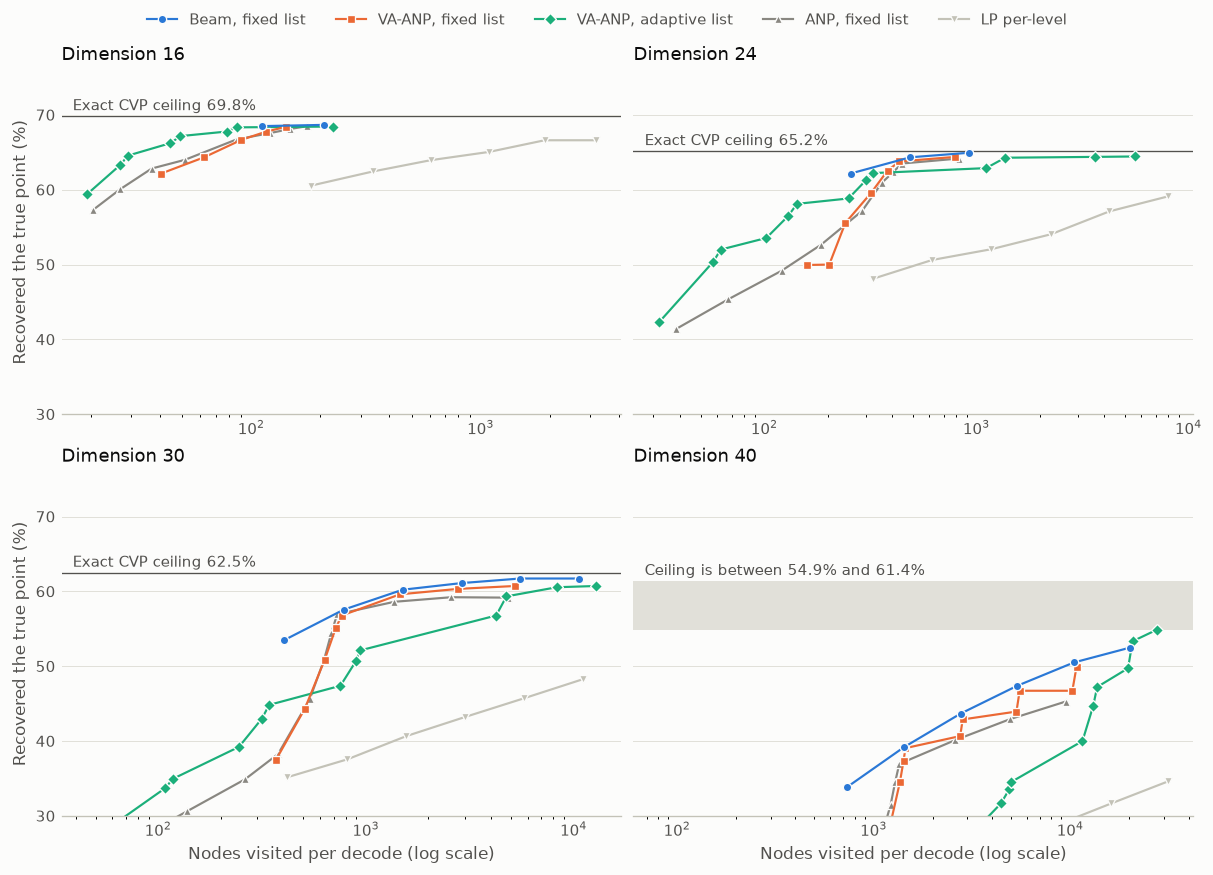

In [8]:
SERIES = {"beam": ("Beam, fixed list", "#2a78d6", "o"), "va": ("VA-ANP, fixed list", "#eb6834", "s"),
          "va_T": ("VA-ANP, adaptive list", "#1baf7a", "D"), "anp": ("ANP, fixed list", "#898781", "^"),
          "lp": ("LP per-level", "#c3c2b7", "v")}
INK, GRID, AXIS, SURFACE = "#52514e", "#e1e0d9", "#c3c2b7", "#fcfcfb"


def frontier(rows, kind):
    """The settings a tuner would choose: as nodes grow, only those that raise tuning accuracy.
    Plotted at their held-out accuracy."""
    out, best = [], -1.0
    for r in sorted((r for r in rows if r["kind"] == kind), key=lambda r: r["nodes"]):
        if r["tune_acc"] > best:
            best = r["tune_acc"]
            out.append(r)
    return out


fig, axes = plt.subplots(2, 2, figsize=(10, 7.2), dpi=120, sharey=True, constrained_layout=True, facecolor=SURFACE)
for ax, d in zip(axes.flat, FULL):
    ax.set_facecolor(SURFACE)
    for kind, (label, color, marker) in reversed(SERIES.items()):
        f = frontier(d["rows"], kind)
        ax.plot([r["nodes"] for r in f], [r["test_acc"] for r in f], color=color, marker=marker, markersize=5,
                markeredgecolor=SURFACE, markeredgewidth=0.8, linewidth=1.3, label=label)
    if d["ceiling"] is not None:
        ax.axhline(d["ceiling"], color=INK, linewidth=0.8, zorder=0)
        ax.text(0.02, d["ceiling"] + 0.8, f"Exact CVP ceiling {d['ceiling']:.1f}%", transform=ax.get_yaxis_transform(),
                color=INK, fontsize=9)
    else:
        low = max(r["test_acc"] for r in d["rows"])
        ax.axhspan(low, d["ceiling_upper"], color=GRID, zorder=0, linewidth=0)
        ax.text(0.02, d["ceiling_upper"] + 0.8, f"Ceiling is between {low:.1f}% and {d['ceiling_upper']:.1f}%",
                transform=ax.get_yaxis_transform(), color=INK, fontsize=9)
    ax.set_xscale("log")
    ax.set_ylim(30, 76)
    ax.set_title(f"Dimension {d['dim']}", loc="left", color="#0b0b0b", fontsize=11)
    ax.grid(True, axis="y", color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)
    ax.tick_params(colors=INK, labelsize=9, length=0)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(AXIS)
for ax in axes[:, 0]:
    ax.set_ylabel("Recovered the true point (%)", color=INK, fontsize=10)
for ax in axes[1]:
    ax.set_xlabel("Nodes visited per decode (log scale)", color=INK, fontsize=10)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles[::-1], labels[::-1], loc="outside upper center", ncol=5, frameon=False, fontsize=9, labelcolor=INK)
plt.show()

Up and to the left is better. Points below 30% are off the chart. The tables below hold the same results as numbers.

### Ceiling, and what each decoder can reach

In [9]:
rows = []
for d in FULL:
    best = {k: max((r for r in d["rows"] if r["kind"] == k), key=lambda r: r["test_acc"]) for k in ("beam", "va", "va_T", "anp", "lp")}
    ceil = f"{d['ceiling']:.1f}%" if d["ceiling"] is not None else f"unknown ({d['exact_tried'] - d['exact_solved']} of {d['exact_tried']} over the search limit)"
    rows.append([d["dim"], ceil, f"{d['ceiling_upper']:.1f}%", *[f"{best[k]['test_acc']:.1f}%" for k in best],
                 "n/a" if best["beam"]["closest"] is None else f"{best['beam']['closest']:.1f}%"])
table(["Dim", "Exact CVP ceiling", "Upper bound from decoders", "Best Beam", "Best VA-ANP fixed", "Best VA-ANP adaptive", "Best ANP", "Best LP per-level", "Best Beam: found closest point"], rows)

| Dim | Exact CVP ceiling | Upper bound from decoders | Best Beam | Best VA-ANP fixed | Best VA-ANP adaptive | Best ANP | Best LP per-level | Best Beam: found closest point |
|---|---|---|---|---|---|---|---|---|
| 16 | 69.8% | 68.7% | 68.7% | 68.4% | 68.4% | 68.6% | 66.6% | 100.0% |
| 24 | 65.2% | 65.2% | 65.0% | 64.4% | 64.4% | 64.2% | 59.1% | 98.3% |
| 30 | 62.5% | 61.8% | 61.7% | 60.7% | 60.7% | 59.2% | 48.3% | 95.5% |
| 40 | unknown (282 of 600 over the search limit) | 61.4% | 52.5% | 49.9% | 54.9% | 45.3% | 34.6% | n/a |

The upper bound counts the targets where no decoder found a point closer than the true one, so exact CVP can't score above it. "Best" is the highest held-out score across all settings, so it's descriptive only and isn't a tuned result. The tables below use tuned settings.

At dimension 40 exact search finished only the easier targets, so a ceiling from those would be too high. The benchmark's log line printing 99.4% there is that biased figure, and it isn't used here.

### Cost of each decoder at the same target

Cheapest setting that reaches the target on tuning data: nodes and accuracy on held-out data, then time per decode. The target is a set number of points below the best tuning accuracy at that dimension.

In [10]:
for mk, points in (("0.01", 1), ("0.03", 3)):
    fams = list(FULL[0]["margins"][mk]["picks"])
    rows = []
    for f in fams:
        row = [f]
        for d in FULL:
            m = d["margins"][mk]
            p = m["picks"][f]
            row.append("cannot reach" if p is None else f"{p['nodes']:,.0f} nodes, {p['test_acc']:.1f}%, {m['ms'][f]:.1f} ms")
        rows.append(row)
    rows.insert(0, ["Target"] + [f"{d['margins'][mk]['target']:.1f}%" for d in FULL])
    display(Markdown(f"**Within {points} point(s) of the best tuning accuracy**"))
    table(["Decoder"] + [f"Dim {d['dim']}" for d in FULL], rows)

**Within 1 point(s) of the best tuning accuracy**

| Decoder | Dim 16 | Dim 24 | Dim 30 | Dim 40 |
|---|---|---|---|---|
| Target | 67.7% | 62.0% | 61.9% | 53.4% |
| ANP fixed list | 147 nodes, 68.1%, 3.0 ms | 823 nodes, 64.2%, 4.8 ms | cannot reach | cannot reach |
| Beam fixed list | 111 nodes, 68.5%, 2.9 ms | 487 nodes, 64.3%, 4.3 ms | 5,535 nodes, 61.7%, 8.1 ms | cannot reach |
| LP per-level | cannot reach | cannot reach | cannot reach | cannot reach |
| VA-ANP fixed list | 116 nodes, 67.8%, 2.6 ms | cannot reach | cannot reach | cannot reach |
| VA-ANP adaptive | 86 nodes, 68.3%, 2.8 ms | cannot reach | cannot reach | cannot reach |
| ANP adaptive | 145 nodes, 68.2%, 3.2 ms | cannot reach | cannot reach | cannot reach |
| Beam adaptive | 86 nodes, 68.3%, 3.0 ms | 1,308 nodes, 64.6%, 5.0 ms | 7,780 nodes, 61.4%, 9.4 ms | 26,529 nodes, 54.3%, 25.6 ms |

**Within 3 point(s) of the best tuning accuracy**

| Decoder | Dim 16 | Dim 24 | Dim 30 | Dim 40 |
|---|---|---|---|---|
| Target | 65.7% | 60.0% | 59.9% | 51.4% |
| ANP fixed list | 86 nodes, 66.7%, 2.6 ms | 404 nodes, 62.3%, 5.5 ms | cannot reach | cannot reach |
| Beam fixed list | 111 nodes, 68.5%, 2.8 ms | 255 nodes, 62.2%, 5.3 ms | 1,503 nodes, 60.2%, 6.0 ms | 20,223 nodes, 52.5%, 19.9 ms |
| LP per-level | 1,900 nodes, 66.6%, 3.1 ms | cannot reach | cannot reach | cannot reach |
| VA-ANP fixed list | 91 nodes, 66.7%, 2.5 ms | 381 nodes, 62.6%, 5.0 ms | 2,771 nodes, 60.3%, 7.0 ms | cannot reach |
| VA-ANP adaptive | 44 nodes, 66.2%, 2.7 ms | 1,111 nodes, 62.9%, 6.1 ms | 8,299 nodes, 60.6%, 10.2 ms | 20,758 nodes, 53.3%, 22.2 ms |
| ANP adaptive | 37 nodes, 66.1%, 3.1 ms | 615 nodes, 62.4%, 6.0 ms | cannot reach | cannot reach |
| Beam adaptive | 49 nodes, 67.2%, 2.7 ms | 1,308 nodes, 64.6%, 6.3 ms | 4,149 nodes, 59.8%, 7.5 ms | 18,793 nodes, 52.7%, 19.4 ms |

### Success rule, set before the run

**VA-ANP adaptive must use at least 1.5x fewer nodes than the best tuned baseline at dimensions 30 and 40, on held-out data, with no significant accuracy loss (Bonferroni alpha 0.0083, overall and at each noise level).**

A nodes ratio above 1 means VA-ANP adaptive used fewer nodes. Where ANP can't reach the target, read Beam as tuned ANP, since Beam is ANP with threshold 0. Dimensions 16 and 24 are shown for context and aren't part of the rule.

In [11]:
rows = []
for d in FULL:
    for mk, points in (("0.01", 1), ("0.03", 3)):
        m = d["margins"][mk]
        if m["picks"]["VA-ANP adaptive"] is None:
            rows.append([d["dim"], points, "any", "cannot reach target", "", "", "FAIL"])
            continue
        comparisons = dict(m["vs"])
        if "vs_anp_adaptive" in m:
            comparisons["ANP adaptive"] = m["vs_anp_adaptive"]
        for base, c in comparisons.items():
            rows.append([d["dim"], points, base, f"{c['ratio']:.2f}x ({c['ratio_ci'][0]:.2f}-{c['ratio_ci'][1]:.2f})",
                         f"{c['base_acc']:.1f}% vs {c['va_acc']:.1f}%", "yes" if c["significant_loss"] else "no",
                         "PASS" if c["passes_rule"] else "FAIL"])
table(["Dim", "Points below best", "Baseline", "Nodes ratio (95% CI)", "Accuracy, baseline vs VA-ANP adaptive", "Significant loss", "Rule"], rows)

| Dim | Points below best | Baseline | Nodes ratio (95% CI) | Accuracy, baseline vs VA-ANP adaptive | Significant loss | Rule |
|---|---|---|---|---|---|---|
| 16 | 1 | ANP fixed list | 1.70x (1.62-1.78) | 68.1% vs 68.3% | no | PASS |
| 16 | 1 | Beam fixed list | 1.28x (1.22-1.35) | 68.5% vs 68.3% | no | FAIL |
| 16 | 1 | ANP adaptive | 1.67x (1.63-1.72) | 68.2% vs 68.3% | no | PASS |
| 16 | 3 | ANP fixed list | 1.94x (1.87-2.01) | 66.7% vs 66.2% | yes | FAIL |
| 16 | 3 | Beam fixed list | 2.50x (2.39-2.61) | 68.5% vs 66.2% | yes | FAIL |
| 16 | 3 | LP per-level | 42.82x (39.72-45.76) | 66.6% vs 66.2% | no | PASS |
| 16 | 3 | ANP adaptive | 0.84x (0.82-0.86) | 66.1% vs 66.2% | yes | FAIL |
| 24 | 1 | any | cannot reach target |  |  | FAIL |
| 24 | 3 | ANP fixed list | 0.36x (0.34-0.39) | 62.3% vs 62.9% | yes | FAIL |
| 24 | 3 | Beam fixed list | 0.23x (0.21-0.24) | 62.2% vs 62.9% | yes | FAIL |
| 24 | 3 | ANP adaptive | 0.55x (0.53-0.57) | 62.4% vs 62.9% | yes | FAIL |
| 30 | 1 | any | cannot reach target |  |  | FAIL |
| 30 | 3 | Beam fixed list | 0.18x (0.18-0.19) | 60.2% vs 60.6% | yes | FAIL |
| 40 | 1 | any | cannot reach target |  |  | FAIL |
| 40 | 3 | Beam fixed list | 0.97x (0.97-0.98) | 52.5% vs 53.3% | yes | FAIL |

### Per noise level, against the same pooled picks

Each decoder keeps one setting across all three noise levels. Below: Beam against VA-ANP adaptive, at the 3-point target.

In [12]:
rows = []
for d in FULL:
    m = d["margins"]["0.03"]
    c = m.get("vs", {}).get("Beam fixed list")
    if c is None:
        continue
    for noise, n in c["noise"].items():
        rows.append([d["dim"], noise, f"{n['base_acc']:.1f}% vs {n['va_acc']:.1f}%", f"{n['ratio']:.2f}x",
                     f"{n['base_only']}/{n['va_only']}", f"{n['p']:.4f}"])
table(["Dim", "Noise", "Accuracy, Beam vs VA-ANP adaptive", "Beam nodes / VA-ANP nodes", "Beam-only / VA-only wins", "p"], rows)

| Dim | Noise | Accuracy, Beam vs VA-ANP adaptive | Beam nodes / VA-ANP nodes | Beam-only / VA-only wins | p |
|---|---|---|---|---|---|
| 16 | 0.18 | 98.5% vs 95.2% | 6.37x | 21/1 | 0.0000 |
| 16 | 0.24 | 77.3% vs 73.8% | 3.60x | 31/10 | 0.0014 |
| 16 | 0.3 | 29.7% vs 29.7% | 1.31x | 5/5 | 1.0000 |
| 24 | 0.18 | 98.5% vs 95.0% | 5.53x | 22/1 | 0.0000 |
| 24 | 0.24 | 69.2% vs 72.0% | 0.70x | 20/37 | 0.0331 |
| 24 | 0.3 | 18.8% vs 21.7% | 0.09x | 6/23 | 0.0023 |
| 30 | 0.18 | 99.5% vs 97.3% | 6.08x | 14/1 | 0.0010 |
| 30 | 0.24 | 67.2% vs 70.3% | 0.32x | 10/29 | 0.0034 |
| 30 | 0.3 | 14.0% vs 14.0% | 0.08x | 14/14 | 1.0000 |
| 40 | 0.18 | 97.0% vs 91.7% | 12.15x | 34/2 | 0.0000 |
| 40 | 0.24 | 54.7% vs 60.7% | 0.84x | 13/49 | 0.0000 |
| 40 | 0.3 | 5.8% vs 7.7% | 0.55x | 1/12 | 0.0034 |

### Follow-up: each decoder tuned for each noise level

A real attack knows its noise level, so one setting across three noise levels isn't the fair test. Here each decoder is retuned at each noise level, on tuning data, and scored on held-out data (600 targets per level). This follow-up was added after the rule failed, so it's a separate result that can't reverse the rule. The 1.5x bar and alpha 0.0083 are the same.

In [13]:
for margin, points in ((0.01, 1), (0.03, 3)):
    rows = []
    for r in (x for x in BY_NOISE if x["margin"] == margin):
        cell = lambda p: "cannot reach" if p is None else f"{p['nodes']:,.0f}, {p['test_acc']:.1f}%"
        verdict = lambda k: (lambda c: "n/a" if c is None else f"{c['ratio']:.2f}x {'PASS' if c['passes'] else 'FAIL'}")(r["vs"].get(k))
        rows.append([r["dim"], r["noise"], f"{r['target']:.1f}%", *[cell(r["picks"].get(f)) for f in
                     ("Beam fixed list", "ANP fixed list", "VA-ANP fixed list", "VA-ANP adaptive", "Beam adaptive")],
                     verdict("VA-ANP fixed list vs Beam fixed list"), verdict("VA-ANP adaptive vs Beam fixed list"),
                     verdict("VA-ANP fixed list vs ANP fixed list"), verdict("VA-ANP adaptive vs ANP fixed list")])
    display(Markdown(f"**Within {points} point(s) of the best tuning accuracy at that noise level** (cells: nodes, held-out accuracy)"))
    table(["Dim", "Noise", "Target", "Beam", "ANP", "VA-ANP fixed", "VA-ANP adaptive", "Beam adaptive",
           "VA fixed vs Beam", "VA adaptive vs Beam", "VA fixed vs ANP", "VA adaptive vs ANP"], rows)

**Within 1 point(s) of the best tuning accuracy at that noise level** (cells: nodes, held-out accuracy)

| Dim | Noise | Target | Beam | ANP | VA-ANP fixed | VA-ANP adaptive | Beam adaptive | VA fixed vs Beam | VA adaptive vs Beam | VA fixed vs ANP | VA adaptive vs ANP |
|---|---|---|---|---|---|---|---|---|---|---|---|
| 16 | 0.18 | 97.8% | 59, 98.3% | 46, 98.2% | cannot reach | cannot reach | 24, 98.5% | n/a | n/a | n/a | n/a |
| 16 | 0.24 | 73.2% | 111, 77.3% | 52, 75.5% | 81, 76.2% | 51, 76.8% | 51, 76.8% | 1.37x FAIL | 2.19x PASS | 0.64x FAIL | 1.02x FAIL |
| 16 | 0.3 | 32.0% | 111, 29.7% | 95, 29.2% | 78, 27.7% | 96, 30.2% | 96, 30.2% | 1.43x FAIL | 1.16x FAIL | 1.22x FAIL | 0.99x FAIL |
| 30 | 0.18 | 98.7% | 1,503, 99.5% | cannot reach | cannot reach | cannot reach | 1,396, 99.7% | n/a | n/a | n/a | n/a |
| 30 | 0.24 | 73.2% | 10,591, 71.5% | cannot reach | 5,567, 70.5% | 4,754, 70.3% | 4,954, 71.0% | 1.90x PASS | 2.23x PASS | n/a | n/a |
| 30 | 0.3 | 14.5% | 5,535, 14.2% | cannot reach | 5,737, 14.3% | 12,534, 13.8% | 10,701, 13.7% | 0.96x FAIL | 0.44x FAIL | n/a | n/a |
| 40 | 0.18 | 96.3% | 20,223, 97.0% | cannot reach | cannot reach | cannot reach | 10,272, 97.0% | n/a | n/a | n/a | n/a |
| 40 | 0.24 | 59.0% | cannot reach | cannot reach | cannot reach | 24,093, 60.7% | cannot reach | n/a | n/a | n/a | n/a |
| 40 | 0.3 | 6.3% | cannot reach | cannot reach | cannot reach | 28,293, 7.3% | 26,828, 7.0% | n/a | n/a | n/a | n/a |

**Within 3 point(s) of the best tuning accuracy at that noise level** (cells: nodes, held-out accuracy)

| Dim | Noise | Target | Beam | ANP | VA-ANP fixed | VA-ANP adaptive | Beam adaptive | VA fixed vs Beam | VA adaptive vs Beam | VA fixed vs ANP | VA adaptive vs ANP |
|---|---|---|---|---|---|---|---|---|---|---|---|
| 16 | 0.18 | 95.8% | 31, 97.5% | 32, 97.8% | 25, 95.5% | 18, 96.5% | 18, 96.5% | 1.23x FAIL | 1.75x PASS | 1.27x FAIL | 1.81x FAIL |
| 16 | 0.24 | 71.2% | 59, 75.5% | 52, 75.5% | 49, 75.0% | 34, 74.8% | 34, 74.8% | 1.21x FAIL | 1.75x PASS | 1.06x FAIL | 1.53x PASS |
| 16 | 0.3 | 30.0% | 59, 28.0% | 47, 27.3% | 48, 27.2% | 46, 27.8% | 46, 27.8% | 1.22x FAIL | 1.27x FAIL | 0.97x FAIL | 1.02x FAIL |
| 30 | 0.18 | 96.7% | 781, 99.0% | 721, 98.5% | cannot reach | cannot reach | 350, 99.5% | n/a | n/a | n/a | n/a |
| 30 | 0.24 | 71.2% | 2,887, 70.2% | cannot reach | 2,910, 69.7% | 4,754, 70.3% | 4,954, 71.0% | 0.99x FAIL | 0.61x FAIL | n/a | n/a |
| 30 | 0.3 | 12.5% | 1,503, 14.0% | 2,599, 13.3% | 796, 11.8% | 1,886, 13.0% | 2,114, 13.5% | 1.89x FAIL | 0.80x FAIL | 3.26x PASS | 1.38x FAIL |
| 40 | 0.18 | 94.3% | 5,375, 95.5% | cannot reach | cannot reach | cannot reach | 1,964, 93.8% | n/a | n/a | n/a | n/a |
| 40 | 0.24 | 57.0% | cannot reach | cannot reach | cannot reach | 24,093, 60.7% | 21,677, 57.3% | n/a | n/a | n/a | n/a |
| 40 | 0.3 | 4.3% | 5,375, 4.5% | 8,722, 2.8% | 5,721, 4.8% | 11,706, 5.5% | 10,424, 5.2% | 0.94x FAIL | 0.46x FAIL | 1.52x PASS | 0.75x FAIL |

**The PASS rows at dimensions 30 and 40 don't hold up:**

- **Dimension 30, noise 0.24, 1-point target (both VA-ANP rows).** Beam's list only doubles between settings, so it jumped to 16n to clear a target its 8n list missed on tuning. It then scored 71.5% on held-out, above VA-ANP adaptive's 70.3%. At 4n, Beam scores 70.2% on held-out with 2,887 nodes, while VA-ANP adaptive needs 4,754 for 70.3%.
- **Dimension 30, noise 0.30, and dimension 40, noise 0.30 (VA-ANP fixed vs ANP).** Accuracy is under 15% here. Beam at those targets beats ANP, and it uses fewer nodes than VA-ANP at dimension 40. At dimension 30, VA-ANP's lower node count comes with a significant accuracy loss against Beam.

### The one case where VA-ANP adaptive led: dimension 40, noise 0.24

In the tables above, only VA-ANP adaptive reached the top target here. This test checks why, on the same lattices and targets (600 tuning, 600 held-out), with longer lists and a third plane for Beam. Wins are counted against VA-ANP adaptive with `llr=4`, `T=8`.

In [14]:
table(["Setting", "Tuning", "Held-out", "Nodes", "This-only / VA-only wins", "p"],
      [[r["cfg"], f"{r['tune_acc']:.1f}%", f"{r['test_acc']:.1f}%", f"{r['nodes']:,.0f}", f"{r['this_only']}/{r['va_only']}", f"{r['p']:.4f}"]
       for r in sorted(PLANES, key=lambda r: r["nodes"])])

| Setting | Tuning | Held-out | Nodes | This-only / VA-only wins | p |
|---|---|---|---|---|---|
| ('va_T', 4.0, 6) | 48.5% | 50.2% | 10,312 | 5/68 | 0.0000 |
| ('beam', 2, 8) | 45.8% | 49.2% | 10,431 | 10/79 | 0.0000 |
| ('beam3_T', 6) | 49.0% | 51.3% | 10,690 | 12/68 | 0.0000 |
| ('va', 4.0, 8) | 46.8% | 49.3% | 11,012 | 6/74 | 0.0000 |
| ('beam', 3, 8) | 47.2% | 50.5% | 11,244 | 13/74 | 0.0000 |
| ('beam', 2, 16) | 53.2% | 54.7% | 20,223 | 13/49 | 0.0000 |
| ('va', 4.0, 16) | 54.5% | 56.3% | 21,512 | 9/35 | 0.0001 |
| ('beam_T', 8) | 57.0% | 57.3% | 21,677 | 7/27 | 0.0008 |
| ('beam', 3, 16) | 55.0% | 57.5% | 22,124 | 17/36 | 0.0127 |
| ('va_T', 4.0, 8) | 59.0% | 60.7% | 24,093 | 0/0 | 1.0000 |
| ('beam3_T', 8) | 59.7% | 61.5% | 24,872 | 9/4 | 0.2668 |
| ('beam_T', 12) | 58.8% | 59.0% | 31,139 | 19/29 | 0.1934 |
| ('va_T', 4.0, 12) | 60.0% | 62.7% | 33,670 | 14/2 | 0.0042 |
| ('beam3_T', 12) | 60.7% | 63.3% | 34,896 | 20/4 | 0.0015 |
| ('beam', 2, 32) | 59.0% | 59.0% | 39,167 | 19/29 | 0.1934 |
| ('va', 4.0, 32) | 60.2% | 62.7% | 41,961 | 14/2 | 0.0042 |
| ('beam', 3, 32) | 60.8% | 63.3% | 43,333 | 20/4 | 0.0015 |
| ('beam', 2, 64) | 62.0% | 61.3% | 75,775 | 34/30 | 0.7080 |
| ('va', 4.0, 64) | 64.3% | 65.2% | 81,722 | 34/7 | 0.0000 |
| ('beam', 3, 64) | 66.7% | 66.7% | 85,200 | 46/10 | 0.0000 |

### Code speed, separate from the algorithm

The same decoders with the same settings as the original notebook: its Python loops against the matrix version in this notebook. They return the same points on 300 instances per dimension (asserted in the benchmark). Every decoder gets this gain, so it isn't a VA-ANP result.

In [15]:
rows = []
for d in FULL:
    row = [d["dim"]]
    for name in ("VA-ANP", "ANP", "Beam k=2"):
        s = d["speed"][name]
        row.append(f"{s['original_ms']:.1f} to {s['vectorized_ms']:.1f} ms ({s['speedup']:.2f}x)")
    rows.append(row)
table(["Dim", "VA-ANP", "ANP", "Beam"], rows)

| Dim | VA-ANP | ANP | Beam |
|---|---|---|---|
| 16 | 4.3 to 3.0 ms (1.45x) | 11.1 to 3.3 ms (3.36x) | 15.7 to 3.2 ms (4.87x) |
| 24 | 15.6 to 4.2 ms (3.70x) | 27.4 to 4.7 ms (5.90x) | 33.8 to 4.7 ms (7.26x) |
| 30 | 34.0 to 6.3 ms (5.37x) | 48.0 to 6.4 ms (7.54x) | 56.9 to 6.1 ms (9.34x) |
| 40 | 78.9 to 8.7 ms (9.09x) | 87.2 to 9.2 ms (9.53x) | 102.3 to 9.1 ms (11.21x) |

Times on this laptop moved by up to about 3x between runs, so use the ratios within one row and not absolute times. Nodes stay the main cost.

## 6. Toy LWE instances

Sections 4 and 5 used random q-ary lattices with noise scaled to the basis. This section runs the same decoders as the last step of a primal attack on small LWE instances, with fixed noise and LLL or BKZ bases, and measures how often the secret is recovered.

**Instance.** `b = A s + e mod q`, with q = 3329, `A` uniform `n x n` (so m = n samples), and `s`, `e` centered binomial with eta = 2 (sigma = 1). The lattice is `{(y, x) : x = A y mod q}` of dimension 2n, and the target is `(0, b)`. The point `(s, A s mod q)` is at offset `(-s, e)`, so success means the decoder's point gives exactly `s`. The planted point is far closer than any other, so the best possible recovery is 100%, and there is no exact-CVP ceiling to estimate.

**Toy parameters only.** In ML-KEM-512 the secret and error each have 512 coefficients (two polynomials of degree 256), with eta = 3. These instances are far smaller, solvable on a laptop, and say nothing about ML-KEM's security.

**How it ran.** `toy_lwe_test.py` builds the instances and reduces them with fplll 0.6.4 in WSL (LLL, then BKZ-10 or BKZ-20 without pruning strategies). Decoding ran on the GPU through `toy_lwe_gpu.py`, which returns the same points and node counts as the CPU decoders in `va_anp_v2.py` (checked on 216 decodes). Nodes are the cost, as in section 5. Before the pilot: the code passed checks against fplll's exact CVP, a negative control with uniform `b`, and an easy positive control. No decoder returned a wrong point closer than the true one, or a point outside the lattice.

**Rule, set before any run** (in the docstring of `toy_lwe_test.py`):

- **Settings.** For each reduction, two values of n from the pilot: "at the edge" (Babai closest to 50%) and "past Babai" (Babai at most 10% and some list decoder at least 10%; the largest such n).
- **Selection.** On 6 tuning lattices per setting, each family's cheapest configuration (mean nodes) within 3 points of the best recovery any family reaches there.
- **Test.** Scored once on 16 held-out lattices per setting (400 targets), with McNemar's exact test, Bonferroni-corrected across all 24 comparisons.
- **Q1.** Does the strongest list decoder recover significantly more secrets than Babai?
- **Q2.** VA-ANP adaptive wins against a baseline at a setting if it uses at least 1.5x fewer nodes with no significant loss of recovery. Baselines: Beam fixed list, Beam adaptive, and per-level Lindner-Peikert. It passes only if it wins against all three at most settings.

In [16]:
PILOT = json.loads(r"""[{"beta":2,"n":40,"lattices":4,"targets":100,"reduce_s":1.21089,"gs_min":12.5442,"formula":100.0,"bad":0,"rec":{"Babai":[100.0,80.0],"Beam fixed list, 8d":[100.0,45823.0],"Beam k=3 adaptive, T=16":[100.0,80.0],"VA-ANP adaptive, T=16":[100.0,80.0],"LP per-level, 1024":[100.0,72319.0]}},
{"beta":2,"n":50,"lattices":4,"targets":100,"reduce_s":3.15522,"gs_min":7.72877,"formula":99.97042,"bad":0,"rec":{"Babai":[100.0,100.0],"Beam fixed list, 8d":[100.0,73023.0],"Beam k=3 adaptive, T=16":[100.0,100.33],"VA-ANP adaptive, T=16":[100.0,100.0],"LP per-level, 1024":[100.0,93183.0]}},
{"beta":2,"n":60,"lattices":4,"targets":100,"reduce_s":8.21921,"gs_min":5.17761,"formula":94.14981,"bad":0,"rec":{"Babai":[95.0,120.0],"Beam fixed list, 8d":[100.0,106623.0],"Beam k=3 adaptive, T=16":[100.0,222.04],"VA-ANP adaptive, T=16":[100.0,133.44],"LP per-level, 1024":[100.0,113343.0]}},
{"beta":2,"n":70,"lattices":4,"targets":100,"reduce_s":7.89753,"gs_min":3.35842,"formula":47.5317,"bad":0,"rec":{"Babai":[57.0,140.0],"Beam fixed list, 8d":[100.0,146527.0],"Beam k=3 adaptive, T=16":[100.0,8371.61],"VA-ANP adaptive, T=16":[97.0,2015.06],"LP per-level, 1024":[92.0,134015.0]}},
{"beta":2,"n":80,"lattices":4,"targets":100,"reduce_s":12.33326,"gs_min":1.88508,"formula":1.73808,"bad":0,"rec":{"Babai":[2.0,160.0],"Beam fixed list, 8d":[46.0,192767.0],"Beam k=3 adaptive, T=16":[70.0,144532.08],"VA-ANP adaptive, T=16":[68.0,139721.56],"LP per-level, 1024":[19.0,154495.0]}},
{"beta":2,"n":90,"lattices":4,"targets":100,"reduce_s":18.20249,"gs_min":1.31017,"formula":0.00294,"bad":0,"rec":{"Babai":[0.0,180.0],"Beam fixed list, 8d":[0.0,245407.0],"Beam k=3 adaptive, T=16":[2.0,229577.64],"VA-ANP adaptive, T=16":[2.0,228525.48],"LP per-level, 1024":[0.0,174527.0]}},
{"beta":2,"n":100,"lattices":4,"targets":100,"reduce_s":39.24121,"gs_min":0.87631,"formula":0.0,"bad":0,"rec":{"Babai":[0.0,200.0],"Beam fixed list, 8d":[0.0,304447.0],"Beam k=3 adaptive, T=16":[0.0,320388.66],"VA-ANP adaptive, T=16":[0.0,319157.73],"LP per-level, 1024":[0.0,195071.0]}},
{"beta":2,"n":110,"lattices":1,"targets":25,"reduce_s":139.37125,"gs_min":0.63603,"formula":0.0,"bad":0,"rec":{"Babai":[0.0,220.0],"Beam fixed list, 8d":[0.0,369887.0],"Beam k=3 adaptive, T=16":[0.0,413057.28],"VA-ANP adaptive, T=16":[0.0,411855.44],"LP per-level, 1024":[0.0,216063.0]}},
{"beta":10,"n":60,"lattices":4,"targets":100,"reduce_s":10.05069,"gs_min":8.49082,"formula":99.99412,"bad":0,"rec":{"Babai":[100.0,120.0],"Beam fixed list, 8d":[100.0,106623.0],"Beam k=3 adaptive, T=16":[100.0,120.04],"VA-ANP adaptive, T=16":[100.0,120.0],"LP per-level, 1024":[100.0,113663.0]}},
{"beta":10,"n":70,"lattices":4,"targets":100,"reduce_s":10.27494,"gs_min":5.70431,"formula":98.12625,"bad":0,"rec":{"Babai":[99.0,140.0],"Beam fixed list, 8d":[100.0,146527.0],"Beam k=3 adaptive, T=16":[100.0,162.57],"VA-ANP adaptive, T=16":[100.0,141.94],"LP per-level, 1024":[100.0,134143.0]}},
{"beta":10,"n":80,"lattices":4,"targets":100,"reduce_s":36.02442,"gs_min":3.88968,"formula":67.77094,"bad":0,"rec":{"Babai":[74.0,160.0],"Beam fixed list, 8d":[100.0,192767.0],"Beam k=3 adaptive, T=16":[100.0,1987.59],"VA-ANP adaptive, T=16":[99.0,532.1],"LP per-level, 1024":[95.0,154239.0]}},
{"beta":10,"n":90,"lattices":4,"targets":100,"reduce_s":45.86752,"gs_min":2.4421,"formula":8.35921,"bad":0,"rec":{"Babai":[6.0,180.0],"Beam fixed list, 8d":[95.0,245407.0],"Beam k=3 adaptive, T=16":[100.0,143249.53],"VA-ANP adaptive, T=16":[92.0,119434.65],"LP per-level, 1024":[50.0,174975.0]}},
{"beta":10,"n":100,"lattices":4,"targets":100,"reduce_s":50.49765,"gs_min":1.65438,"formula":0.0463,"bad":0,"rec":{"Babai":[0.0,200.0],"Beam fixed list, 8d":[8.0,304447.0],"Beam k=3 adaptive, T=16":[17.0,261408.62],"VA-ANP adaptive, T=16":[18.0,259919.27],"LP per-level, 1024":[3.0,195583.0]}},
{"beta":10,"n":110,"lattices":4,"targets":100,"reduce_s":77.53815,"gs_min":1.12941,"formula":1e-05,"bad":0,"rec":{"Babai":[0.0,220.0],"Beam fixed list, 8d":[0.0,369887.0],"Beam k=3 adaptive, T=16":[0.0,364436.51],"VA-ANP adaptive, T=16":[0.0,362880.91],"LP per-level, 1024":[0.0,215679.0]}},
{"beta":10,"n":120,"lattices":3,"targets":75,"reduce_s":183.66298,"gs_min":0.71782,"formula":0.0,"bad":0,"rec":{"Babai":[0.0,240.0],"Beam fixed list, 8d":[0.0,441727.0],"Beam k=3 adaptive, T=16":[0.0,483289.77333],"VA-ANP adaptive, T=16":[0.0,481544.77333],"LP per-level, 1024":[0.0,236543.0]}},
{"beta":20,"n":90,"lattices":4,"targets":100,"reduce_s":43.61991,"gs_min":3.30826,"formula":48.79399,"bad":0,"rec":{"Babai":[49.0,180.0],"Beam fixed list, 8d":[100.0,245407.0],"Beam k=3 adaptive, T=16":[100.0,8589.6],"VA-ANP adaptive, T=16":[99.0,2216.01],"LP per-level, 1024":[86.0,175103.0]}},
{"beta":20,"n":100,"lattices":4,"targets":100,"reduce_s":44.22189,"gs_min":2.27769,"formula":3.98045,"bad":0,"rec":{"Babai":[6.0,200.0],"Beam fixed list, 8d":[83.0,304447.0],"Beam k=3 adaptive, T=16":[93.0,189758.29],"VA-ANP adaptive, T=16":[84.0,171337.23],"LP per-level, 1024":[28.0,195199.0]}},
{"beta":20,"n":110,"lattices":4,"targets":100,"reduce_s":103.04352,"gs_min":1.59293,"formula":0.01258,"bad":0,"rec":{"Babai":[0.0,220.0],"Beam fixed list, 8d":[4.0,369887.0],"Beam k=3 adaptive, T=16":[5.0,322208.33],"VA-ANP adaptive, T=16":[5.0,320467.18],"LP per-level, 1024":[0.0,215935.0]}},
{"beta":20,"n":120,"lattices":3,"targets":75,"reduce_s":181.19418,"gs_min":1.05011,"formula":0.0,"bad":0,"rec":{"Babai":[0.0,240.0],"Beam fixed list, 8d":[0.0,441727.0],"Beam k=3 adaptive, T=16":[0.0,444657.66667],"VA-ANP adaptive, T=16":[0.0,442762.01333],"LP per-level, 1024":[0.0,236543.0]}}]""")
LWE = json.loads(r"""{"settings":[{"beta":2,"n":70,"best_tune":100.0,"target":97.0,"families":{"Babai":null,"Beam fixed list":{"cfg":"('beam', 2, 1)","tune":98.66667,"held_out":98.75,"nodes":18735.0,"ms":11.16114},"Beam k=3 fixed list":{"cfg":"('beam', 3, 1)","tune":99.33333,"held_out":99.5,"nodes":19021.0,"ms":10.63825},"ANP fixed list":{"cfg":"('anp', 0.2, 2)","tune":97.33333,"held_out":98.0,"nodes":36765.37,"ms":12.84464},"VA-ANP fixed list":{"cfg":"('va', 8.0, 2)","tune":99.33333,"held_out":100.0,"nodes":37502.74,"ms":10.98358},"Beam adaptive":{"cfg":"('beam_T', 2, 12.0, 64)","tune":98.66667,"held_out":99.25,"nodes":2261.3325,"ms":6.95536},"Beam k=3 adaptive":{"cfg":"('beam_T', 3, 12.0, 64)","tune":99.33333,"held_out":100.0,"nodes":2690.135,"ms":7.49745},"VA-ANP adaptive":{"cfg":"('va_T', 8.0, 12.0, 64)","tune":99.33333,"held_out":100.0,"nodes":2529.84,"ms":8.53883},"LP per-level":null},"strongest":"('va_T', 8.0, 16.0, 64)","bad_points":0,"reduce_s":1.7133,"hit_limit":0,"gs_min":3.24363,"targets":400,"babai":44.0,"babai_formula":45.80885,"q1":{"cfg":"('va_T', 8.0, 16.0, 64)","strongest":100.0,"only_list":224,"only_babai":0,"p":0.0,"diff_ci":[52.25,59.75],"gain":true,"nodes":8708.035},"q2":{"Beam fixed list":{"ratio":7.40561,"ratio_ci":[6.04354,9.19213],"base_only":0,"va_only":5,"p":0.0625,"diff_ci":[0.0,2.75],"significant_loss":false,"win":true},"Beam adaptive":{"ratio":0.89386,"ratio_ci":[0.8721,0.91689],"base_only":0,"va_only":3,"p":0.25,"diff_ci":[0.0,1.5],"significant_loss":false,"win":false},"LP per-level":{"win":true,"why":"baseline cannot reach the target"}},"q2_all_three":false},
{"beta":2,"n":80,"best_tune":86.0,"target":83.0,"families":{"Babai":null,"Beam fixed list":null,"Beam k=3 fixed list":{"cfg":"('beam', 3, 64)","tune":86.0,"held_out":85.0,"nodes":1556081.0,"ms":147.5984},"ANP fixed list":null,"VA-ANP fixed list":null,"Beam adaptive":null,"Beam k=3 adaptive":{"cfg":"('beam_T', 3, 12.0, 64)","tune":85.33333,"held_out":84.0,"nodes":206346.81,"ms":24.61459},"VA-ANP adaptive":{"cfg":"('va_T', 8.0, 12.0, 64)","tune":85.33333,"held_out":84.0,"nodes":206186.8925,"ms":24.50554},"LP per-level":null},"strongest":"('va_T', 8.0, 16.0, 64)","bad_points":0,"reduce_s":2.95496,"hit_limit":0,"gs_min":2.08137,"targets":400,"babai":1.5,"babai_formula":2.96834,"q1":{"cfg":"('va_T', 8.0, 16.0, 64)","strongest":85.0,"only_list":334,"only_babai":0,"p":0.0,"diff_ci":[76.25,89.75],"gain":true,"nodes":269593.0575},"q2":{"Beam fixed list":{"win":true,"why":"baseline cannot reach the target"},"Beam adaptive":{"win":true,"why":"baseline cannot reach the target"},"LP per-level":{"win":true,"why":"baseline cannot reach the target"}},"q2_all_three":true},
{"beta":10,"n":80,"best_tune":100.0,"target":97.0,"families":{"Babai":null,"Beam fixed list":{"cfg":"('beam', 2, 1)","tune":100.0,"held_out":100.0,"nodes":24575.0,"ms":11.66267},"Beam k=3 fixed list":{"cfg":"('beam', 3, 1)","tune":100.0,"held_out":100.0,"nodes":24921.0,"ms":12.02892},"ANP fixed list":{"cfg":"('anp', 0.5, 2)","tune":98.0,"held_out":98.5,"nodes":46628.7475,"ms":16.13867},"VA-ANP fixed list":{"cfg":"('va', 4.0, 2)","tune":98.0,"held_out":98.0,"nodes":41776.2925,"ms":12.15062},"Beam adaptive":{"cfg":"('beam_T', 2, 4.0, 64)","tune":97.33333,"held_out":95.0,"nodes":177.04,"ms":7.9262},"Beam k=3 adaptive":{"cfg":"('beam_T', 3, 4.0, 64)","tune":97.33333,"held_out":95.0,"nodes":177.04,"ms":8.45535},"VA-ANP adaptive":{"cfg":"('va_T', 4.0, 4.0, 64)","tune":97.33333,"held_out":95.0,"nodes":177.04,"ms":8.60233},"LP per-level":{"cfg":"('lp', 4096)","tune":97.33333,"held_out":97.25,"nodes":609919.0,"ms":40.32998}},"strongest":"('va_T', 8.0, 12.0, 64)","bad_points":0,"reduce_s":11.33224,"hit_limit":0,"gs_min":3.77262,"targets":400,"babai":65.25,"babai_formula":66.84353,"q1":{"cfg":"('va_T', 8.0, 12.0, 64)","strongest":100.0,"only_list":139,"only_babai":0,"p":0.0,"diff_ci":[30.5,39.25],"gain":true,"nodes":647.285},"q2":{"Beam fixed list":{"ratio":138.81044,"ratio_ci":[137.14091,140.50083],"base_only":20,"va_only":0,"p":0.0,"diff_ci":[-7.0,-3.0],"significant_loss":true,"win":false},"Beam adaptive":{"ratio":1.0,"ratio_ci":[1.0,1.0],"base_only":0,"va_only":0,"p":1.0,"diff_ci":[0.0,0.0],"significant_loss":false,"win":false},"LP per-level":{"ratio":3445.0915,"ratio_ci":[3403.6125,3486.83419],"base_only":17,"va_only":8,"p":0.10775,"diff_ci":[-4.0,-0.75],"significant_loss":false,"win":true}},"q2_all_three":false},
{"beta":10,"n":100,"best_tune":22.66667,"target":19.66667,"families":{"Babai":null,"Beam fixed list":{"cfg":"('beam', 2, 64)","tune":20.0,"held_out":22.75,"nodes":2397183.0,"ms":223.4432},"Beam k=3 fixed list":{"cfg":"('beam', 3, 64)","tune":22.66667,"held_out":25.5,"nodes":2454641.0,"ms":255.79662},"ANP fixed list":null,"VA-ANP fixed list":null,"Beam adaptive":{"cfg":"('beam_T', 2, 16.0, 64)","tune":20.0,"held_out":22.75,"nodes":451978.8175,"ms":50.65052},"Beam k=3 adaptive":{"cfg":"('beam_T', 3, 12.0, 64)","tune":22.66667,"held_out":25.5,"nodes":452170.16,"ms":53.39746},"VA-ANP adaptive":{"cfg":"('va_T', 2.2, 12.0, 64)","tune":20.66667,"held_out":21.75,"nodes":408860.7375,"ms":46.49347},"LP per-level":null},"strongest":"('va_T', 4.0, 12.0, 64)","bad_points":0,"reduce_s":31.73053,"hit_limit":0,"gs_min":1.67394,"targets":400,"babai":0.0,"babai_formula":0.05512,"q1":{"cfg":"('va_T', 4.0, 12.0, 64)","strongest":25.25,"only_list":101,"only_babai":0,"p":0.0,"diff_ci":[20.5,30.75],"gain":true,"nodes":450038.6675},"q2":{"Beam fixed list":{"ratio":5.86308,"ratio_ci":[5.76214,5.96867],"base_only":14,"va_only":10,"p":0.54126,"diff_ci":[-3.5,1.25],"significant_loss":false,"win":true},"Beam adaptive":{"ratio":1.10546,"ratio_ci":[1.0943,1.11807],"base_only":14,"va_only":10,"p":0.54126,"diff_ci":[-3.5,1.25],"significant_loss":false,"win":false},"LP per-level":{"win":true,"why":"baseline cannot reach the target"}},"q2_all_three":false},
{"beta":20,"n":90,"best_tune":100.0,"target":97.0,"families":{"Babai":null,"Beam fixed list":{"cfg":"('beam', 2, 1)","tune":100.0,"held_out":100.0,"nodes":31215.0,"ms":13.57829},"Beam k=3 fixed list":{"cfg":"('beam', 3, 1)","tune":100.0,"held_out":100.0,"nodes":31621.0,"ms":13.89502},"ANP fixed list":{"cfg":"('anp', 0.5, 2)","tune":98.0,"held_out":94.0,"nodes":59715.845,"ms":15.73288},"VA-ANP fixed list":{"cfg":"('va', 4.0, 2)","tune":98.66667,"held_out":96.0,"nodes":59706.085,"ms":15.64137},"Beam adaptive":{"cfg":"('beam_T', 2, 8.0, 64)","tune":98.66667,"held_out":98.5,"nodes":553.855,"ms":9.96809},"Beam k=3 adaptive":{"cfg":"('beam_T', 3, 8.0, 64)","tune":98.66667,"held_out":98.5,"nodes":568.2925,"ms":9.53258},"VA-ANP adaptive":{"cfg":"('va_T', 4.0, 8.0, 64)","tune":97.33333,"held_out":94.75,"nodes":441.12,"ms":10.68742},"LP per-level":{"cfg":"('lp', 65536)","tune":97.33333,"held_out":98.25,"nodes":10807295.0,"ms":762.54813}},"strongest":"('beam_T', 2, 12.0, 64)","bad_points":0,"reduce_s":21.28742,"hit_limit":0,"gs_min":3.32514,"targets":400,"babai":49.5,"babai_formula":49.25161,"q1":{"cfg":"('beam_T', 2, 12.0, 64)","strongest":100.0,"only_list":202,"only_babai":0,"p":0.0,"diff_ci":[46.25,54.75],"gain":true,"nodes":1898.2025},"q2":{"Beam fixed list":{"ratio":70.76306,"ratio_ci":[67.81224,74.65849],"base_only":21,"va_only":0,"p":0.0,"diff_ci":[-7.75,-3.25],"significant_loss":true,"win":false},"Beam adaptive":{"ratio":1.25557,"ratio_ci":[1.244,1.26904],"base_only":15,"va_only":0,"p":6e-05,"diff_ci":[-6.0,-2.0],"significant_loss":true,"win":false},"LP per-level":{"ratio":24499.67129,"ratio_ci":[23486.82286,25843.63288],"base_only":21,"va_only":7,"p":0.01254,"diff_ci":[-6.5,-0.75],"significant_loss":false,"win":true}},"q2_all_three":false},
{"beta":20,"n":100,"best_tune":92.0,"target":89.0,"families":{"Babai":null,"Beam fixed list":null,"Beam k=3 fixed list":{"cfg":"('beam', 3, 32)","tune":90.66667,"held_out":93.25,"nodes":1232080.0,"ms":129.52744},"ANP fixed list":null,"VA-ANP fixed list":{"cfg":"('va', 8.0, 32)","tune":90.66667,"held_out":93.25,"nodes":1232045.4975,"ms":109.06379},"Beam adaptive":null,"Beam k=3 adaptive":{"cfg":"('beam_T', 3, 12.0, 64)","tune":92.0,"held_out":94.25,"nodes":234687.1625,"ms":30.35592},"VA-ANP adaptive":{"cfg":"('va_T', 8.0, 12.0, 64)","tune":92.0,"held_out":94.25,"nodes":234311.835,"ms":30.14786},"LP per-level":null},"strongest":"('va_T', 8.0, 12.0, 64)","bad_points":0,"reduce_s":33.44097,"hit_limit":0,"gs_min":2.28736,"targets":400,"babai":4.0,"babai_formula":3.97015,"q1":{"cfg":"('va_T', 8.0, 12.0, 64)","strongest":94.25,"only_list":361,"only_babai":0,"p":0.0,"diff_ci":[87.75,92.75],"gain":true,"nodes":234311.835},"q2":{"Beam fixed list":{"win":true,"why":"baseline cannot reach the target"},"Beam adaptive":{"win":true,"why":"baseline cannot reach the target"},"LP per-level":{"win":true,"why":"baseline cannot reach the target"}},"q2_all_three":true}],"alpha":0.00208,"q1_gains":6,"q2_wins":2,"rule_passed":false,"effort":[{"n":70,"beta":2,"decoder":"Babai","cfg":"('babai',)","recovery":44.0,"reduce_s":1.7133,"decode_s":0.00495,"sec_per_secret":3.90511},
{"n":70,"beta":2,"decoder":"Beam adaptive","cfg":"('beam_T', 2, 12.0, 64)","recovery":99.25,"reduce_s":1.7133,"decode_s":0.00696,"sec_per_secret":1.73326},
{"n":70,"beta":2,"decoder":"Beam k=3 adaptive","cfg":"('beam_T', 3, 12.0, 64)","recovery":100.0,"reduce_s":1.7133,"decode_s":0.0075,"sec_per_secret":1.7208},
{"n":70,"beta":2,"decoder":"VA-ANP adaptive","cfg":"('va_T', 8.0, 12.0, 64)","recovery":100.0,"reduce_s":1.7133,"decode_s":0.00854,"sec_per_secret":1.72184},
{"n":70,"beta":2,"decoder":"Strongest list","cfg":"('va_T', 8.0, 16.0, 64)","recovery":100.0,"reduce_s":1.7133,"decode_s":0.00829,"sec_per_secret":1.72159},
{"n":70,"beta":10,"decoder":"Babai","cfg":"('babai',)","recovery":98.0,"reduce_s":6.26913,"decode_s":0.00433,"sec_per_secret":6.40149},
{"n":70,"beta":20,"decoder":"Babai","cfg":"('babai',)","recovery":99.75,"reduce_s":9.60874,"decode_s":0.00456,"sec_per_secret":9.63739},
{"n":80,"beta":2,"decoder":"Babai","cfg":"('babai',)","recovery":1.5,"reduce_s":2.95496,"decode_s":0.00531,"sec_per_secret":197.35131},
{"n":80,"beta":2,"decoder":"Beam k=3 adaptive","cfg":"('beam_T', 3, 12.0, 64)","recovery":84.0,"reduce_s":2.95496,"decode_s":0.02461,"sec_per_secret":3.54711},
{"n":80,"beta":2,"decoder":"VA-ANP adaptive","cfg":"('va_T', 8.0, 12.0, 64)","recovery":84.0,"reduce_s":2.95496,"decode_s":0.02451,"sec_per_secret":3.54698},
{"n":80,"beta":2,"decoder":"Strongest list","cfg":"('va_T', 8.0, 16.0, 64)","recovery":85.0,"reduce_s":2.95496,"decode_s":0.03064,"sec_per_secret":3.51246},
{"n":80,"beta":10,"decoder":"Babai","cfg":"('babai',)","recovery":65.25,"reduce_s":11.33224,"decode_s":0.00606,"sec_per_secret":17.37671},
{"n":80,"beta":10,"decoder":"Beam adaptive","cfg":"('beam_T', 2, 4.0, 64)","recovery":95.0,"reduce_s":11.33224,"decode_s":0.00793,"sec_per_secret":11.93702},
{"n":80,"beta":10,"decoder":"Beam k=3 adaptive","cfg":"('beam_T', 3, 4.0, 64)","recovery":95.0,"reduce_s":11.33224,"decode_s":0.00846,"sec_per_secret":11.93758},
{"n":80,"beta":10,"decoder":"VA-ANP adaptive","cfg":"('va_T', 4.0, 4.0, 64)","recovery":95.0,"reduce_s":11.33224,"decode_s":0.0086,"sec_per_secret":11.93773},
{"n":80,"beta":10,"decoder":"LP per-level","cfg":"('lp', 4096)","recovery":97.25,"reduce_s":11.33224,"decode_s":0.04033,"sec_per_secret":11.69416},
{"n":80,"beta":10,"decoder":"Strongest list","cfg":"('va_T', 8.0, 12.0, 64)","recovery":100.0,"reduce_s":11.33224,"decode_s":0.00898,"sec_per_secret":11.34122},
{"n":80,"beta":20,"decoder":"Babai","cfg":"('babai',)","recovery":94.25,"reduce_s":14.41619,"decode_s":0.00526,"sec_per_secret":15.30127},
{"n":90,"beta":20,"decoder":"Babai","cfg":"('babai',)","recovery":49.5,"reduce_s":21.28742,"decode_s":0.00583,"sec_per_secret":43.01667},
{"n":90,"beta":20,"decoder":"Beam adaptive","cfg":"('beam_T', 2, 8.0, 64)","recovery":98.5,"reduce_s":21.28742,"decode_s":0.00997,"sec_per_secret":21.62172},
{"n":90,"beta":20,"decoder":"Beam k=3 adaptive","cfg":"('beam_T', 3, 8.0, 64)","recovery":98.5,"reduce_s":21.28742,"decode_s":0.00953,"sec_per_secret":21.62127},
{"n":90,"beta":20,"decoder":"VA-ANP adaptive","cfg":"('va_T', 4.0, 8.0, 64)","recovery":94.75,"reduce_s":21.28742,"decode_s":0.01069,"sec_per_secret":22.47822},
{"n":90,"beta":20,"decoder":"LP per-level","cfg":"('lp', 65536)","recovery":98.25,"reduce_s":21.28742,"decode_s":0.76255,"sec_per_secret":22.44272},
{"n":90,"beta":20,"decoder":"Strongest list","cfg":"('beam_T', 2, 12.0, 64)","recovery":100.0,"reduce_s":21.28742,"decode_s":0.00984,"sec_per_secret":21.29726},
{"n":100,"beta":10,"decoder":"Babai","cfg":"('babai',)","recovery":0.0,"reduce_s":31.73053,"decode_s":0.00658,"sec_per_secret":null},
{"n":100,"beta":10,"decoder":"Beam adaptive","cfg":"('beam_T', 2, 16.0, 64)","recovery":22.75,"reduce_s":31.73053,"decode_s":0.05065,"sec_per_secret":139.69749},
{"n":100,"beta":10,"decoder":"Beam k=3 adaptive","cfg":"('beam_T', 3, 12.0, 64)","recovery":25.5,"reduce_s":31.73053,"decode_s":0.0534,"sec_per_secret":124.64284},
{"n":100,"beta":10,"decoder":"VA-ANP adaptive","cfg":"('va_T', 2.2, 12.0, 64)","recovery":21.75,"reduce_s":31.73053,"decode_s":0.04649,"sec_per_secret":146.10125},
{"n":100,"beta":10,"decoder":"Strongest list","cfg":"('va_T', 4.0, 12.0, 64)","recovery":25.25,"reduce_s":31.73053,"decode_s":0.05206,"sec_per_secret":125.87164},
{"n":100,"beta":20,"decoder":"Babai","cfg":"('babai',)","recovery":4.0,"reduce_s":33.44097,"decode_s":0.00643,"sec_per_secret":836.18498},
{"n":100,"beta":20,"decoder":"Beam k=3 adaptive","cfg":"('beam_T', 3, 12.0, 64)","recovery":94.25,"reduce_s":33.44097,"decode_s":0.03036,"sec_per_secret":35.51334},
{"n":100,"beta":20,"decoder":"VA-ANP adaptive","cfg":"('va_T', 8.0, 12.0, 64)","recovery":94.25,"reduce_s":33.44097,"decode_s":0.03015,"sec_per_secret":35.51312},
{"n":100,"beta":20,"decoder":"Strongest list","cfg":"('va_T', 8.0, 12.0, 64)","recovery":94.25,"reduce_s":33.44097,"decode_s":0.03015,"sec_per_secret":35.51312}],"bad_points":0}""")

### Pilot: where each reduction stops being enough

100 targets per point (4 lattices, 25 targets each). The pilot only picked the settings below, so it's exploratory. Its list settings are fixed, not tuned.

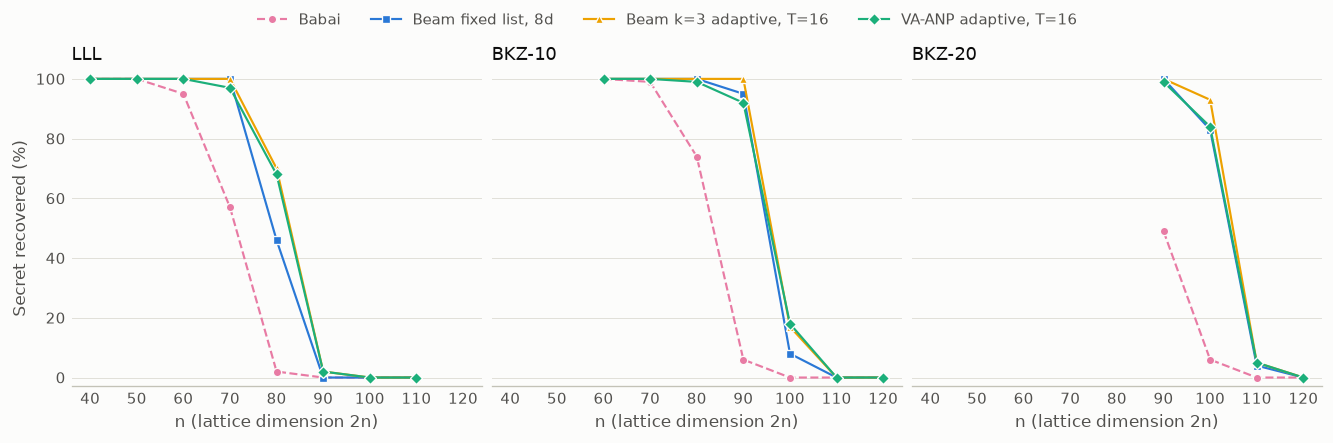

| Reduction | n | Targets | Reduction s | Smallest GS norm | Babai formula | Babai | Beam fixed list, 8d | Beam k=3 adaptive, T=16 | VA-ANP adaptive, T=16 | LP per-level, 1024 |
|---|---|---|---|---|---|---|---|---|---|---|
| LLL | 40 | 100 | 1.2 | 12.54 | 100.0% | 100%, 80 | 100%, 45,823 | 100%, 80 | 100%, 80 | 100%, 72,319 |
| LLL | 50 | 100 | 3.2 | 7.73 | 100.0% | 100%, 100 | 100%, 73,023 | 100%, 100 | 100%, 100 | 100%, 93,183 |
| LLL | 60 | 100 | 8.2 | 5.18 | 94.1% | 95%, 120 | 100%, 106,623 | 100%, 222 | 100%, 133 | 100%, 113,343 |
| LLL | 70 | 100 | 7.9 | 3.36 | 47.5% | 57%, 140 | 100%, 146,527 | 100%, 8,372 | 97%, 2,015 | 92%, 134,015 |
| LLL | 80 | 100 | 12.3 | 1.89 | 1.7% | 2%, 160 | 46%, 192,767 | 70%, 144,532 | 68%, 139,722 | 19%, 154,495 |
| LLL | 90 | 100 | 18.2 | 1.31 | 0.0% | 0%, 180 | 0%, 245,407 | 2%, 229,578 | 2%, 228,525 | 0%, 174,527 |
| LLL | 100 | 100 | 39.2 | 0.88 | 0.0% | 0%, 200 | 0%, 304,447 | 0%, 320,389 | 0%, 319,158 | 0%, 195,071 |
| LLL | 110 | 25 | 139.4 | 0.64 | 0.0% | 0%, 220 | 0%, 369,887 | 0%, 413,057 | 0%, 411,855 | 0%, 216,063 |
| BKZ-10 | 60 | 100 | 10.1 | 8.49 | 100.0% | 100%, 120 | 100%, 106,623 | 100%, 120 | 100%, 120 | 100%, 113,663 |
| BKZ-10 | 70 | 100 | 10.3 | 5.70 | 98.1% | 99%, 140 | 100%, 146,527 | 100%, 163 | 100%, 142 | 100%, 134,143 |
| BKZ-10 | 80 | 100 | 36.0 | 3.89 | 67.8% | 74%, 160 | 100%, 192,767 | 100%, 1,988 | 99%, 532 | 95%, 154,239 |
| BKZ-10 | 90 | 100 | 45.9 | 2.44 | 8.4% | 6%, 180 | 95%, 245,407 | 100%, 143,250 | 92%, 119,435 | 50%, 174,975 |
| BKZ-10 | 100 | 100 | 50.5 | 1.65 | 0.0% | 0%, 200 | 8%, 304,447 | 17%, 261,409 | 18%, 259,919 | 3%, 195,583 |
| BKZ-10 | 110 | 100 | 77.5 | 1.13 | 0.0% | 0%, 220 | 0%, 369,887 | 0%, 364,437 | 0%, 362,881 | 0%, 215,679 |
| BKZ-10 | 120 | 75 | 183.7 | 0.72 | 0.0% | 0%, 240 | 0%, 441,727 | 0%, 483,290 | 0%, 481,545 | 0%, 236,543 |
| BKZ-20 | 90 | 100 | 43.6 | 3.31 | 48.8% | 49%, 180 | 100%, 245,407 | 100%, 8,590 | 99%, 2,216 | 86%, 175,103 |
| BKZ-20 | 100 | 100 | 44.2 | 2.28 | 4.0% | 6%, 200 | 83%, 304,447 | 93%, 189,758 | 84%, 171,337 | 28%, 195,199 |
| BKZ-20 | 110 | 100 | 103.0 | 1.59 | 0.0% | 0%, 220 | 4%, 369,887 | 5%, 322,208 | 5%, 320,467 | 0%, 215,935 |
| BKZ-20 | 120 | 75 | 181.2 | 1.05 | 0.0% | 0%, 240 | 0%, 441,727 | 0%, 444,658 | 0%, 442,762 | 0%, 236,543 |

In [17]:
RED = {2: "LLL", 10: "BKZ-10", 20: "BKZ-20"}
LINES = {"Babai": ("#e87ba4", "o", "--"), "Beam fixed list, 8d": ("#2a78d6", "s", "-"),
         "Beam k=3 adaptive, T=16": ("#eda100", "^", "-"), "VA-ANP adaptive, T=16": ("#1baf7a", "D", "-")}
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6), dpi=120, sharex=True, sharey=True, constrained_layout=True, facecolor=SURFACE)
for ax, beta in zip(axes, RED):
    ax.set_facecolor(SURFACE)
    pts = sorted((p for p in PILOT if p["beta"] == beta), key=lambda p: p["n"])
    for name, (color, marker, style) in LINES.items():
        ax.plot([p["n"] for p in pts], [p["rec"][name][0] for p in pts], color=color, marker=marker, linestyle=style,
                markersize=5, markeredgecolor=SURFACE, markeredgewidth=0.8, linewidth=1.3, label=name)
    ax.set_title(RED[beta], loc="left", color="#0b0b0b", fontsize=11)
    ax.set_xlabel("n (lattice dimension 2n)", color=INK, fontsize=10)
    ax.set_ylim(-3, 103)
    ax.grid(True, axis="y", color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)
    ax.tick_params(colors=INK, labelsize=9, length=0)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(AXIS)
axes[0].set_ylabel("Secret recovered (%)", color=INK, fontsize=10)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper center", ncol=4, frameon=False, fontsize=9, labelcolor=INK)
plt.show()

table(["Reduction", "n", "Targets", "Reduction s", "Smallest GS norm", "Babai formula", *PILOT[0]["rec"]],
      [[RED[p["beta"]], p["n"], p["targets"], f"{p['reduce_s']:.1f}", f"{p['gs_min']:.2f}", f"{p['formula']:.1f}%",
        *[f"{v[0]:.0f}%, {v[1]:,.0f}" for v in p["rec"].values()]] for p in PILOT])

Cells are recovery and mean nodes. **Babai formula** is the textbook success probability for Gaussian noise, computed from each basis; the measured Babai column should track it, and does. Reduction times are from WSL with 18 lattices reducing at once, so they're rough.

### Tuned decoders on held-out lattices

Each family's cheapest setting within 3 points of the best tuning recovery at that setting, chosen on 6 tuning lattices and scored once on 16 held-out lattices (400 targets per setting). Cells: mean nodes, then held-out recovery.

In [18]:
SETTINGS = LWE["settings"]
name = lambda s: f"{RED[s['beta']]} n={s['n']}"
fams = list(SETTINGS[0]["families"])
rows = [["Babai"] + [f"{s['babai']:.1f}%" for s in SETTINGS]]
for f in fams[1:]:
    rows.append([f] + ["cannot reach" if s["families"][f] is None else
                       f"{s['families'][f]['nodes']:,.0f}, {s['families'][f]['held_out']:.1f}%" for s in SETTINGS])
rows.insert(0, ["Target on tuning"] + [f"{s['target']:.1f}%" for s in SETTINGS])
table(["Decoder"] + [name(s) for s in SETTINGS], rows)
table(["Setting", "Picked configurations"], [[name(s), "; ".join(f"{f}: `{s['families'][f]['cfg']}`" for f in fams
                                                                  if s["families"][f])] for s in SETTINGS])

| Decoder | LLL n=70 | LLL n=80 | BKZ-10 n=80 | BKZ-10 n=100 | BKZ-20 n=90 | BKZ-20 n=100 |
|---|---|---|---|---|---|---|
| Target on tuning | 97.0% | 83.0% | 97.0% | 19.7% | 97.0% | 89.0% |
| Babai | 44.0% | 1.5% | 65.2% | 0.0% | 49.5% | 4.0% |
| Beam fixed list | 18,735, 98.8% | cannot reach | 24,575, 100.0% | 2,397,183, 22.8% | 31,215, 100.0% | cannot reach |
| Beam k=3 fixed list | 19,021, 99.5% | 1,556,081, 85.0% | 24,921, 100.0% | 2,454,641, 25.5% | 31,621, 100.0% | 1,232,080, 93.2% |
| ANP fixed list | 36,765, 98.0% | cannot reach | 46,629, 98.5% | cannot reach | 59,716, 94.0% | cannot reach |
| VA-ANP fixed list | 37,503, 100.0% | cannot reach | 41,776, 98.0% | cannot reach | 59,706, 96.0% | 1,232,045, 93.2% |
| Beam adaptive | 2,261, 99.2% | cannot reach | 177, 95.0% | 451,979, 22.8% | 554, 98.5% | cannot reach |
| Beam k=3 adaptive | 2,690, 100.0% | 206,347, 84.0% | 177, 95.0% | 452,170, 25.5% | 568, 98.5% | 234,687, 94.2% |
| VA-ANP adaptive | 2,530, 100.0% | 206,187, 84.0% | 177, 95.0% | 408,861, 21.8% | 441, 94.8% | 234,312, 94.2% |
| LP per-level | cannot reach | cannot reach | 609,919, 97.2% | cannot reach | 10,807,295, 98.2% | cannot reach |

| Setting | Picked configurations |
|---|---|
| LLL n=70 | Beam fixed list: `('beam', 2, 1)`; Beam k=3 fixed list: `('beam', 3, 1)`; ANP fixed list: `('anp', 0.2, 2)`; VA-ANP fixed list: `('va', 8.0, 2)`; Beam adaptive: `('beam_T', 2, 12.0, 64)`; Beam k=3 adaptive: `('beam_T', 3, 12.0, 64)`; VA-ANP adaptive: `('va_T', 8.0, 12.0, 64)` |
| LLL n=80 | Beam k=3 fixed list: `('beam', 3, 64)`; Beam k=3 adaptive: `('beam_T', 3, 12.0, 64)`; VA-ANP adaptive: `('va_T', 8.0, 12.0, 64)` |
| BKZ-10 n=80 | Beam fixed list: `('beam', 2, 1)`; Beam k=3 fixed list: `('beam', 3, 1)`; ANP fixed list: `('anp', 0.5, 2)`; VA-ANP fixed list: `('va', 4.0, 2)`; Beam adaptive: `('beam_T', 2, 4.0, 64)`; Beam k=3 adaptive: `('beam_T', 3, 4.0, 64)`; VA-ANP adaptive: `('va_T', 4.0, 4.0, 64)`; LP per-level: `('lp', 4096)` |
| BKZ-10 n=100 | Beam fixed list: `('beam', 2, 64)`; Beam k=3 fixed list: `('beam', 3, 64)`; Beam adaptive: `('beam_T', 2, 16.0, 64)`; Beam k=3 adaptive: `('beam_T', 3, 12.0, 64)`; VA-ANP adaptive: `('va_T', 2.2, 12.0, 64)` |
| BKZ-20 n=90 | Beam fixed list: `('beam', 2, 1)`; Beam k=3 fixed list: `('beam', 3, 1)`; ANP fixed list: `('anp', 0.5, 2)`; VA-ANP fixed list: `('va', 4.0, 2)`; Beam adaptive: `('beam_T', 2, 8.0, 64)`; Beam k=3 adaptive: `('beam_T', 3, 8.0, 64)`; VA-ANP adaptive: `('va_T', 4.0, 8.0, 64)`; LP per-level: `('lp', 65536)` |
| BKZ-20 n=100 | Beam k=3 fixed list: `('beam', 3, 32)`; VA-ANP fixed list: `('va', 8.0, 32)`; Beam k=3 adaptive: `('beam_T', 3, 12.0, 64)`; VA-ANP adaptive: `('va_T', 8.0, 12.0, 64)` |

### Q1: does list decoding recover more secrets than Babai?

The list decoder with the highest tuning recovery against Babai, on the same held-out targets. Bonferroni alpha 0.00208.

In [19]:
table(["Setting", "Strongest list", "Babai", "List decoder", "Only list / only Babai", "p", "Difference, 95% CI", "Result"],
      [[name(s), f"`{s['q1']['cfg']}`", f"{s['babai']:.1f}%", f"{s['q1']['strongest']:.1f}%",
        f"{s['q1']['only_list']}/{s['q1']['only_babai']}", f"{s['q1']['p']:.2g}",
        f"{s['q1']['diff_ci'][0]:+.1f} to {s['q1']['diff_ci'][1]:+.1f}", "gain" if s["q1"]["gain"] else "no gain"] for s in SETTINGS])

| Setting | Strongest list | Babai | List decoder | Only list / only Babai | p | Difference, 95% CI | Result |
|---|---|---|---|---|---|---|---|
| LLL n=70 | `('va_T', 8.0, 16.0, 64)` | 44.0% | 100.0% | 224/0 | 0 | +52.2 to +59.8 | gain |
| LLL n=80 | `('va_T', 8.0, 16.0, 64)` | 1.5% | 85.0% | 334/0 | 0 | +76.2 to +89.8 | gain |
| BKZ-10 n=80 | `('va_T', 8.0, 12.0, 64)` | 65.2% | 100.0% | 139/0 | 0 | +30.5 to +39.2 | gain |
| BKZ-10 n=100 | `('va_T', 4.0, 12.0, 64)` | 0.0% | 25.2% | 101/0 | 0 | +20.5 to +30.8 | gain |
| BKZ-20 n=90 | `('beam_T', 2, 12.0, 64)` | 49.5% | 100.0% | 202/0 | 0 | +46.2 to +54.8 | gain |
| BKZ-20 n=100 | `('va_T', 8.0, 12.0, 64)` | 4.0% | 94.2% | 361/0 | 0 | +87.8 to +92.8 | gain |

### Q2: does VA-ANP adaptive beat the baselines?

The rule set before the run: at least 1.5x fewer nodes than the baseline with no significant loss of recovery. A nodes ratio above 1 means VA-ANP adaptive used fewer. Where a baseline couldn't reach the target on tuning data, VA-ANP adaptive wins by default.

In [20]:
rows = []
for s in SETTINGS:
    for base, q in s["q2"].items():
        if "ratio" in q:
            rows.append([name(s), base, f"{q['ratio']:.2f}x ({q['ratio_ci'][0]:.2f}-{q['ratio_ci'][1]:.2f})",
                         f"{q['base_only']}/{q['va_only']}", f"{q['p']:.2g}", "WIN" if q["win"] else "no win"])
        else:
            rows.append([name(s), base, q["why"], "", "", "WIN" if q["win"] else "no win"])
table(["Setting", "Baseline", "Nodes ratio (95% CI)", "Baseline-only / VA-only", "p", "Result"], rows)
print(f"VA-ANP adaptive wins against all three baselines at {LWE['q2_wins']} of {len(SETTINGS)} settings: "
      f"rule {'PASSED' if LWE['rule_passed'] else 'FAILED'}")

| Setting | Baseline | Nodes ratio (95% CI) | Baseline-only / VA-only | p | Result |
|---|---|---|---|---|---|
| LLL n=70 | Beam fixed list | 7.41x (6.04-9.19) | 0/5 | 0.062 | WIN |
| LLL n=70 | Beam adaptive | 0.89x (0.87-0.92) | 0/3 | 0.25 | no win |
| LLL n=70 | LP per-level | baseline cannot reach the target |  |  | WIN |
| LLL n=80 | Beam fixed list | baseline cannot reach the target |  |  | WIN |
| LLL n=80 | Beam adaptive | baseline cannot reach the target |  |  | WIN |
| LLL n=80 | LP per-level | baseline cannot reach the target |  |  | WIN |
| BKZ-10 n=80 | Beam fixed list | 138.81x (137.14-140.50) | 20/0 | 0 | no win |
| BKZ-10 n=80 | Beam adaptive | 1.00x (1.00-1.00) | 0/0 | 1 | no win |
| BKZ-10 n=80 | LP per-level | 3445.09x (3403.61-3486.83) | 17/8 | 0.11 | WIN |
| BKZ-10 n=100 | Beam fixed list | 5.86x (5.76-5.97) | 14/10 | 0.54 | WIN |
| BKZ-10 n=100 | Beam adaptive | 1.11x (1.09-1.12) | 14/10 | 0.54 | no win |
| BKZ-10 n=100 | LP per-level | baseline cannot reach the target |  |  | WIN |
| BKZ-20 n=90 | Beam fixed list | 70.76x (67.81-74.66) | 21/0 | 0 | no win |
| BKZ-20 n=90 | Beam adaptive | 1.26x (1.24-1.27) | 15/0 | 6e-05 | no win |
| BKZ-20 n=90 | LP per-level | 24499.67x (23486.82-25843.63) | 21/7 | 0.013 | WIN |
| BKZ-20 n=100 | Beam fixed list | baseline cannot reach the target |  |  | WIN |
| BKZ-20 n=100 | Beam adaptive | baseline cannot reach the target |  |  | WIN |
| BKZ-20 n=100 | LP per-level | baseline cannot reach the target |  |  | WIN |

VA-ANP adaptive wins against all three baselines at 2 of 6 settings: rule FAILED


### Exploratory: list decoding against stronger reduction

Not part of the rule. Seconds per recovered secret = (reduction + decoding) / recovery, on held-out lattices. Decoding times are from the GPU, and reduction times from WSL with other reductions running at once, so read this as rough.

In [21]:
table(["n", "Reduction", "Decoder", "Recovery", "Reduction s", "Decode s", "s per secret"],
      [[e["n"], RED[e["beta"]], e["decoder"], f"{e['recovery']:.1f}%", f"{e['reduce_s']:.1f}", f"{e['decode_s']:.3f}",
        "none recovered" if e["sec_per_secret"] is None else f"{e['sec_per_secret']:.1f}"] for e in LWE["effort"]])

| n | Reduction | Decoder | Recovery | Reduction s | Decode s | s per secret |
|---|---|---|---|---|---|---|
| 70 | LLL | Babai | 44.0% | 1.7 | 0.005 | 3.9 |
| 70 | LLL | Beam adaptive | 99.2% | 1.7 | 0.007 | 1.7 |
| 70 | LLL | Beam k=3 adaptive | 100.0% | 1.7 | 0.007 | 1.7 |
| 70 | LLL | VA-ANP adaptive | 100.0% | 1.7 | 0.009 | 1.7 |
| 70 | LLL | Strongest list | 100.0% | 1.7 | 0.008 | 1.7 |
| 70 | BKZ-10 | Babai | 98.0% | 6.3 | 0.004 | 6.4 |
| 70 | BKZ-20 | Babai | 99.8% | 9.6 | 0.005 | 9.6 |
| 80 | LLL | Babai | 1.5% | 3.0 | 0.005 | 197.4 |
| 80 | LLL | Beam k=3 adaptive | 84.0% | 3.0 | 0.025 | 3.5 |
| 80 | LLL | VA-ANP adaptive | 84.0% | 3.0 | 0.025 | 3.5 |
| 80 | LLL | Strongest list | 85.0% | 3.0 | 0.031 | 3.5 |
| 80 | BKZ-10 | Babai | 65.2% | 11.3 | 0.006 | 17.4 |
| 80 | BKZ-10 | Beam adaptive | 95.0% | 11.3 | 0.008 | 11.9 |
| 80 | BKZ-10 | Beam k=3 adaptive | 95.0% | 11.3 | 0.008 | 11.9 |
| 80 | BKZ-10 | VA-ANP adaptive | 95.0% | 11.3 | 0.009 | 11.9 |
| 80 | BKZ-10 | LP per-level | 97.2% | 11.3 | 0.040 | 11.7 |
| 80 | BKZ-10 | Strongest list | 100.0% | 11.3 | 0.009 | 11.3 |
| 80 | BKZ-20 | Babai | 94.2% | 14.4 | 0.005 | 15.3 |
| 90 | BKZ-20 | Babai | 49.5% | 21.3 | 0.006 | 43.0 |
| 90 | BKZ-20 | Beam adaptive | 98.5% | 21.3 | 0.010 | 21.6 |
| 90 | BKZ-20 | Beam k=3 adaptive | 98.5% | 21.3 | 0.010 | 21.6 |
| 90 | BKZ-20 | VA-ANP adaptive | 94.8% | 21.3 | 0.011 | 22.5 |
| 90 | BKZ-20 | LP per-level | 98.2% | 21.3 | 0.763 | 22.4 |
| 90 | BKZ-20 | Strongest list | 100.0% | 21.3 | 0.010 | 21.3 |
| 100 | BKZ-10 | Babai | 0.0% | 31.7 | 0.007 | none recovered |
| 100 | BKZ-10 | Beam adaptive | 22.8% | 31.7 | 0.051 | 139.7 |
| 100 | BKZ-10 | Beam k=3 adaptive | 25.5% | 31.7 | 0.053 | 124.6 |
| 100 | BKZ-10 | VA-ANP adaptive | 21.8% | 31.7 | 0.046 | 146.1 |
| 100 | BKZ-10 | Strongest list | 25.2% | 31.7 | 0.052 | 125.9 |
| 100 | BKZ-20 | Babai | 4.0% | 33.4 | 0.006 | 836.2 |
| 100 | BKZ-20 | Beam k=3 adaptive | 94.2% | 33.4 | 0.030 | 35.5 |
| 100 | BKZ-20 | VA-ANP adaptive | 94.2% | 33.4 | 0.030 | 35.5 |
| 100 | BKZ-20 | Strongest list | 94.2% | 33.4 | 0.030 | 35.5 |

### What the toy LWE test shows

- **List decoding recovers far more secrets than Babai (Q1: yes, at all 6 settings).** The smallest gain is at BKZ-10 n=100, where the 95% interval for the difference starts at +20.5 points. Past Babai's edge the gap is large: after LLL at n=80, 85.0% against 1.5%, and after BKZ-20 at n=100, 94.2% against 4.0%.
- **VA-ANP adaptive fails the rule (Q2: 2 of 6 settings, and it needed 4).** Both wins are by default: at LLL n=80 and BKZ-20 n=100 no baseline reached the target on tuning data. Wherever Beam adaptive did reach it, VA-ANP adaptive never used 1.5x fewer nodes without a loss: 0.89x at LLL n=70, 1.00x at BKZ-10 n=80, 1.11x at BKZ-10 n=100, and 1.26x at BKZ-20 n=90 with a significant loss (15 targets only Beam recovered, 0 the other way).
- **The two default wins come from the third plane, not from VA-ANP's rule.** At both settings, Beam with 3 planes and the same pruning got the same held-out recovery, with nodes within 0.2% of VA-ANP adaptive (206,347 against 206,187, and 234,687 against 234,312). The picked VA-ANP setting there has `llr = 8`, which keeps the third plane almost always, so it behaves like 3-plane Beam. This repeats section 5's dimension-40 lead on fresh data, in the LWE setting.
- **Pruning is what saves nodes.** For the same 3-plane decoder at the three hardest settings (LLL n=80, BKZ-10 n=100, BKZ-20 n=100), the pruned list used 5.2x-7.5x fewer nodes than the cheapest fixed list that reached the target, with held-out recovery within 1 point. This is outside the rule and wasn't significance-tested.
- **Per-level Lindner-Peikert did poorly here.** It reached the target at 2 of 6 settings, and at BKZ-20 n=90 it needed 10.8 million nodes where pruned Beam needed 554. Its budgets stop at 65,536 leaves, and it was designed for much larger BKZ-reduced instances, so this doesn't carry over to that setting.
- **Babai matches its textbook formula** at every setting (measured against predicted: 44.0% and 45.8%, 1.5% and 3.0%, 65.2% and 66.8%, 0.0% and 0.1%, 49.5% and 49.3%, 4.0% and 4.0%). That's an independent check that the instances and bases are what they should be.

**Exploratory: list decoding against stronger reduction.** At n=70, LLL plus pruned Beam recovered 99-100% at 1.7 s per secret, while BKZ-20 plus Babai got 99.8% at 9.6 s. At n=80, LLL plus a pruned 3-plane list recovered 84% at 3.5 s per secret, while BKZ-10 plus Babai got 65.2% at 17.4 s and BKZ-20 plus Babai 94.2% at 15.3 s. So at these toy sizes, a good list decoder after LLL beat BKZ-10 with Babai and came close to BKZ-20 with Babai, in less time. No setting here went past BKZ-20.

Decoding times in that table are GPU times. The GPU benchmark run for this project found it at most about 40x faster than one CPU core. Even 40x slower, decoding stays cheaper than reduction for every pick except LP per-level at BKZ-20 n=90, so the comparison holds on a CPU. Reduction times were measured with up to 18 reductions running at once.

## 7. Checks on the statements in this notebook

In [22]:
dims = {d["dim"]: d for d in FULL}

# The rule fails at dimensions 30 and 40.
for dim in (30, 40):
    m = dims[dim]["margins"]
    assert m["0.01"]["picks"]["VA-ANP adaptive"] is None
    c = m["0.03"]["vs"]["Beam fixed list"]
    assert not c["passes_rule"] and c["significant_loss"]
    n = c["noise"]
    assert n["0.18"]["base_only"] > n["0.18"]["va_only"] and n["0.18"]["p"] < 0.0083, "loss at noise 0.18"
    assert n["0.24"]["va_only"] > n["0.24"]["base_only"] and n["0.24"]["p"] < 0.0083, "gain at noise 0.24"
p30, p40 = dims[30]["margins"]["0.03"]["picks"], dims[40]["margins"]["0.03"]["picks"]
assert round(p30["VA-ANP adaptive"]["nodes"] / p30["Beam fixed list"]["nodes"], 1) == 5.5
assert round(p40["VA-ANP adaptive"]["nodes"] / p40["Beam fixed list"]["nodes"] - 1, 2) == 0.03

# Code speed.
ups = [s["speedup"] for d in FULL for s in d["speed"].values()]
assert round(min(ups), 2) == 1.45 and round(max(ups), 1) == 11.2

# Pruning at noise 0.18.
low = [r for r in BY_NOISE if r["noise"] == 0.18]
pairs = [(r["picks"]["Beam fixed list"], r["picks"]["Beam adaptive"]) for r in low]
saved = [a["nodes"] / b["nodes"] for a, b in pairs]
assert len(pairs) == 6 and round(min(saved), 2) == 1.08 and round(max(saved), 2) == 2.74
assert max(abs(a["test_acc"] - b["test_acc"]) for a, b in pairs) <= 1.7
costlier = [r for r in BY_NOISE if r["noise"] == 0.3 and r["dim"] in (30, 40) and r["picks"]["Beam fixed list"]]
assert costlier and all(r["picks"]["Beam adaptive"]["nodes"] > r["picks"]["Beam fixed list"]["nodes"] for r in costlier)

# The plane rule.
both = [r for r in BY_NOISE if r["dim"] == 16 and r["picks"]["VA-ANP adaptive"] and r["picks"]["Beam adaptive"]]
assert len(both) == 5 and all(r["picks"]["VA-ANP adaptive"]["nodes"] == r["picks"]["Beam adaptive"]["nodes"] for r in both)
for r in low:
    if r["dim"] in (30, 40):
        assert r["picks"]["VA-ANP adaptive"] is None and r["picks"]["Beam adaptive"] is not None

# Dimension 40, noise 0.24.
P = {r["cfg"]: r for r in PLANES}
va8, b3, b2 = P["('va_T', 4.0, 8)"], P["('beam3_T', 8)"], P["('beam', 2, 64)"]
assert round(b3["test_acc"], 1) == 61.5 and round(b3["nodes"]) == 24872 and round(b3["p"], 2) == 0.27
assert round(va8["test_acc"], 1) == 60.7 and round(va8["nodes"]) == 24093
assert round(b2["test_acc"], 1) == 61.3 and round(b2["nodes"]) == 75775

# Beam against the bound at dimension 30.
assert round(max(r["test_acc"] for r in dims[30]["rows"] if r["kind"] == "beam"), 1) == 61.7
assert round(dims[30]["ceiling_upper"], 1) == 61.8
print("The Main results numbers from these runs match the data above.")
print("The 2.6x row comes from earlier runs: stress_test_results.txt and stress_test_per_noise_results.txt.")


# Section 6, toy LWE.
S = {(s["beta"], s["n"]): s for s in LWE["settings"]}
assert len(S) == 6 and all(s["targets"] == 400 for s in S.values())
assert LWE["bad_points"] == 0 and all(p["bad"] == 0 for p in PILOT), "a wrong closer point or a point off the lattice"
assert all(abs(s["babai"] - s["babai_formula"]) < 2 for s in S.values()), "Babai doesn't track its formula"

# Q1: a significant gain everywhere.
assert LWE["q1_gains"] == 6 and round(min(s["q1"]["diff_ci"][0] for s in S.values()), 1) == 20.5
pct = lambda x: f"{x:.1f}"  # as the tables show it; 400 targets give quarter points
assert (pct(S[2, 80]["q1"]["strongest"]), pct(S[2, 80]["babai"])) == ("85.0", "1.5")
assert (pct(S[20, 100]["q1"]["strongest"]), pct(S[20, 100]["babai"])) == ("94.2", "4.0")
assert [(pct(s["babai"]), pct(s["babai_formula"])) for s in S.values()] == [
    ("44.0", "45.8"), ("1.5", "3.0"), ("65.2", "66.8"), ("0.0", "0.1"), ("49.5", "49.3"), ("4.0", "4.0")]

# Q2: fails; the two wins are default wins, matched by 3-plane Beam.
assert LWE["q2_wins"] == 2 and not LWE["rule_passed"]
for key in ((2, 80), (20, 100)):
    s = S[key]
    assert s["q2_all_three"] and all("why" in q for q in s["q2"].values())
    va, b3 = s["families"]["VA-ANP adaptive"], s["families"]["Beam k=3 adaptive"]
    assert va["held_out"] == b3["held_out"] and abs(va["nodes"] / b3["nodes"] - 1) < 0.002 and "8.0" in va["cfg"]
vs_beam = {k: S[k]["q2"]["Beam adaptive"] for k in ((2, 70), (10, 80), (10, 100), (20, 90))}
assert [round(q["ratio"], 2) for q in vs_beam.values()] == [0.89, 1.0, 1.11, 1.26]
assert vs_beam[20, 90]["significant_loss"] and (vs_beam[20, 90]["base_only"], vs_beam[20, 90]["va_only"]) == (15, 0)

# Pruning, and LP per-level.
hard = [S[k]["families"] for k in ((2, 80), (10, 100), (20, 100))]
saved = [f["Beam k=3 fixed list"]["nodes"] / f["Beam k=3 adaptive"]["nodes"] for f in hard]
assert round(min(saved), 1) == 5.2 and round(max(saved), 1) == 7.5
assert all(abs(f["Beam k=3 fixed list"]["held_out"] - f["Beam k=3 adaptive"]["held_out"]) <= 1 for f in hard)
assert sum(s["families"]["LP per-level"] is not None for s in S.values()) == 2
assert round(S[20, 90]["families"]["LP per-level"]["nodes"] / 1e6, 1) == 10.8
assert round(S[20, 90]["families"]["Beam adaptive"]["nodes"]) == 554

# Exploratory timings quoted in the text.
E = {(e["n"], e["beta"], e["decoder"]): e for e in LWE["effort"]}
quoted = {(70, 2, "Beam adaptive"): 1.7, (70, 20, "Babai"): 9.6, (80, 2, "Beam k=3 adaptive"): 3.5,
          (80, 10, "Babai"): 17.4, (80, 20, "Babai"): 15.3}
assert all(round(E[k]["sec_per_secret"], 1) == v for k, v in quoted.items())
assert [pct(E[k]["recovery"]) for k in ((70, 20, "Babai"), (80, 2, "Beam k=3 adaptive"), (80, 10, "Babai"), (80, 20, "Babai"))] \
    == ["99.8", "84.0", "65.2", "94.2"]
assert all(40 * e["decode_s"] < e["reduce_s"] for e in LWE["effort"] if e["decoder"] != "LP per-level")
assert 40 * E[90, 20, "LP per-level"]["decode_s"] > E[90, 20, "LP per-level"]["reduce_s"]
print("The toy LWE numbers in section 6 and in Main results match the embedded data.")

The Main results numbers from these runs match the data above.
The 2.6x row comes from earlier runs: stress_test_results.txt and stress_test_per_noise_results.txt.
The toy LWE numbers in section 6 and in Main results match the embedded data.


## What the results support

> CVP/BDD decoding is the last step of the primal lattice attack on LWE. Its hardness helps protect ML-KEM, so it isn't a vulnerability. We benchmarked list decoders for that step on random q-ary lattices (q = 3329, dimensions 16-40). A matrix-based rewrite made them 1.5x-11x faster with the same output. Against ANP at one fixed threshold, VA-ANP does less work at moderate noise on dimensions 10-16 and needs no threshold retuning. With list sizes tuned, it doesn't beat a plain beam at larger dimensions. Pruning the candidate list by likelihood used up to 2.7x fewer nodes at low noise. On toy LWE instances (n up to 100, eta = 2), list decoding recovered far more secrets than Babai at every setting tested. Pruned 3-plane lists reached the target at every setting, at or near the fewest nodes. VA-ANP's plane rule added nothing over a plain third plane there either. None of this is about real ML-KEM parameters.

| Earlier wording | Problem | Use instead |
|---|---|---|
| "CVP is a vulnerability of ML-KEM" | CVP being hard is what protects ML-KEM | "CVP/BDD decoding is the last step of the primal lattice attack on LWE" |
| "Improving existing version" | The existing version is `cvp_improved.py`. Its own header says adaptive branching isn't novel and is known from MIMO detection. Its "Lindner-Peikert" is a beam search, as its docstring says | "Compared against the ANP baseline from `cvp_improved.py`", without calling the idea new |
| "Higher speed" | The 2.6x holds only against threshold 0.35 on dimensions 10-16 | The code speedup, and the VA-ANP result stated separately, as above |

### Related work to check before calling anything new

- **Lindner and Peikert (2011), NearestPlanes.** It sets the planes per level from `||b*_i||`, and notes the choice can be tailored to a known error distribution. So noise-awareness isn't new to VA-ANP.
- **Liu and Nguyen (2013).** BDD enumeration with pruning. Only the abstract was checked.
- **M-algorithm and T-algorithm in trellis decoding (Simmons, 1990).** Beam looks like the M-algorithm and the list pruning looks like the T-algorithm. The search didn't confirm the T-algorithm's exact threshold rule, so read the paper before citing it.

### Limits

- Sections 4 and 5 aren't LWE instances, and their bases are LLL-reduced only.
- The LWE test uses toy sizes only: n up to 100, m = n samples, eta = 2, and BKZ up to block size 20 without pruning strategies. It doesn't compare against Kannan's embedding with a stronger BKZ, which is how real primal attacks usually finish. Real ML-KEM parameters are far out of reach of anything here.
- In section 6, decoding times are GPU times and reduction times were measured with up to 18 reductions running at once. The time comparison with stronger BKZ is exploratory.
- 3-plane Beam with pruning was confirmed on fresh LWE data. It hasn't been retested on fresh data in the random-lattice setting of section 5, where it was found.
- The per-noise follow-up and the dimension 40 test came after the rule failed, so they're exploratory.
- Lindner-Peikert NearestPlanes was designed for BKZ-reduced bases at much larger sizes, so its low scores here don't carry over to that setting.

## References

ANP and VA-ANP have no paper of their own: ANP comes from `cvp_improved.py`, and VA-ANP is a variant of it. Check volumes and pages against the publisher before citing.

**Decoders compared**

1. L. Babai. On Lovász' lattice reduction and the nearest lattice point problem. *Combinatorica* 6(1), 1986. (Babai nearest plane)
2. R. Lindner, C. Peikert. Better Key Sizes (and Attacks) for LWE-Based Encryption. CT-RSA 2011. [ePrint 2010/613](https://eprint.iacr.org/2010/613), [author's copy](https://web.eecs.umich.edu/%7Ecpeikert/pubs/lwe-analysis.pdf). (NearestPlanes with planes chosen per level; the closest published idea to VA-ANP)
3. K.-W. Wong, C.-Y. Tsui, R. S.-K. Cheng, W.-H. Mow. A VLSI architecture of a K-best lattice decoding algorithm for MIMO channels. ISCAS 2002. (Beam with a fixed list)
4. E. Agrell, T. Eriksson, A. Vardy, K. Zeger. Closest point search in lattices. *IEEE Trans. Inf. Theory* 48(8), 2002. (Exact CVP by enumeration, zig-zag plane order)
5. U. Fincke, M. Pohst. Improved methods for calculating vectors of short length in a lattice, including a complexity analysis. *Math. Comp.* 44(170), 1985. (Sphere decoding)
6. M-algorithm and T-algorithm in trellis decoding, e.g. S. J. Simmons, 1990: [sorting-based architectures](https://data.zhenzhi.com/details/1/987650143/1/2). (Beam and likelihood pruning look like these; the T-algorithm's exact rule wasn't confirmed, so read it before citing)

**Basis reduction**

7. A. K. Lenstra, H. W. Lenstra Jr., L. Lovász. Factoring polynomials with rational coefficients. *Math. Ann.* 261, 1982. (LLL)
8. C. P. Schnorr, M. Euchner. Lattice basis reduction: improved practical algorithms and solving subset sum problems. *Math. Programming* 66, 1994. (BKZ)
9. Y. Chen, P. Q. Nguyen. BKZ 2.0: Better Lattice Security Estimates. ASIACRYPT 2011.
10. The FPLLL development team. fplll, a lattice reduction library. [github.com/fplll/fplll](https://github.com/fplll/fplll). (Used for LLL and BKZ in section 6)

**LWE, the attack, and ML-KEM**

11. O. Regev. On lattices, learning with errors, random linear codes, and cryptography. STOC 2005; *J. ACM* 2009.
12. M. Liu, P. Q. Nguyen. Solving BDD by Enumeration: An Update. CT-RSA 2013. [DOI 10.1007/978-3-642-36095-4_19](https://doi.org/10.1007/978-3-642-36095-4_19). Only the abstract was checked.
13. R. Kannan. Minkowski's convex body theorem and integer programming. *Math. Oper. Res.* 12(3), 1987. (Embedding, not tested here)
14. M. R. Albrecht, R. Player, S. Scott. On the concrete hardness of Learning with Errors. *J. Math. Cryptology* 9(3), 2015. [ePrint 2015/046](https://eprint.iacr.org/2015/046).
15. NIST. FIPS 203: Module-Lattice-Based Key-Encapsulation Mechanism Standard. 2024. [DOI 10.6028/NIST.FIPS.203](https://doi.org/10.6028/NIST.FIPS.203).

**Statistics**

16. Q. McNemar. Note on the sampling error of the difference between correlated proportions or percentages. *Psychometrika* 12(2), 1947. (Paired test used throughout)